# Análisis bayesiano de clases latentes de los problemas asociados al consumo de marihuana en Colombia (ENCSPA 2019)

Cuaderno del proyecto de Estadística Bayesiana. Aquí está todo el proceso, desde los csv del DANE hasta las figuras y tablas del artículo: construcción de la muestra, análisis exploratorio, priors, modelo conjunto (clases latentes más regresión logística multinomial con pseudo-verosimilitud ponderada), selección de K, sensibilidad, chequeos predictivos y figuras.

Estructura de carpetas para correrlo:

```
entrega.zip
├── proyecto_bayesiana_encspa2019.ipynb
└── ENCSPA_2019/               <- solo los csv de la encuesta
    ├── personas_seleccionadas.csv
    ├── d_capitulos.csv, d2_capitulos.csv
    ├── e_capitulos.csv, f_capitulos.csv, k_capitulos.csv
    └── l_capitulos.csv, m_capitulos.csv   (solo se usan para revisar si traen variables de diseño)
```

Todo lo que genera el cuaderno (tablas, posteriores, figuras) se guarda en una carpeta nueva llamada `resultados/`, que se crea sola, así que la carpeta de datos no se toca.

Cómo correrlo: Kernel, Restart and run all. Los ajustes MCMC son lo que más tarda (K = 2 a 5, más las corridas de sensibilidad). Cada posterior se guarda en `resultados/` y si el archivo ya existe se carga en vez de volver a ajustar. Para recalcular todo desde cero se borra `resultados/` o se pone `REUSAR = False` en la primera celda de código. Todas las semillas están fijas (NUTS con `PRNGKey(0)`, numpy con semillas explícitas), pero los valores exactos del MCMC dependen de las versiones de jax y numpyro, por eso la primera celda imprime las versiones.

In [2]:
# %pip install -q numpyro==0.22.0 jax==0.11.1 arviz seaborn pandas scipy matplotlib pillow
import os
import sys
import time
import platform
import warnings
import importlib.metadata as imd

import numpyro
numpyro.set_host_device_count(4)   # tiene que ir antes de usar jax
import jax
import jax.numpy as jnp
import numpyro.distributions as npd
from numpyro.infer import MCMC, NUTS, init_to_median
import arviz as az

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import logsumexp, expit, logit

warnings.filterwarnings('ignore')

RUTA = 'ENCSPA_2019/'      # carpeta con los csv originales
SALIDA = 'resultados/'     # todo lo que genera el cuaderno
REUSAR = True              # True: si el posterior ya está guardado, se carga en vez de volver a ajustar
LLAVES = ['directorio', 'secuencia_encuesta', 'secuencia_p', 'orden']
UMBRAL_INICIO_TEMPRANO = 15

os.makedirs(SALIDA + 'figuras', exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)

obligatorios = ['personas_seleccionadas.csv', 'd_capitulos.csv', 'd2_capitulos.csv',
                'e_capitulos.csv', 'f_capitulos.csv', 'k_capitulos.csv']
faltan = [f for f in obligatorios if not os.path.exists(RUTA + f)]
if faltan:
    raise FileNotFoundError(f'No están en {RUTA}: {faltan}')


def guardar_fig(fig, nombre):
    fig.tight_layout()
    fig.savefig(SALIDA + 'figuras/' + nombre + '.png', dpi=200, bbox_inches='tight')
    plt.show()


print('Python', sys.version.split()[0], '|', platform.platform())
for pkg in ['jax', 'jaxlib', 'numpyro', 'arviz', 'numpy', 'pandas', 'scipy']:
    try:
        print(f'{pkg:8s}', imd.version(pkg))
    except Exception:
        print(f'{pkg:8s} no encontrado')
print('Dispositivos JAX:', jax.devices())

Python 3.13.14 | Windows-11-10.0.26200-SP0
jax      0.12.0.1
jaxlib   0.12.0.1
numpyro  0.22.0
arviz    1.3.0
numpy    2.3.5
pandas   3.1.1
scipy    1.16.3
Dispositivos JAX: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]


## 1. Carga de los datos

Se leen los seis archivos que entran al análisis (personas, estado de ánimo D, sociodemográficas D2, tabaco E, alcohol F y marihuana K). Los separadores no son iguales entre archivos, por eso se deja que pandas los detecte, y los números se pasan a numérico después de cambiar comas por puntos.

In [3]:
archivos = {
    'personas': 'personas_seleccionadas.csv',
    'd': 'd_capitulos.csv',
    'd2': 'd2_capitulos.csv',
    'e': 'e_capitulos.csv',
    'f': 'f_capitulos.csv',
    'k': 'k_capitulos.csv',
}

tablas = {
    nombre: pd.read_csv(RUTA + archivo, sep=None, engine='python')
    for nombre, archivo in archivos.items()
}

for t in tablas.values():
    t.columns = t.columns.str.strip().str.upper()

{nombre: t.shape for nombre, t in tablas.items()}

{'personas': (49756, 12),
 'd': (49756, 34),
 'd2': (49756, 11),
 'e': (49756, 16),
 'f': (49756, 37),
 'k': (3982, 48)}

## 2. Renombrado y tipos

Los ítems de abuso y dependencia son las 15 preguntas K_12_A a K_12_O del capítulo K. Se renombran las columnas que se van a usar y se revisa que no haya llaves duplicadas al unir los capítulos.

In [4]:
ITEMS = [
    'marihuana_problema_casa_trabajo_estudio', 'marihuana_peligro_integridad_fisica',
    'marihuana_problema_autoridad_ley', 'marihuana_problema_familia_amigos',
    'marihuana_pelea_agresion', 'marihuana_uso_para_evitar_problemas',
    'marihuana_sintomas_al_suspender', 'marihuana_deseo_incontrolable',
    'marihuana_tolerancia_menor_efecto', 'marihuana_tolerancia_mayor_cantidad',
    'marihuana_uso_a_pesar_intencion_no_hacerlo', 'marihuana_uso_mayor_cantidad_pensada',
    'marihuana_abandono_actividades', 'marihuana_mas_tiempo_consiguiendo_recuperando',
    'marihuana_continua_a_pesar_problemas_salud',
]

mapa_llaves = {
    'DIRECTORIO': 'directorio', 'SECUENCIA_ENCUESTA': 'secuencia_encuesta',
    'SECUENCIA_P': 'secuencia_p', 'ORDEN': 'orden',
}

mapas = {
    'personas': {**mapa_llaves, 'SEXO': 'sexo', 'EDAD': 'edad',
                 'CONSENTIMIENTO': 'consentimiento', 'RESULTADO': 'resultado',
                 'FEX_C': 'fex_c'},
    'd': {**mapa_llaves, 'D_09': 'animo_bajo_30d', 'D_10': 'poco_interes_placer_30d'},
    'd2': {**mapa_llaves, 'D2_01': 'autorreconocimiento_etnico', 'D2_03': 'estado_civil',
           'D2_04': 'num_hijos_vivos', 'D2_05': 'nivel_educativo'},
    'e': {**mapa_llaves, 'E_01': 'tabaco_alguna_vez', 'E_02': 'tabaco_edad_inicio'},
    'f': {**mapa_llaves, 'F_03': 'alcohol_alguna_vez', 'F_04': 'alcohol_edad_inicio'},
    'k': {**mapa_llaves, 'K_03': 'marihuana_ultimos_12_meses',
          **{f'K_12_{letra}': item for letra, item in zip('ABCDEFGHIJKLMNO', ITEMS)}},
}


def renombrar(df, mapa, nombre):
    faltan = [c for c in mapa if c not in df.columns]
    if faltan:
        raise KeyError(f'{nombre}: columnas no encontradas {faltan}')
    return df[list(mapa)].rename(columns=mapa).copy()


def a_numerico(s):
    if not pd.api.types.is_numeric_dtype(s):
        s = s.astype(str).str.strip().str.replace(',', '.', regex=False)
    return pd.to_numeric(s, errors='coerce')


tablas = {nombre: renombrar(tablas[nombre], mapas[nombre], nombre) for nombre in mapas}

for nombre, t in tablas.items():
    for c in LLAVES:
        t[c] = t[c].astype(str).str.strip().str.replace(r'\.0$', '', regex=True)
    for c in [c for c in t.columns if c not in LLAVES]:
        t[c] = a_numerico(t[c])
    if t.duplicated(LLAVES).any():
        raise ValueError(f'{nombre}: llaves duplicadas')

{nombre: t.shape for nombre, t in tablas.items()}

{'personas': (49756, 9),
 'd': (49756, 6),
 'd2': (49756, 8),
 'e': (49756, 6),
 'f': (49756, 6),
 'k': (3982, 20)}

## 3. Población de estudio

Solo se trabaja con consumidores de marihuana de los últimos 12 meses. Si se incluyera a quienes nunca consumieron aparecerían ceros estructurales, porque el cuestionario salta las preguntas de problemas cuando no hay consumo. La tabla de abajo es el flujo de la muestra (Tabla 3 del artículo).

In [5]:
registro = []


def anotar(paso, data):
    registro.append({'paso': paso, 'n': len(data)})


p = tablas['personas']
anotar('Personas en el archivo', p)

p = p[(p['consentimiento'] == 1) & (p['resultado'] == 1)]
anotar('Consentimiento y entrevista completa', p)

df = p.merge(tablas['k'], on=LLAVES, how='inner', validate='one_to_one')
anotar('Con registro en el capítulo K', df)

df = df[df['marihuana_ultimos_12_meses'] == 1]
anotar('Consumo de marihuana en los últimos 12 meses', df)

for nombre in ['d', 'd2', 'e', 'f']:
    df = df.merge(tablas[nombre], on=LLAVES, how='left', validate='one_to_one')

for c in ITEMS:
    df[c] = df[c].map({1: 1, 2: 0})

df = df.dropna(subset=ITEMS).copy()
anotar('Los 15 ítems del capítulo K completos', df)

## 4. Variables derivadas

Decisiones que se tomaron aquí: ánimo bajo y poco interés se unen en una sola variable (1 si responde sí a alguna de las dos), la edad de inicio de tabaco y alcohol se valida (positiva y no mayor que la edad actual) y se parte en 15 años, y en alcohol "nunca" se junta con "no temprano" porque solo 16 personas nunca han probado. Estado civil y educación se agrupan en las categorías de abajo.

In [6]:
ORDEN = {
    'estado_civil': ['Soltero', 'Unión libre', 'Casado', 'Separado o viudo'],
    'nivel_educativo': ['Hasta primaria', 'Secundaria', 'Media', 'Superior'],
    'tabaco_inicio': ['Nunca', 'Tardío', 'Temprano'],
    'alcohol_inicio': ['No temprano', 'Temprano'],
}

df['mujer'] = df['sexo'].map({1: 0, 2: 1})
animo = df['animo_bajo_30d'].map({1: 1, 2: 0})
interes = df['poco_interes_placer_30d'].map({1: 1, 2: 0})
df['sintomas_animo_30d'] = np.where(
    (animo == 1) | (interes == 1), 1.0,
    np.where((animo == 0) & (interes == 0), 0.0, np.nan))
df['etnia_alguna'] = df['autorreconocimiento_etnico'].map(
    {1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 9: 0})

df['estado_civil'] = df['estado_civil'].map({
    1: 'Unión libre', 2: 'Unión libre', 3: 'Casado',
    4: 'Separado o viudo', 5: 'Separado o viudo', 6: 'Soltero'})

df['nivel_educativo'] = df['nivel_educativo'].map({
    1: 'Hasta primaria', 2: 'Hasta primaria', 3: 'Hasta primaria',
    4: 'Secundaria', 5: 'Media', 6: 'Superior', 7: 'Superior', 8: 'Superior'})
df['educacion_ord'] = df['nivel_educativo'].map(
    {c: i for i, c in enumerate(ORDEN['nivel_educativo'])})


def inicio(alguna_vez, edad_inicio, edad, umbral):
    categoria = pd.Series(np.nan, index=alguna_vez.index, dtype=object)
    valida = (alguna_vez == 1) & (edad_inicio > 0) & (edad_inicio <= edad)
    categoria[alguna_vez == 2] = 'Nunca'
    categoria[valida & (edad_inicio < umbral)] = 'Temprano'
    categoria[valida & (edad_inicio >= umbral)] = 'Tardío'
    return categoria, edad_inicio.where(valida)


df['tabaco_inicio'], df['tabaco_edad_inicio_valida'] = inicio(
    df['tabaco_alguna_vez'], df['tabaco_edad_inicio'], df['edad'], UMBRAL_INICIO_TEMPRANO)
df['alcohol_inicio'], df['alcohol_edad_inicio_valida'] = inicio(
    df['alcohol_alguna_vez'], df['alcohol_edad_inicio'], df['edad'], UMBRAL_INICIO_TEMPRANO)

df['alcohol_inicio'] = df['alcohol_inicio'].map(
    {'Nunca': 'No temprano', 'Tardío': 'No temprano', 'Temprano': 'Temprano'})

df['n_problemas'] = df[ITEMS].sum(axis=1)

COV_BIN = ['mujer', 'sintomas_animo_30d', 'etnia_alguna']
COV_NUM = ['edad', 'num_hijos_vivos']
COV_CAT = ['estado_civil', 'nivel_educativo', 'tabaco_inicio', 'alcohol_inicio']
COV = COV_BIN + COV_NUM + COV_CAT

df_modelo = df.dropna(subset=COV).copy()
anotar('Covariables completas', df_modelo)

flujo = pd.DataFrame(registro)
flujo['perdidos'] = -flujo['n'].diff().fillna(0).astype(int)
flujo

,paso,n,perdidos
0,Personas en el archivo,49756,0
1,Consentimiento y entrevista completa,49756,0
2,Con registro en el capítulo K,3982,45774
3,Consumo de marihuana en los últimos 12 meses,1223,2759
4,Los 15 ítems del capítulo K completos,1223,0
5,Covariables completas,1217,6


Después de pedir covariables completas el flujo termina en 1.217 personas. Las 6 pérdidas son 5 sin dato de ánimo (0,41 %) y 1 sin nivel educativo (0,08 %), o sea que el análisis de casos completos casi no pierde información.

## 5. Valores faltantes

In [7]:
faltantes = pd.DataFrame({
    'n_faltantes': df[COV].isna().sum(),
    'pct_faltantes': (df[COV].isna().mean() * 100).round(2),
})
faltantes

,n_faltantes,pct_faltantes
mujer,0,0.00
sintomas_animo_30d,5,0.41
etnia_alguna,0,0.00
edad,0,0.00
num_hijos_vivos,0,0.00
estado_civil,0,0.00
nivel_educativo,1,0.08
tabaco_inicio,0,0.00
alcohol_inicio,0,0.00


In [8]:
pd.concat({
    'tabaco_inicio': df['tabaco_inicio'].value_counts(dropna=False),
    'alcohol_inicio': df['alcohol_inicio'].value_counts(dropna=False),
}, axis=1)

,tabaco_inicio,alcohol_inicio
Tardío,631.0,NaN
Temprano,423.0,499.0
Nunca,169.0,NaN
No temprano,NaN,724.0


## 6. Resumen estadístico

La población es joven (edad media 28,3, mediana 26), en su mayoría hombres (74,2 %), solteros (69,6 %) y con educación media o superior (75,2 %). Los porcentajes ponderados salen parecidos a los simples, así que los pesos no cambian mucho la composición de la muestra. Lo que sí cambia es la variación entre pesos: la mediana de fex_c es 367 pero el máximo llega a 5.469, de ahí la asimetría y la curtosis tan altas.

In [9]:
VARS_NUM = ['edad', 'num_hijos_vivos', 'tabaco_edad_inicio_valida',
            'alcohol_edad_inicio_valida', 'n_problemas', 'fex_c']
VARS_CAT = COV_BIN + COV_CAT


def resumen_numericas(data, columnas):
    filas = []
    for c in columnas:
        s = data[c].dropna()
        filas.append({
            'variable': c, 'n': len(s), 'media': s.mean(), 'desv_std': s.std(),
            'min': s.min(), 'p25': s.quantile(0.25), 'mediana': s.median(),
            'p75': s.quantile(0.75), 'max': s.max(),
            'asimetria': stats.skew(s), 'curtosis': stats.kurtosis(s),
        })
    return pd.DataFrame(filas).set_index('variable').round(3)


resumen_numericas(df_modelo, VARS_NUM)

,n,media,desv_std,min,p25,mediana,p75,max,asimetria,curtosis
variable,,,,,,,,,,
edad,1217,28.252,10.176,12.00,21.000,26.000,32.000,65.000,1.374,1.832
num_hijos_vivos,1217,0.583,1.062,0.00,0.000,0.000,1.000,12.000,3.048,16.218
tabaco_edad_inicio_valida,1048,15.244,3.224,3.00,13.750,15.000,17.000,38.000,0.738,4.779
alcohol_edad_inicio_valida,1201,14.744,2.877,1.00,13.000,15.000,16.000,27.000,-0.404,3.042
n_problemas,1217,3.343,3.785,0.00,0.000,2.000,5.000,15.000,1.225,0.811
fex_c,1217,521.198,525.891,3.32,164.307,366.752,677.484,5469.123,2.420,10.582


In [10]:
def tabla_frecuencias(data, columnas, peso='fex_c'):
    filas = []
    for c in columnas:
        d = data.dropna(subset=[c])
        total_peso = d[peso].sum()
        for categoria, g in d.groupby(c):
            filas.append({
                'variable': c, 'categoria': categoria, 'n': len(g),
                'pct': 100 * len(g) / len(d),
                'pct_ponderado': 100 * g[peso].sum() / total_peso,
            })
    return pd.DataFrame(filas).set_index(['variable', 'categoria']).round(2)


tabla_frecuencias(df_modelo, VARS_CAT)

n    pct  pct_ponderado
variable           categoria                                   
mujer              0                  903  74.20          75.75
                   1                  314  25.80          24.25
sintomas_animo_30d 0                  803  65.98          65.19
                   1                  414  34.02          34.81
etnia_alguna       0                 1060  87.10          88.03
                   1                  157  12.90          11.97
estado_civil       Casado              49   4.03           4.72
                   Separado o viudo    94   7.72           6.26
                   Soltero            847  69.60          71.42
                   Unión libre        227  18.65          17.60
nivel_educativo    Hasta primaria     105   8.63           6.78
                   Media              388  31.88          34.29
                   Secundaria         197  16.19          16.29
                   Superior           527  43.30          42.64
tabaco_inicio      Nunca              169  13.89          12.48
                   Tardío             627  51.52          51.59
                   Temprano           421  34.59          35.93
alcohol_inicio     No temprano        720  59.16          58.53
                   Temprano           497  40.84          41.47

In [11]:
prevalencia = pd.DataFrame({
    'n_si': df_modelo[ITEMS].sum(),
    'prevalencia': df_modelo[ITEMS].mean(),
    'prevalencia_ponderada': [
        np.average(df_modelo[c], weights=df_modelo['fex_c']) for c in ITEMS],
})
prevalencia.index = [c.replace('marihuana_', '') for c in prevalencia.index]
prevalencia.sort_values('prevalencia', ascending=False).round(3)

,n_si,prevalencia,prevalencia_ponderada
uso_a_pesar_intencion_no_hacerlo,432,0.355,0.360
uso_para_evitar_problemas,410,0.337,0.337
continua_a_pesar_problemas_salud,401,0.329,0.333
tolerancia_menor_efecto,345,0.283,0.292
problema_familia_amigos,328,0.270,0.300
uso_mayor_cantidad_pensada,312,0.256,0.252
tolerancia_mayor_cantidad,284,0.233,0.240
sintomas_al_suspender,267,0.219,0.213
deseo_incontrolable,223,0.183,0.173
problema_casa_trabajo_estudio,207,0.170,0.171


Las prevalencias por ítem van de 10,4 % (pelea o agresión) a 35,5 % (uso a pesar de la intención de no hacerlo). Ningún ítem es casi universal ni casi inexistente, entonces todos aportan para separar las clases, y la prevalencia ponderada es muy cercana a la simple.

## 7. Distribuciones

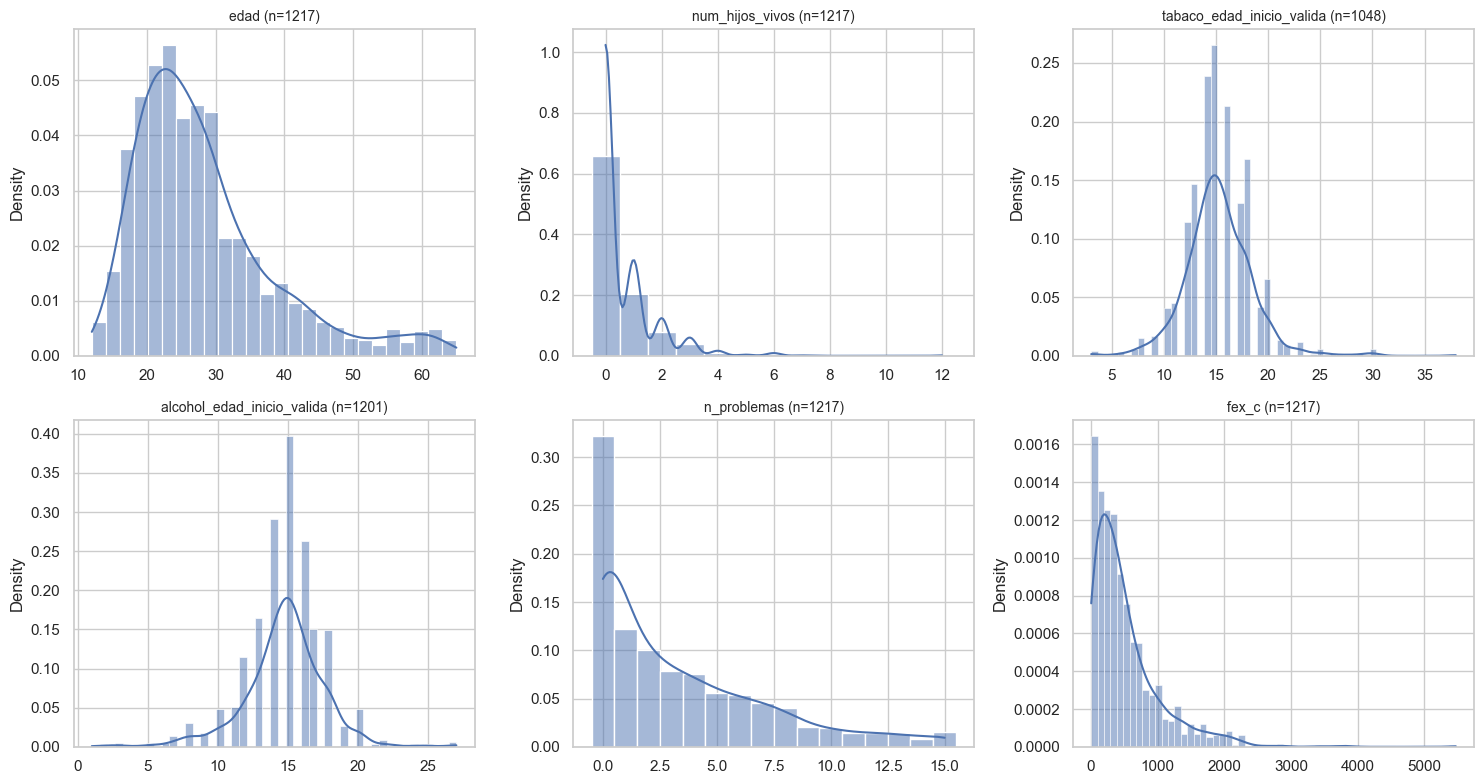

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), VARS_NUM):
    s = df_modelo[c].dropna()
    sns.histplot(s, kde=True, stat='density', discrete=c in ('num_hijos_vivos', 'n_problemas'),
                 ax=ax, color='#4c72b0')
    ax.set_title(f'{c} (n={len(s)})', fontsize=10)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

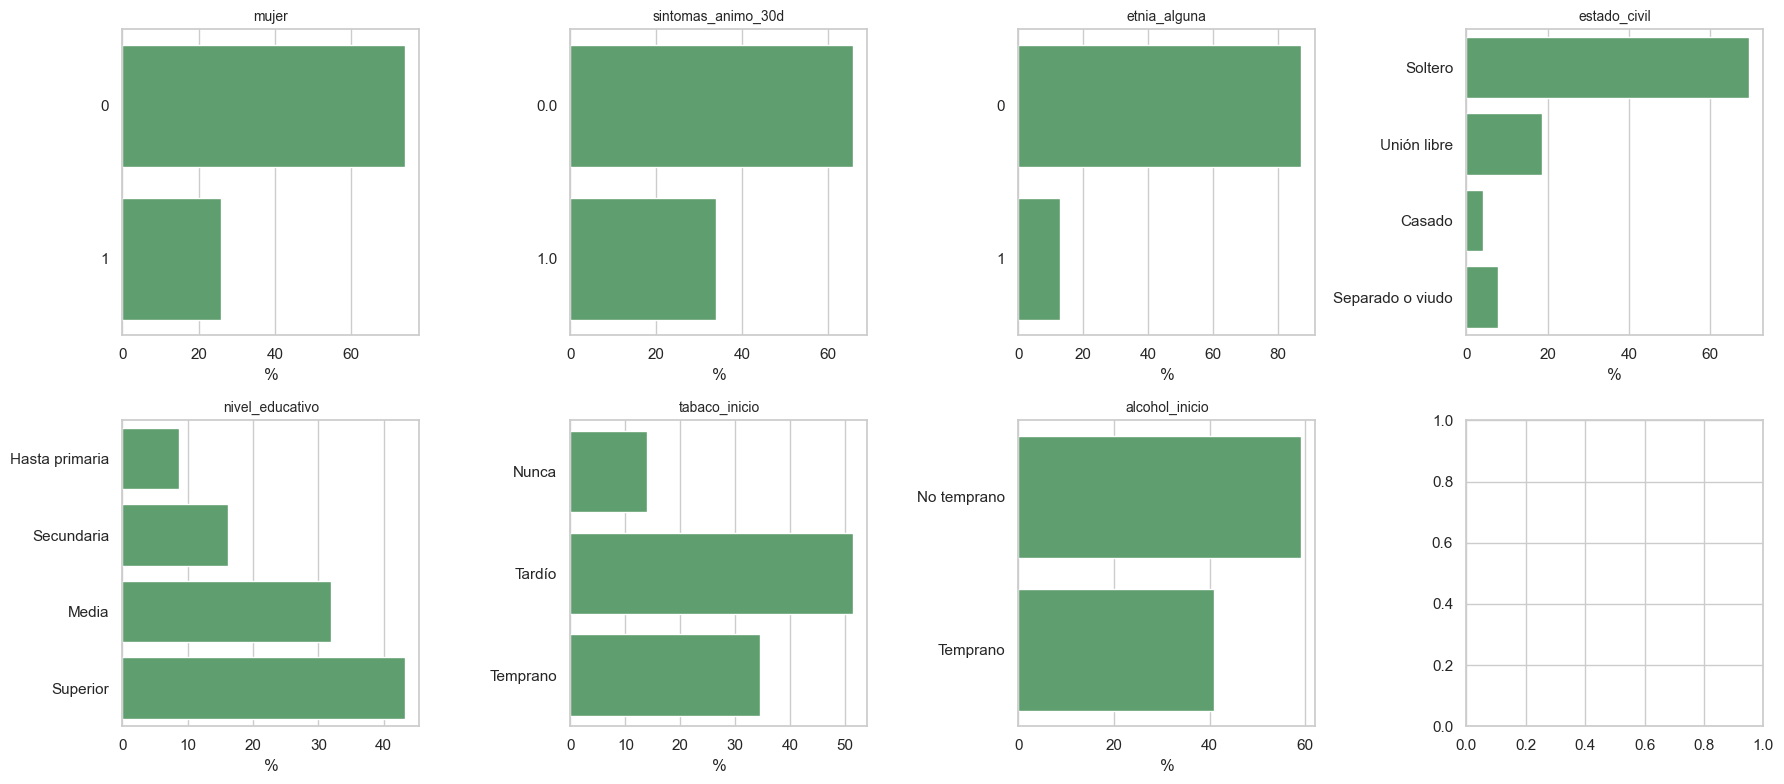

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), VARS_CAT):
    conteo = df_modelo[c].value_counts(normalize=True).mul(100)
    if c in ORDEN:
        conteo = conteo.reindex(ORDEN[c])
    sns.barplot(x=conteo.values, y=conteo.index.astype(str), ax=ax, color='#55a868')
    ax.set_title(c, fontsize=10)
    ax.set_xlabel('%')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

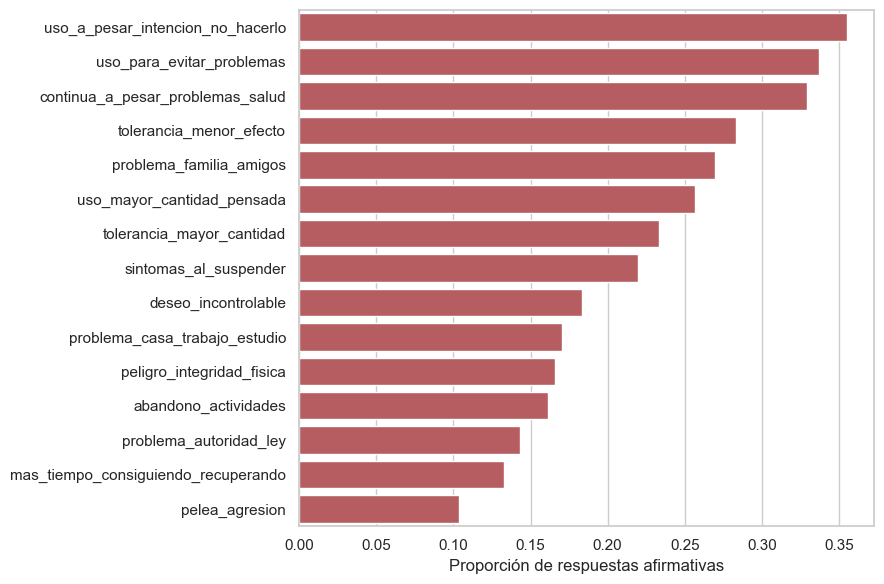

In [14]:
orden_items = prevalencia.sort_values('prevalencia', ascending=False)
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=orden_items['prevalencia'], y=orden_items.index, ax=ax, color='#c44e52')
ax.set_xlabel('Proporción de respuestas afirmativas')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## 8. Matrices de correlación

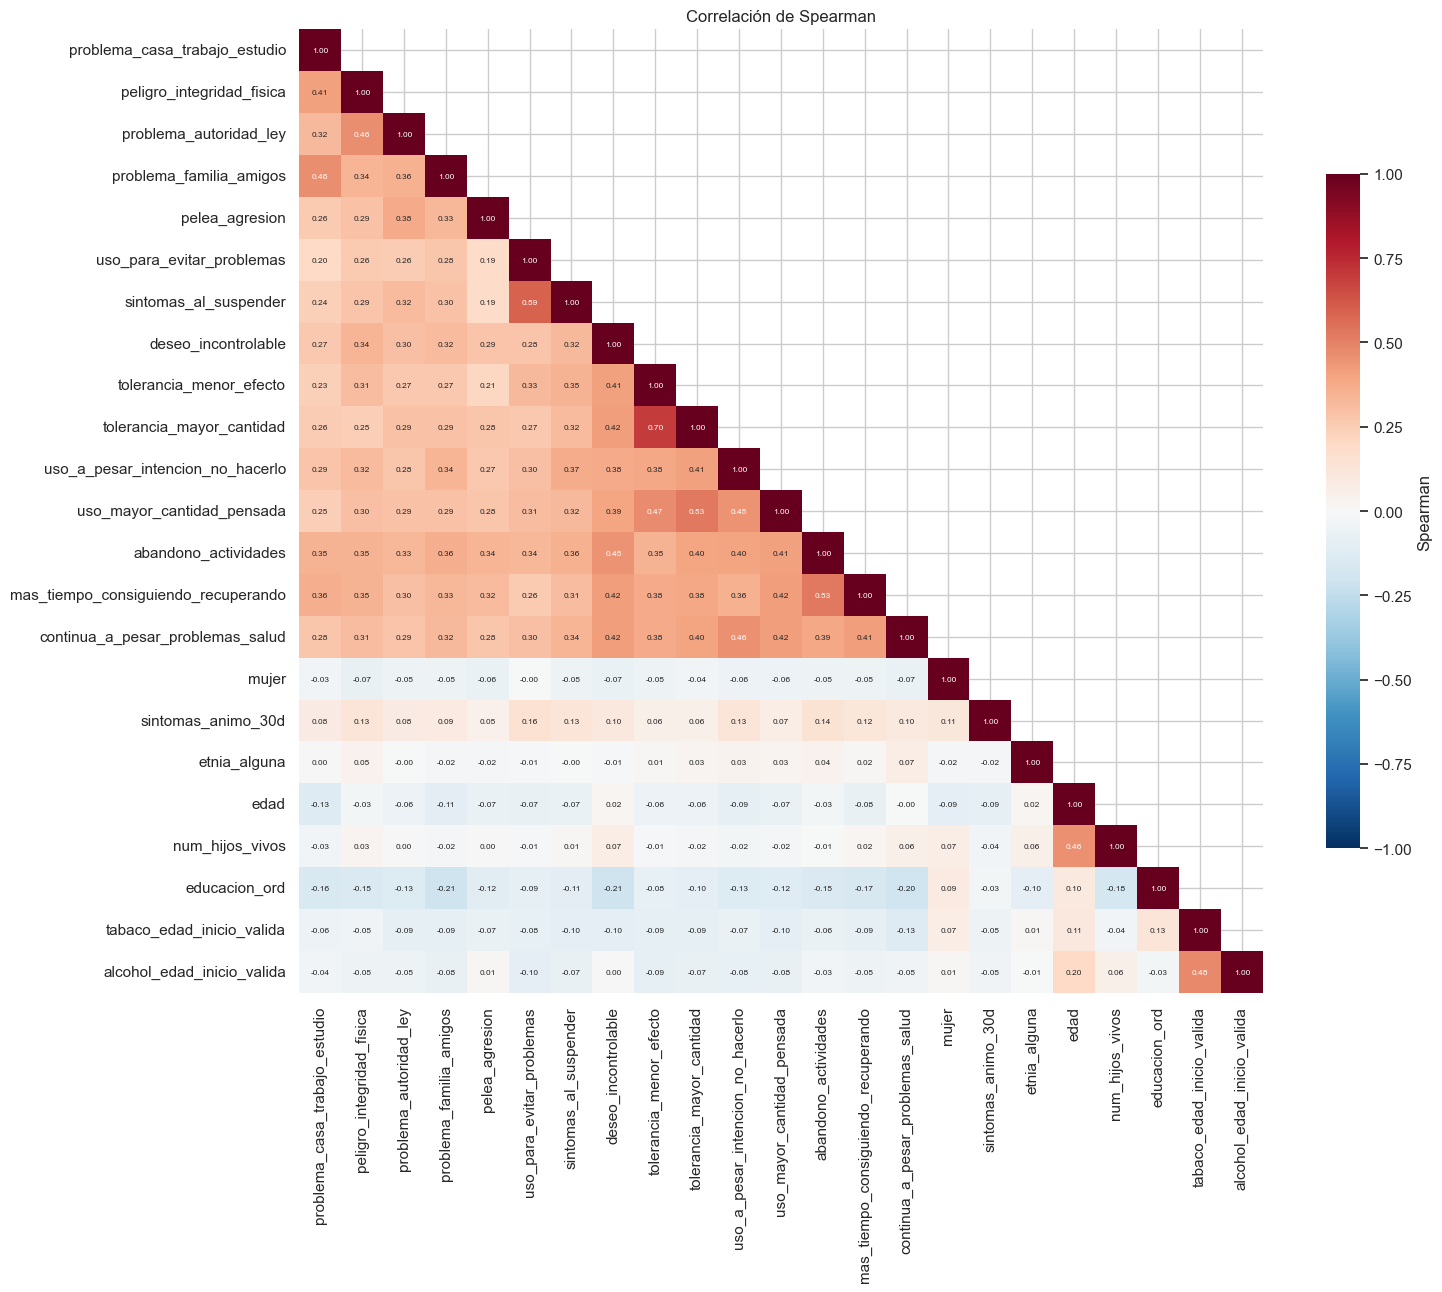

In [15]:
cols_spearman = ITEMS + COV_BIN + ['edad', 'num_hijos_vivos', 'educacion_ord',
                                   'tabaco_edad_inicio_valida', 'alcohol_edad_inicio_valida']
df_corr = df_modelo[cols_spearman].copy()
df_corr.columns = [c.replace('marihuana_', '') for c in df_corr.columns]
corr = df_corr.corr(method='spearman')

plt.figure(figsize=(16, 13))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 6},
            square=True, cbar_kws={'shrink': 0.7, 'label': 'Spearman'})
plt.title('Correlación de Spearman')
plt.tight_layout()
plt.show()

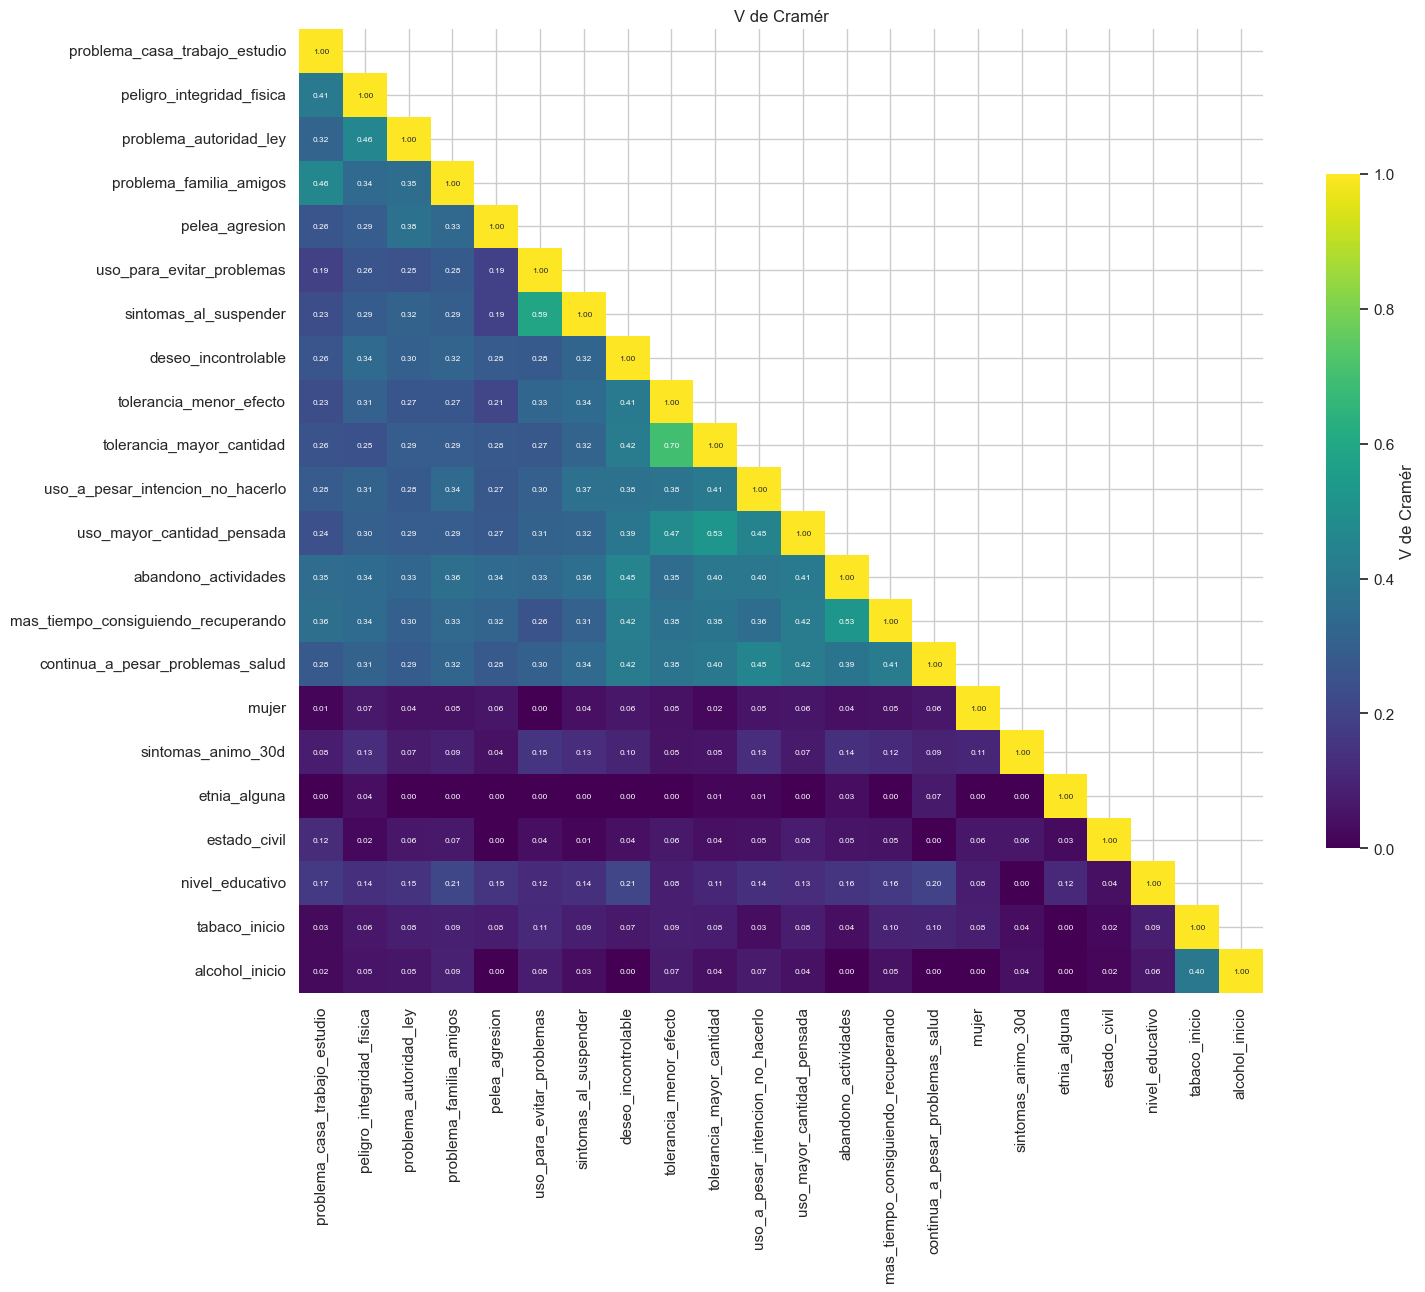

In [16]:
def cramers_v(a, b):
    tabla = pd.crosstab(a, b)
    r, k = tabla.shape
    if r < 2 or k < 2:
        return np.nan
    n = tabla.values.sum()
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c = r - (r - 1) ** 2 / (n - 1)
    k_c = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_c - 1, r_c - 1))


cols_v = ITEMS + COV_BIN + COV_CAT
V = pd.DataFrame(np.nan, index=cols_v, columns=cols_v)
for i, a in enumerate(cols_v):
    for b in cols_v[i:]:
        V.loc[a, b] = V.loc[b, a] = 1.0 if a == b else cramers_v(df_modelo[a], df_modelo[b])
V.index = V.columns = [c.replace('marihuana_', '') for c in cols_v]

plt.figure(figsize=(16, 13))
sns.heatmap(V.astype(float), mask=np.triu(np.ones_like(V, dtype=bool), k=1), cmap='viridis',
            vmin=0, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 6},
            square=True, cbar_kws={'shrink': 0.7, 'label': "V de Cramér"})
plt.title("V de Cramér")
plt.tight_layout()
plt.show()

## 9. Base para el modelo

Se arma la matriz X de 14 columnas: 3 binarias, edad y número de hijos estandarizados, y 9 indicadoras (estado civil, educación, inicio de tabaco e inicio de alcohol, con referencias soltero, hasta primaria, nunca y no temprano). La X tiene rango completo. El peso normalizado es w = fex_c / media(fex_c).

In [17]:
def dummies(serie, orden):
    cat = pd.Series(pd.Categorical(serie, categories=orden), index=serie.index, name=serie.name)
    return pd.get_dummies(cat, prefix=serie.name, drop_first=True, dtype=float)


escala = pd.DataFrame({'media': df_modelo[COV_NUM].mean(), 'desv_std': df_modelo[COV_NUM].std()})
Z = (df_modelo[COV_NUM] - escala['media']) / escala['desv_std']
Z.columns = [c + '_z' for c in COV_NUM]

X_df = pd.concat(
    [df_modelo[COV_BIN].astype(float), Z] + [dummies(df_modelo[c], ORDEN[c]) for c in COV_CAT],
    axis=1)
Y = df_modelo[ITEMS].to_numpy(dtype=int)
df_modelo['peso_norm'] = df_modelo['fex_c'] / df_modelo['fex_c'].mean()
w = df_modelo['peso_norm'].to_numpy()

print('Y:', Y.shape, '| X:', X_df.shape, '| w:', w.shape)
print('NaN en X:', int(X_df.isna().sum().sum()), '| NaN en Y:', int(np.isnan(Y.astype(float)).sum()))
print('Rango de X:', np.linalg.matrix_rank(X_df.to_numpy()), 'de', X_df.shape[1], 'columnas')
print('Columnas de X:', list(X_df.columns))

Y: (1217, 15) | X: (1217, 14) | w: (1217,)
NaN en X: 0 | NaN en Y: 0
Rango de X: 14 de 14 columnas
Columnas de X: ['mujer', 'sintomas_animo_30d', 'etnia_alguna', 'edad_z', 'num_hijos_vivos_z', 'estado_civil_Unión libre', 'estado_civil_Casado', 'estado_civil_Separado o viudo', 'nivel_educativo_Secundaria', 'nivel_educativo_Media', 'nivel_educativo_Superior', 'tabaco_inicio_Tardío', 'tabaco_inicio_Temprano', 'alcohol_inicio_Temprano']


In [18]:
base_blca = df_modelo[LLAVES + ['fex_c', 'peso_norm'] + ITEMS + COV
                      + ['educacion_ord', 'n_problemas',
                         'tabaco_edad_inicio_valida', 'alcohol_edad_inicio_valida']]

base_blca.to_csv(SALIDA + 'base_blca.csv', index=False)
X_df.to_csv(SALIDA + 'blca_X.csv', index=False)
escala.to_csv(SALIDA + 'blca_escala_covariables.csv')
flujo.to_csv(SALIDA + 'blca_flujo_muestra.csv', index=False)
np.savez(SALIDA + 'blca_arrays.npz', Y=Y, X=X_df.to_numpy(dtype=float), w=w,
         items=np.array(ITEMS), columnas_X=np.array(X_df.columns))

base_blca.shape

(1217, 34)

## 10. Complementos del EDA

Estas celdas sostienen tres decisiones de construcción: unir las dos preguntas de ánimo, el umbral de 15 años y la forma de las distribuciones.

### 10.1 Unir ánimo bajo y poco interés

In [19]:
a = df_modelo['animo_bajo_30d'].map({1: 1, 2: 0})
b = df_modelo['poco_interes_placer_30d'].map({1: 1, 2: 0})
ok = a.notna() & b.notna()
a, b = a[ok].astype(int), b[ok].astype(int)

n11 = int(((a == 1) & (b == 1)).sum()); n10 = int(((a == 1) & (b == 0)).sum())
n01 = int(((a == 0) & (b == 1)).sum()); n00 = int(((a == 0) & (b == 0)).sum())

tabla_ab = pd.DataFrame([[n00, n01], [n10, n11]],
                        index=['Sin ánimo bajo', 'Con ánimo bajo'],
                        columns=['Sin poco interés', 'Con poco interés'])
display(tabla_ab)

n = n00 + n01 + n10 + n11
phi = (n11 * n00 - n10 * n01) / np.sqrt((n11 + n10) * (n01 + n00) * (n11 + n01) * (n10 + n00))
OR = (n11 * n00) / max(n10 * n01, 1)
tetra = np.cos(np.pi / (1 + np.sqrt(OR)))  # aproximación de la tetracórica

resumen_union = pd.Series({
    'n con ambas respuestas': n,
    'prevalencia ánimo bajo': (n11 + n10) / n,
    'prevalencia poco interés': (n11 + n01) / n,
    'prevalencia unión (o)': (n11 + n10 + n01) / n,
    'prevalencia intersección (y)': n11 / n,
    'P(ambos | alguno)': n11 / (n11 + n10 + n01),
    'phi': phi,
    'tetracórica (aprox.)': tetra,
    'odds ratio': OR,
}).round(3)
resumen_union

,Sin poco interés,Con poco interés
Sin ánimo bajo,803,50
Con ánimo bajo,128,236


n con ambas respuestas          1217.000
prevalencia ánimo bajo             0.299
prevalencia poco interés           0.235
prevalencia unión (o)              0.340
prevalencia intersección (y)       0.194
P(ambos | alguno)                  0.570
phi                                0.637
tetracórica (aprox.)               0.883
odds ratio                        29.611
dtype: float64

La correlación tetracórica es de unos 0,88, el odds ratio entre las dos preguntas es 29,6 y 57 % de quienes responden sí a alguna de las dos responden sí a ambas. Miden casi lo mismo, entonces unirlas pierde poca información. La variable resultante tiene prevalencia de 34,0 %.

### 10.2 Edad de inicio: categoría "nunca" y sensibilidad del umbral

In [20]:
orig = pd.DataFrame({
    'alcohol': df_modelo['alcohol_alguna_vez'].map({1: 'Alguna vez', 2: 'Nunca'}).value_counts(dropna=False),
    'tabaco': df_modelo['tabaco_alguna_vez'].map({1: 'Alguna vez', 2: 'Nunca'}).value_counts(dropna=False),
})
orig['alcohol_%'] = (100 * orig['alcohol'] / orig['alcohol'].sum()).round(2)
orig['tabaco_%'] = (100 * orig['tabaco'] / orig['tabaco'].sum()).round(2)
display(orig)

filas = []
for sust in ['tabaco', 'alcohol']:
    alguna = df_modelo[f'{sust}_alguna_vez'] == 1
    e = df_modelo[f'{sust}_edad_inicio']
    filas.append({
        'sustancia': sust,
        'consumieron alguna vez': int(alguna.sum()),
        'edad inicio <= 0 o vacía': int((alguna & ~(e > 0)).sum()),
        'edad inicio > edad actual': int((alguna & (e > df_modelo['edad'])).sum()),
        'edad inicio <= 5 (implausible)': int((alguna & (e <= 5)).sum()),
        'mínimo': e[alguna].min(), 'máximo': e[alguna].max(),
    })
display(pd.DataFrame(filas).set_index('sustancia'))

filas = []
for u in [13, 14, 15, 16, 18]:
    fila = {'umbral (años)': u,
            'personas con edad < umbral': int((df_modelo['edad'] < u).sum())}
    for sust in ['tabaco', 'alcohol']:
        v = df_modelo[f'{sust}_edad_inicio_valida'].dropna()
        fila[f'{sust} % temprano (entre válidos)'] = round(100 * (v < u).mean(), 1)
    filas.append(fila)
pd.DataFrame(filas).set_index('umbral (años)')

,alcohol,tabaco,alcohol_%,tabaco_%
Alguna vez,1201,1048,98.69,86.11
Nunca,16,169,1.31,13.89


,consumieron alguna vez,edad inicio <= 0 o vacía,edad inicio > edad actual,edad inicio <= 5 (implausible),mínimo,máximo
sustancia,,,,,,
tabaco,1048,0,0,4,3.0,38.0
alcohol,1201,0,0,9,1.0,27.0


,personas con edad < umbral,tabaco % temprano (entre válidos),alcohol % temprano (entre válidos)
umbral (años),,,
13,1,15.6,16.2
14,4,25.0,25.3
15,15,40.2,41.4
16,28,57.1,63.4
18,80,78.9,86.3


El umbral de 15 años es una decisión de diseño y es sensible: entre 13 y 18 años el porcentaje de inicio temprano de tabaco pasa de 15,6 % a 78,9 %, y el de alcohol de 16,2 % a 86,3 %. Además 98,7 % de la muestra ha probado alcohol, así que la categoría "alcohol temprano" casi no tiene contraste y eso limita lo que se puede detectar con esa covariable. Hay 9 personas con inicio de alcohol a los 5 años o menos y 4 en tabaco, se dejan como tempranas pero sin leer su edad literalmente (la memoria de la edad de inicio es imprecisa).

### 10.3 Forma de las distribuciones

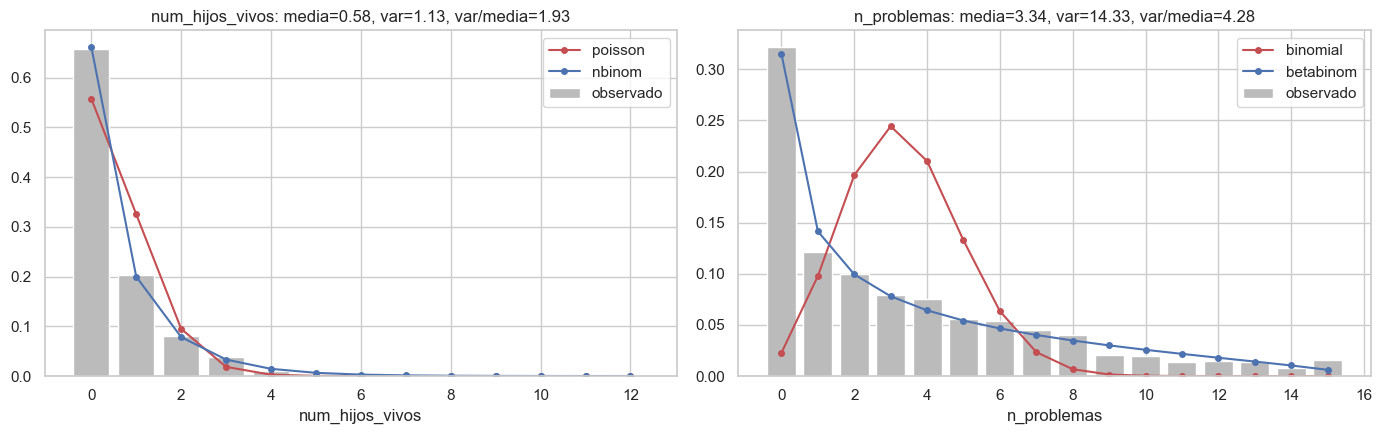

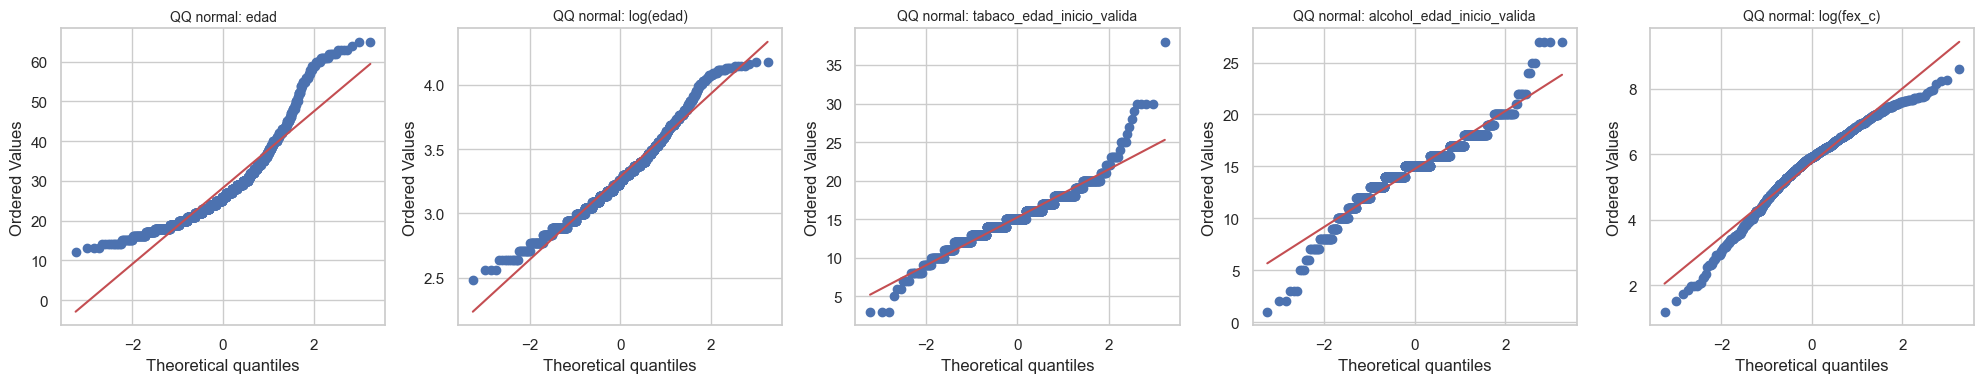

In [21]:
def ajusta_discreta(s, familia, n_max=None):
    m, v = s.mean(), s.var()
    k = np.arange(0, int(s.max()) + 1)
    if familia == 'poisson':
        return k, stats.poisson(m).pmf(k)
    if familia == 'nbinom':
        p = m / v
        r = m * p / (1 - p)
        return k, stats.nbinom(r, p).pmf(k)
    if familia == 'binomial':
        return k, stats.binom(n_max, m / n_max).pmf(k)
    if familia == 'betabinom':
        p = m / n_max
        rho = (v / (n_max * p * (1 - p)) - 1) / (n_max - 1)
        c = 1 / rho - 1
        return k, stats.betabinom(n_max, p * c, (1 - p) * c).pmf(k)


fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (c, familias, n_max) in zip(axes, [
        ('num_hijos_vivos', ['poisson', 'nbinom'], None),
        ('n_problemas', ['binomial', 'betabinom'], len(ITEMS))]):
    s = df_modelo[c]
    k = np.arange(0, int(s.max()) + 1)
    ax.bar(k, [(s == i).mean() for i in k], color='#bbbbbb', label='observado')
    for fam, col in zip(familias, ['#c44e52', '#4c72b0']):
        kk, pmf = ajusta_discreta(s, fam, n_max)
        ax.plot(kk, pmf, 'o-', color=col, ms=4, label=fam)
    ax.set_title(f'{c}: media={s.mean():.2f}, var={s.var():.2f}, var/media={s.var()/s.mean():.2f}')
    ax.set_xlabel(c)
    ax.legend()
plt.tight_layout()
plt.show()

cont = {'edad': df_modelo['edad'], 'log(edad)': np.log(df_modelo['edad']),
        'tabaco_edad_inicio_valida': df_modelo['tabaco_edad_inicio_valida'].dropna(),
        'alcohol_edad_inicio_valida': df_modelo['alcohol_edad_inicio_valida'].dropna(),
        'log(fex_c)': np.log(df_modelo['fex_c'])}
fig, axes = plt.subplots(1, len(cont), figsize=(4 * len(cont), 4))
for ax, (nombre, s) in zip(axes, cont.items()):
    stats.probplot(s, dist='norm', plot=ax)
    ax.set_title(f'QQ normal: {nombre}', fontsize=10)
plt.tight_layout()
plt.show()

El número de problemas tiene media 3,34 y varianza 14,3 (var/media = 4,28), unas cinco veces lo que daría una binomial con esa media, y 32 % de las personas no tiene ningún problema. La beta-binomial ajusta mucho mejor. Esto dice que las personas no comparten una misma probabilidad de problemas, algo compatible con clases discretas pero también con un rasgo continuo de severidad, la descripción sola no distingue entre las dos. El número de hijos tiene exceso de ceros (65,8 %) y var/media de 1,93, por eso la Poisson no sirve y la binomial negativa se acerca más. En las continuas, el logaritmo corrige las colas de la edad y del factor de expansión.

### 10.4 Asociación entre todas las variables

Como hay variables de tipos distintos, se usa una medida entre 0 y 1 según el par: V de Cramér entre categóricas, |Spearman| entre numéricas y razón de correlación eta entre numérica y categórica. No informa el signo.

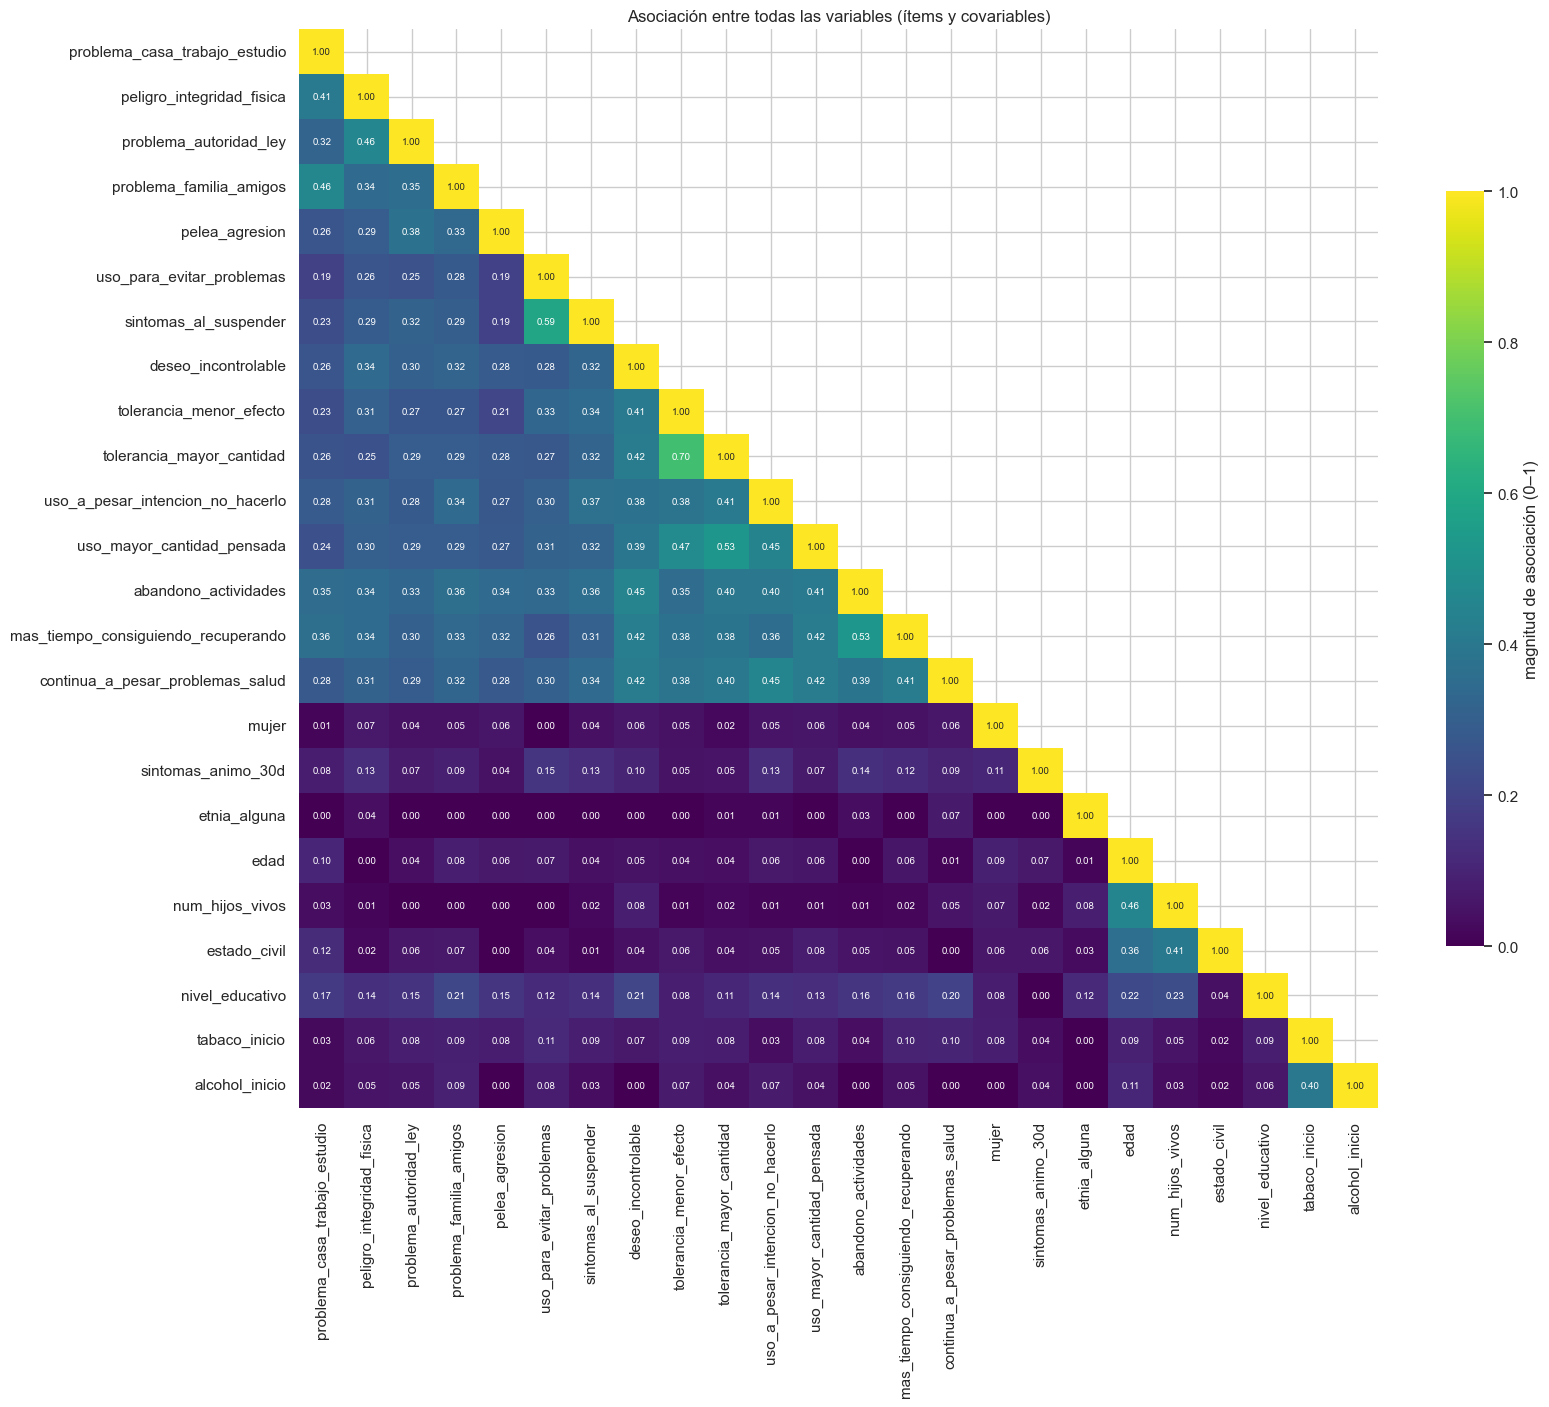

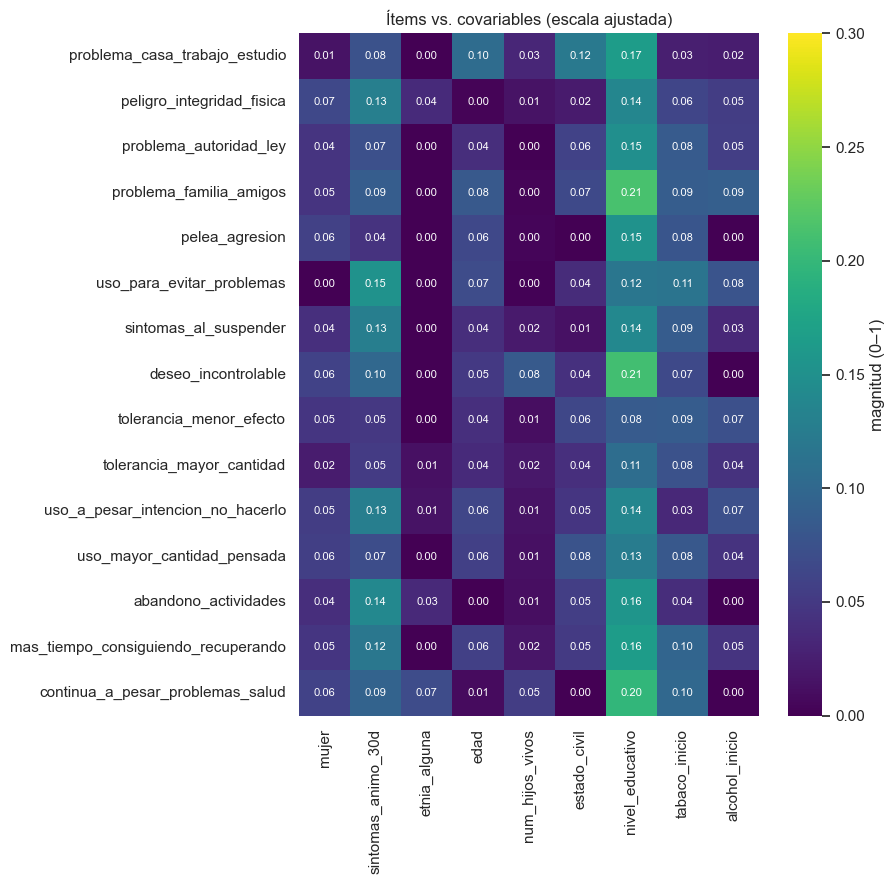

In [22]:
TIPO = {**{c: 'cat' for c in ITEMS + COV_BIN + COV_CAT}, **{c: 'num' for c in COV_NUM}}
VARS_ASOC = ITEMS + COV_BIN + COV_NUM + COV_CAT


def eta(num, cat):
    d = pd.DataFrame({'y': num, 'g': cat}).dropna()
    if d['g'].nunique() < 2:
        return np.nan
    ss_tot = ((d['y'] - d['y'].mean()) ** 2).sum()
    ss_b = d.groupby('g')['y'].apply(lambda x: len(x) * (x.mean() - d['y'].mean()) ** 2).sum()
    return np.sqrt(ss_b / ss_tot) if ss_tot > 0 else np.nan


def asociacion(a, b):
    ta, tb = TIPO[a], TIPO[b]
    x, y = df_modelo[a], df_modelo[b]
    if ta == 'cat' and tb == 'cat':
        return cramers_v(x, y)
    if ta == 'num' and tb == 'num':
        return abs(stats.spearmanr(x, y)[0])
    return eta(x, y) if ta == 'num' else eta(y, x)


corto = {c: c.replace('marihuana_', '') for c in VARS_ASOC}
A = pd.DataFrame(np.nan, index=VARS_ASOC, columns=VARS_ASOC)
for i, a_ in enumerate(VARS_ASOC):
    for b_ in VARS_ASOC[i:]:
        A.loc[a_, b_] = A.loc[b_, a_] = 1.0 if a_ == b_ else asociacion(a_, b_)
A = A.rename(index=corto, columns=corto).astype(float)

plt.figure(figsize=(17, 14))
sns.heatmap(A, mask=np.triu(np.ones_like(A, dtype=bool), k=1), cmap='viridis', vmin=0, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7}, square=True,
            cbar_kws={'shrink': 0.7, 'label': 'magnitud de asociación (0–1)'})
plt.title('Asociación entre todas las variables (ítems y covariables)')
plt.tight_layout()
plt.show()

cov_cortas = COV_BIN + COV_NUM + COV_CAT
plt.figure(figsize=(9, 9))
sns.heatmap(A.loc[[corto[c] for c in ITEMS], cov_cortas], cmap='viridis', vmin=0,
            vmax=max(0.3, float(A.loc[[corto[c] for c in ITEMS], cov_cortas].max().max())),
            annot=True, fmt='.2f', annot_kws={'size': 8}, cbar_kws={'label': 'magnitud (0–1)'})
plt.title('Ítems vs. covariables (escala ajustada)')
plt.tight_layout()
plt.show()

Tres pares de ítems son casi redundantes: tolerancia por menor efecto con tolerancia por mayor cantidad (0,70), uso para evitar problemas con síntomas al suspender (0,59) y abandono de actividades con tiempo dedicado a conseguir la sustancia (0,53). Eso avisa de posible dependencia local, que el modelo supone nula dentro de cada clase. Entre ítems y covariables las asociaciones son bajas (máximo 0,21), lo esperable porque las covariables no miden lo mismo que los ítems. Entre covariables lo más alto es edad con número de hijos (0,46) y con estado civil (0,36).

## 11. Primera especificación de las priors

En todo el cuaderno N(mu, sigma) usa desviación estándar. Para la persona i, ítem j y clase k:

Y_ij | C_i = k ~ Bernoulli(theta_kj),  log(pi_ik / pi_i1) = gamma_0k + x_i' beta_k (k >= 2)

Las priors son débilmente informativas:

- theta_kj ~ Beta(c p_j, c (1 - p_j)) con c = 3, centrada en la prevalencia marginal del ítem (Bayes empírico). La versión inicial era Beta(1,1), que se deja como sensibilidad junto con c = 2 y c = 6.
- gamma_0k ~ N(0; 1,5). El 95 % a priori cubre odds de 0,05 a 19, lo que permite clases de tamaños muy distintos sin forzar una vacía.
- beta_km ~ N(0; 1). Con covariables estandarizadas o indicadoras el 95 % a priori del odds ratio va de 0,14 a 7,1. Sensibilidad con sigma = 0,5 y 2,5.
- Las clases se ordenan por la probabilidad media de problemas. Esto no es una prior, es una restricción de identificación que se impone después del muestreo (función relabel más abajo).
- Los pesos entran en la pseudo-verosimilitud, no en las priors.

La simulación a priori usa la X observada y compara la propuesta de la literatura (sigma_gamma = 10, sigma_beta = 2,5) con la elegida.

In [23]:
rng = np.random.default_rng(2026)
Xm = X_df.to_numpy(dtype=float)
n_obs, p = Xm.shape


def probs_clase(sd_g, sd_b, K, S, gen=None):
    gen = rng if gen is None else gen
    g = gen.normal(0, sd_g, size=(S, K - 1))
    b = gen.normal(0, sd_b, size=(S, K - 1, p))
    eta = np.zeros((S, n_obs, K))
    eta[:, :, 1:] = g[:, None, :] + np.einsum('np,skp->snk', Xm, b)
    eta -= eta.max(axis=2, keepdims=True)
    e = np.exp(eta)
    return e / e.sum(axis=2, keepdims=True)


def resumen_prior(sd_g, sd_b, K=3, S=300):
    pr = probs_clase(sd_g, sd_b, K, S)
    cuota = pr.mean(axis=1)                      # proporción poblacional de cada clase
    return {
        'sd_gamma': sd_g, 'sd_beta': sd_b, 'K': K,
        'mediana de la clase más pequeña': round(float(np.median(cuota.min(axis=1))), 3),
        'P(clase más pequeña < 5 %)': round(float((cuota.min(axis=1) < 0.05).mean()), 3),
        'prob. máx. individual (mediana)': round(float(np.median(pr.max(axis=2))), 3),
        'P(prob. máx. individual > 0,99)': round(float((pr.max(axis=2) > 0.99).mean()), 3),
    }


combinaciones = [(10, 2.5), (2.5, 2.5), (1.5, 2.5), (1.5, 1), (1.5, 0.5)]
tabla_prior = pd.DataFrame([resumen_prior(g, b, K=K) for K in (3, 4) for g, b in combinaciones])
tabla_prior

,sd_gamma,sd_beta,K,mediana de la clase más pequeña,P(clase más pequeña < 5 %),prob. máx. individual (mediana),"P(prob. máx. individual > 0,99)"
0,10.0,2.5,3,0.002,0.817,0.998,0.606
1,2.5,2.5,3,0.102,0.240,0.956,0.337
2,1.5,2.5,3,0.136,0.117,0.945,0.310
3,1.5,1.0,3,0.127,0.143,0.760,0.049
4,1.5,0.5,3,0.109,0.170,0.659,0.006
5,10.0,2.5,4,0.000,0.930,0.997,0.585
6,2.5,2.5,4,0.043,0.557,0.946,0.318
7,1.5,2.5,4,0.065,0.390,0.933,0.293
8,1.5,1.0,4,0.058,0.423,0.713,0.039
9,1.5,0.5,4,0.057,0.447,0.597,0.003


Con sigma = 10 la prior es muy difusa: 60,6 % de las asignaciones individuales quedan casi deterministas y en 81,7 % de las simulaciones hay una clase casi vacía (K = 3). Con la especificación elegida baja a 4,9 % y 14,3 %. Con K = 4 la clase más pequeña sigue bajando de 5 % en 42,3 % de las simulaciones, eso hay que vigilarlo al comparar K.

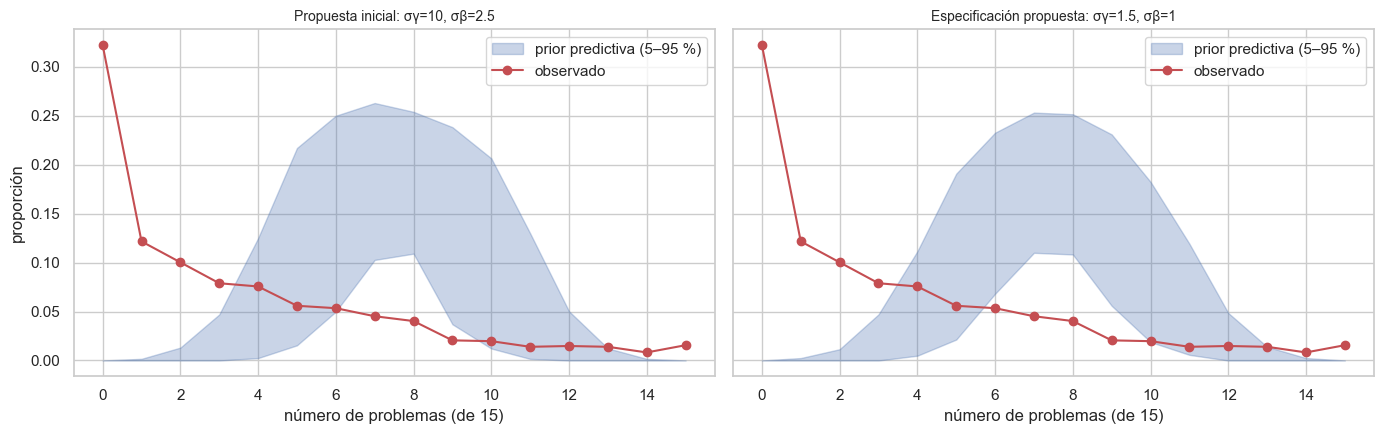

In [24]:
def n_problemas_prior(sd_g, sd_b, a_t, b_t, K=3, S=300):
    pr = probs_clase(sd_g, sd_b, K, S)                     # (S, n, K)
    theta = rng.beta(a_t, b_t, size=(S, K, len(ITEMS)))
    u = rng.random((S, n_obs, 1))
    clase = (u > np.cumsum(pr, axis=2)).sum(axis=2).clip(0, K - 1)  # (S, n)
    th = np.take_along_axis(theta, clase[:, :, None].repeat(len(ITEMS), 2), axis=1)
    y = rng.random(th.shape) < th
    return y.sum(axis=2)                                    # (S, n)


observado = np.bincount(df_modelo['n_problemas'].astype(int), minlength=len(ITEMS) + 1) / n_obs
ks = np.arange(len(ITEMS) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (sg, sb, tit) in zip(axes, [(10, 2.5, 'Propuesta inicial: σγ=10, σβ=2.5'),
                                     (1.5, 1, 'Especificación propuesta: σγ=1.5, σβ=1')]):
    sim = n_problemas_prior(sg, sb, 1, 1)
    dist = np.stack([np.bincount(s, minlength=len(ITEMS) + 1) / n_obs for s in sim])
    ax.fill_between(ks, np.percentile(dist, 5, axis=0), np.percentile(dist, 95, axis=0),
                    color='#4c72b0', alpha=0.3, label='prior predictiva (5–95 %)')
    ax.plot(ks, observado, 'o-', color='#c44e52', label='observado')
    ax.set_title(tit, fontsize=10)
    ax.set_xlabel('número de problemas (de 15)')
    ax.legend()
axes[0].set_ylabel('proporción')
plt.tight_layout()
plt.show()

En las dos especificaciones la banda a priori del número de problemas se concentra en la zona central, y los datos tienen mucha masa en cero (32 %). Con Beta(1,1) la prior espera como 7,5 problemas frente a los 3,34 observados. No es un problema grave porque con n = 1.217 se espera que domine la verosimilitud, y eso se revisa en los chequeos posteriores.

# Modelado

In [25]:
# arreglos que usa el modelo (misma información que base_blca.csv y blca_arrays.npz)
Y = Y.astype(float)
X = X_df.to_numpy(dtype=float)
nombres_X = list(X_df.columns)
items = list(ITEMS)
N_OBS, N_ITEMS = Y.shape
CLAVES = ['sintomas_animo_30d', 'tabaco_inicio_Temprano', 'alcohol_inicio_Temprano']
print(Y.shape, X.shape, w.shape, round(w.sum(), 1))

(1217, 15) (1217, 14) (1217,) 1217.0


## 12. Chequeo a priori con la prior de theta

In [26]:
# Nota de método: las columnas "tamaño de la clase más pequeña" y "prob. máx. de pertenencia" de la Tabla 2 dependen
# solo de γ, β y X; la prior de θ no interviene. La parte (a) lo comprueba reproduciendo la Tabla 2 original.
# La parte (b) añade una medida que SÍ depende de θ: la certeza de clasificación dado Y simulado.
Xm = X; n_obs, p_cov = Xm.shape; J = Y.shape[1]
p_j = np.clip(np.average(Y, axis=0, weights=w), 0.02, 0.98)          # igual que en `ajustar`
C_PRIOR = 3.0

def probs_clase(rng_, sd_g, sd_b, K, S):
    g = rng_.normal(0, sd_g, size=(S, K - 1))
    b = rng_.normal(0, sd_b, size=(S, K - 1, p_cov))
    eta = np.zeros((S, n_obs, K))
    eta[:, :, 1:] = g[:, None, :] + np.einsum('np,skp->snk', Xm, b)
    eta -= eta.max(axis=2, keepdims=True)
    e = np.exp(eta)
    return e / e.sum(axis=2, keepdims=True)

# (a) Tabla 2 original, misma semilla y mismo orden de llamadas que la celda 42
combinaciones = [(10, 2.5), (2.5, 2.5), (1.5, 2.5), (1.5, 1), (1.5, 0.5)]
rng_a = np.random.default_rng(2026)
filas = []
for K in (3, 4):
    for sg, sb in combinaciones:
        pr = probs_clase(rng_a, sg, sb, K, 300)
        cuota = pr.mean(axis=1)
        filas.append({'K': K, 'σγ': sg, 'σβ': sb,
                      'mediana clase más pequeña': round(float(np.median(cuota.min(1))), 3),
                      'P(clase más pequeña < 5 %)': round(float((cuota.min(1) < 0.05).mean()), 3),
                      'P(prob. máx. pertenencia > 0,99)': round(float((pr.max(2) > 0.99).mean()), 3)})
tabla2_a = pd.DataFrame(filas)
print('(a) Tabla 2 original (independiente de θ). Debe coincidir con la salida de la celda 42:')
display(tabla2_a)

# (b) Con θ: prior predictiva y certeza de clasificación posterior
def sim_con_theta(sd_g, sd_b, K, a_t, b_t, seed, S=300):
    rng_ = np.random.default_rng(seed)                          # misma semilla => mismos γ, β para ambas priors de θ
    pr = probs_clase(rng_, sd_g, sd_b, K, S)                     # (S,n,K)
    theta = np.clip(rng_.beta(a_t, b_t, size=(S, K, J)), 1e-9, 1 - 1e-9)
    u = rng_.random((S, n_obs, 1))
    clase = (u > np.cumsum(pr, axis=2)).sum(axis=2).clip(0, K - 1)
    th = np.take_along_axis(theta, clase[:, :, None].repeat(J, 2), axis=1)   # (S,n,J)
    y = (rng_.random(th.shape) < th).astype(float)
    ll = np.einsum('snj,skj->snk', y, np.log(theta)) + np.einsum('snj,skj->snk', 1 - y, np.log1p(-theta))
    lp = np.log(np.clip(pr, 1e-300, None)) + ll
    lp -= lp.max(axis=2, keepdims=True)
    post = np.exp(lp); post /= post.sum(axis=2, keepdims=True)
    return pr, post, y

priors_theta = {'Beta(1,1)': (np.ones(J), np.ones(J)),
                f'Beta(c·p_j, c·(1−p_j)), c = {C_PRIOR:g}': (C_PRIOR * p_j, C_PRIOR * (1 - p_j))}
filas = []
for K in (3, 4):
    for sg, sb in [(10, 2.5), (1.5, 1)]:
        for nombre, (a_t, b_t) in priors_theta.items():
            pr, post, y = sim_con_theta(sg, sb, K, a_t, b_t, seed=2027)
            cuota = pr.mean(axis=1)
            filas.append({'K': K, 'σγ': sg, 'σβ': sb, 'prior de θ': nombre,
                          'mediana clase más pequeña': round(float(np.median(cuota.min(1))), 3),
                          'P(clase más pequeña < 5 %)': round(float((cuota.min(1) < 0.05).mean()), 3),
                          'P(prob. máx. pertenencia > 0,99)': round(float((pr.max(2) > 0.99).mean()), 3),
                          'P(prob. máx. posterior > 0,99)': round(float((post.max(2) > 0.99).mean()), 3),
                          'mediana prob. máx. posterior': round(float(np.median(post.max(2))), 3),
                          'n.º medio de problemas a priori': round(float(y.sum(2).mean()), 2)})
tabla2_b = pd.DataFrame(filas)
print(f'\n(b) Con prior de θ explícita (observado: media de problemas = {Y.sum(1).mean():.2f}):')
display(tabla2_b)
tabla2_a.to_csv(SALIDA + 'tabla2_prior_independiente_de_theta.csv', index=False)
tabla2_b.to_csv(SALIDA + 'tabla2_prior_con_theta.csv', index=False)

(a) Tabla 2 original (independiente de θ). Debe coincidir con la salida de la celda 42:


,K,σγ,σβ,mediana clase más pequeña,P(clase más pequeña < 5 %),"P(prob. máx. pertenencia > 0,99)"
0,3,10.0,2.5,0.002,0.817,0.606
1,3,2.5,2.5,0.102,0.240,0.337
2,3,1.5,2.5,0.136,0.117,0.310
3,3,1.5,1.0,0.127,0.143,0.049
4,3,1.5,0.5,0.109,0.170,0.006
5,4,10.0,2.5,0.000,0.930,0.585
6,4,2.5,2.5,0.043,0.557,0.318
7,4,1.5,2.5,0.065,0.390,0.293
8,4,1.5,1.0,0.058,0.423,0.039
9,4,1.5,0.5,0.057,0.447,0.003



(b) Con prior de θ explícita (observado: media de problemas = 3.34):


,K,σγ,σβ,prior de θ,mediana clase más pequeña,P(clase más pequeña < 5 %),"P(prob. máx. pertenencia > 0,99)","P(prob. máx. posterior > 0,99)",mediana prob. máx. posterior,n.º medio de problemas a priori
0,3,10.0,2.5,"Beta(1,1)",0.002,0.84,0.621,0.930,1.000,7.50
1,3,10.0,2.5,"Beta(c·p_j, c·(1−p_j)), c = 3",0.002,0.84,0.621,0.859,1.000,3.34
2,3,1.5,1.0,"Beta(1,1)",0.115,0.20,0.055,0.745,0.999,7.45
3,3,1.5,1.0,"Beta(c·p_j, c·(1−p_j)), c = 3",0.115,0.20,0.055,0.522,0.992,3.36
4,4,10.0,2.5,"Beta(1,1)",0.000,0.93,0.568,0.916,1.000,7.47
5,4,10.0,2.5,"Beta(c·p_j, c·(1−p_j)), c = 3",0.000,0.93,0.568,0.830,1.000,3.41
6,4,1.5,1.0,"Beta(1,1)",0.062,0.42,0.042,0.675,0.998,7.51
7,4,1.5,1.0,"Beta(c·p_j, c·(1−p_j)), c = 3",0.062,0.42,0.042,0.454,0.985,3.40


## 13. Modelo y funciones de ajuste

In [27]:
def modelo(Y, X, w, p_j, c=3.0, sd_g=1.5, sd_b=1.0, K=3):
    n, J = Y.shape
    P = X.shape[1]
    # pertenencia a clase: logit multinomial, clase 1 de referencia
    g = numpyro.sample('gamma', npd.Normal(0, sd_g).expand([K - 1]))
    b = numpyro.sample('beta', npd.Normal(0, sd_b).expand([K - 1, P]))
    eta = jnp.concatenate([jnp.zeros((n, 1)), g + X @ b.T], axis=1)
    log_pi = jax.nn.log_softmax(eta, axis=1)
    # perfiles de respuesta, centrados en la prevalencia marginal
    theta = numpyro.sample('theta', npd.Beta(c * p_j, c * (1 - p_j)).expand([K, J]))
    ll = Y @ jnp.log(theta).T + (1 - Y) @ jnp.log1p(-theta).T
    log_lik_i = jax.scipy.special.logsumexp(log_pi + ll, axis=1)
    numpyro.factor('pseudo_lik', jnp.sum(w * log_lik_i))     # ecuación 3 del artículo
    numpyro.deterministic('log_lik_i', log_lik_i)


def ajustar(Yd, Xd, wd, K=3, c=3.0, sd_g=1.5, sd_b=1.0, uniforme=False, seed=0,
            warmup=2000, draws=5000, chains=4, campos_extra=()):
    Yj, Xj, wj = (jnp.asarray(a, float) for a in (Yd, Xd, wd))
    if uniforme:                      # Beta(1,1) en todos los theta
        p_j, c = jnp.full(Yj.shape[1], 0.5), 2.0
    else:
        p_j = jnp.clip(jnp.average(Yj, axis=0, weights=wj), 0.02, 0.98)
    kern = NUTS(modelo, init_strategy=init_to_median(), target_accept_prob=0.9)
    mcmc = MCMC(kern, num_warmup=warmup, num_samples=draws, num_chains=chains,
                chain_method='parallel', progress_bar=False)
    mcmc.run(jax.random.PRNGKey(seed), Yj, Xj, wj, p_j, c, sd_g, sd_b, K, extra_fields=campos_extra)
    return mcmc


def relabel(s, K):
    # ordena las clases por theta_bar creciente y recalcula gamma y beta respecto a la nueva clase 1
    th, g, b = s['theta'], s['gamma'], s['beta']
    C, D = th.shape[:2]
    g_full = np.concatenate([np.zeros((C, D, 1)), g], 2)
    b_full = np.concatenate([np.zeros((C, D, 1, b.shape[-1])), b], 2)
    orden = np.argsort(th.mean(-1), axis=-1)
    take = lambda a, o: np.take_along_axis(a, o.reshape(o.shape + (1,) * (a.ndim - o.ndim)), 2)
    th2, g2, b2 = take(th, orden), take(g_full, orden), take(b_full, orden)
    g2 = g2[:, :, 1:] - g2[:, :, :1]
    b2 = b2[:, :, 1:] - b2[:, :, :1]
    return {'theta': th2, 'gamma': g2, 'beta': b2}


def posterior_ordenada(mcmc, K):
    s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()
         if k in ('theta', 'gamma', 'beta')}
    return relabel(s, K)


def waic_ponderado(mcmc, w):
    # WAIC con log-verosimilitud ponderada (aproximación)
    ll = np.asarray(mcmc.get_samples()['log_lik_i'])
    lppd = np.log(np.mean(np.exp(ll), 0))
    pw = np.var(ll, 0, ddof=1)
    return -2 * np.sum(np.asarray(w) * (lppd - pw))


def diagnostico_muestreo(mcmc, K):
    ex = mcmc.get_extra_fields(group_by_chain=True)
    div, en = np.asarray(ex['diverging']), np.asarray(ex['energy'])
    pasos, acc = np.asarray(ex['num_steps']), np.asarray(ex['accept_prob'])
    bfmi = [float(np.sum(np.diff(e) ** 2) / np.sum((e - e.mean()) ** 2)) for e in en]
    s = {k: np.asarray(v) for k, v in mcmc.get_samples(group_by_chain=True).items()
         if k in ('theta', 'gamma', 'beta')}
    reordena = (np.argsort(s['theta'].mean(-1), axis=-1) != np.arange(K)).any(-1)
    return pd.DataFrame({
        'K': K, 'divergencias': div.sum(1), 'E-BFMI': np.round(bfmi, 3),
        'aceptación media': acc.mean(1).round(3),
        '% con profundidad máx. (10)': (100 * (pasos >= 2 ** 10 - 1).mean(1)).round(2),
        '% iteraciones reordenadas por relabel': (100 * reordena.mean(1)).round(2),
    }, index=[f'cadena {i + 1}' for i in range(div.shape[0])])


def cargar_npz(archivo):
    z = np.load(archivo)
    return {k: z[k] for k in z.files}


def posterior_cache(nombre, Yd, Xd, wd, K=3, draws=3000, **kw):
    # ajusta y guarda; si el archivo ya existe y REUSAR es True, lo carga
    archivo = SALIDA + f'blca_K{K}_{nombre}.npz'
    if REUSAR and os.path.exists(archivo):
        return cargar_npz(archivo)
    t = time.time()
    m = ajustar(Yd, Xd, wd, K=K, draws=draws, **kw)
    r = posterior_ordenada(m, K)
    np.savez(archivo, **r)
    print(f'{nombre} (K={K}): {time.time() - t:.0f} s')
    return r

## 14. Ajuste para K = 2, 3, 4 y 5

Corrida principal: 4 cadenas, 2.000 iteraciones de calentamiento y 5.000 muestras por cadena. Es la parte más lenta del cuaderno.

In [28]:
resultados, diag_muestreo = {}, []
for K in (2, 3, 4, 5):
    archivo = SALIDA + f'blca_posterior_K{K}.npz'
    if REUSAR and os.path.exists(archivo):
        resultados[K] = cargar_npz(archivo)
        resultados[K]['waic'] = float(resultados[K]['waic'])
        continue
    t = time.time()
    m = ajustar(Y, X, w, K=K, draws=5000,
                campos_extra=('diverging', 'energy', 'num_steps', 'accept_prob'))
    r = posterior_ordenada(m, K)
    resultados[K] = dict(waic=waic_ponderado(m, w), **r)
    diag_muestreo.append(diagnostico_muestreo(m, K))
    np.savez(archivo, **r, waic=resultados[K]['waic'])
    del m
    print(f'K={K}  {time.time() - t:.0f} s  WAIC_w={resultados[K]["waic"]:.1f}')

if diag_muestreo:
    diag_muestreo = pd.concat(diag_muestreo)
    diag_muestreo.to_csv(SALIDA + 'diagnostico_muestreo.csv')
elif os.path.exists(SALIDA + 'diagnostico_muestreo.csv'):
    diag_muestreo = pd.read_csv(SALIDA + 'diagnostico_muestreo.csv', index_col=0)
diag_muestreo

K=2  41 s  WAIC_w=15393.7
K=3  92 s  WAIC_w=14678.0
K=4  105 s  WAIC_w=14467.6
K=5  160 s  WAIC_w=14359.7


,K,divergencias,E-BFMI,aceptación media,% con profundidad máx. (10),% iteraciones reordenadas por relabel
cadena 1,2,0,1.022,0.936,0.0,0.00
cadena 2,2,0,1.010,0.943,0.0,100.00
cadena 3,2,0,1.012,0.909,0.0,100.00
cadena 4,2,0,1.037,0.936,0.0,0.00
cadena 1,3,0,0.955,0.952,0.0,100.00
cadena 2,3,0,0.943,0.944,0.0,100.00
cadena 3,3,0,0.950,0.928,0.0,100.00
cadena 4,3,0,0.975,0.937,0.0,100.00
cadena 1,4,0,0.914,0.930,0.0,3.34
cadena 2,4,0,0.972,0.949,0.0,100.00


Lectura. Con K = 3 no hubo divergencias en las 20.000 iteraciones posteriores al calentamiento y el E-BFMI quedó entre 0,92 y 0,97, muy por encima de 0,3 que es la alerta habitual. La columna de reordenamiento dice cuántas iteraciones salieron con las clases fuera de orden y relabel las acomodó, eso es normal porque la restricción se impone después de muestrear.

## 15. Convergencia

In [29]:
def conv(r, nombre):
    ds = az.convert_to_dataset({nombre: np.asarray(r[nombre])})
    return (float(np.nanmax(az.rhat(ds)[nombre].values)),
            float(np.nanmin(az.ess(ds)[nombre].values)))


def rhat_max2(r):
    return max(conv(r, n)[0] for n in ('gamma', 'beta', 'theta'))


filas = []
for K, r in resultados.items():
    fila = {'K': K}
    for nombre in ('gamma', 'beta', 'theta'):
        rh, es = conv(r, nombre)
        fila[f'R-hat máx {nombre}'], fila[f'ESS mín {nombre}'] = round(rh, 3), round(es)
    filas.append(fila)
tab_conv = pd.DataFrame(filas).set_index('K')
tab_conv.to_csv(SALIDA + 'tabla_convergencia_por_K.csv')
tab_conv

,R-hat máx gamma,ESS mín gamma,R-hat máx beta,ESS mín beta,R-hat máx theta,ESS mín theta
K,,,,,,
2,1.000,12964,1.001,12779,1.001,17925
3,1.006,6714,1.006,7025,1.001,7491
4,1.030,97,1.083,30,1.005,5172
5,1.286,10,1.210,13,1.380,9


Lectura. K = 2 y K = 3 convergen limpio (R-hat máximo 1,001 y 1,007, ESS mínimo 13.730 y 5.286). K = 4 y K = 5 no: R-hat de 1,081 y 1,190 y ESS de 31 y 14. Con el umbral de 1,01 solo se pueden usar K = 2 y 3, lo de K = 4 y 5 queda como referencia.

## 16. Funciones de posterior y tamaños de clase por K

In [30]:
def aplanar(r, K, paso=1):
    # Posterior (cadena, iteración, ...) -> arreglos (S, ...), tomando 1 de cada `paso` iteraciones.
    g = np.asarray(r['gamma'])[:, ::paso]; b = np.asarray(r['beta'])[:, ::paso]; t = np.asarray(r['theta'])[:, ::paso]
    C, D = g.shape[:2]
    return (t.reshape(C * D, K, -1).astype(float), g.reshape(C * D, K - 1).astype(float),
            b.reshape(C * D, K - 1, -1).astype(float), C, D)

def pi_post(Xd, g, b):
    # g (S,K-1), b (S,K-1,P) -> probabilidades de clase (S,n,K), clase 1 = referencia.
    S, Km1 = g.shape
    eta = np.zeros((S, Xd.shape[0], Km1 + 1))
    eta[:, :, 1:] = g[:, None, :] + np.einsum('np,skp->snk', Xd, b)
    eta -= eta.max(2, keepdims=True)
    e = np.exp(eta)
    return e / e.sum(2, keepdims=True)

def tabla_tamanos(r, K, paso=10):
    th, g, b, C, D = aplanar(r, K, paso)
    tam = np.empty((len(g), K))
    for i in range(0, len(g), 200):
        pi = pi_post(X, g[i:i + 200], b[i:i + 200])
        tam[i:i + 200] = (pi * w[None, :, None]).sum(1) / w.sum()      # proporción poblacional (ponderada)
    tam_c = tam.reshape(C, D, K)
    filas = []
    for k in range(K):
        fila = {'K': K, 'clase': k + 1, 'media': tam[:, k].mean(),
                'IC2.5%': np.quantile(tam[:, k], .025), 'IC97.5%': np.quantile(tam[:, k], .975)}
        for c in range(C):
            fila[f'cadena {c + 1}'] = tam_c[c, :, k].mean()
        filas.append(fila)
    return pd.DataFrame(filas)

def tabla_perfiles(r, K, items_):
    th = np.asarray(r['theta']).reshape(-1, K, len(items_)).astype(float)
    m, lo, hi = th.mean(0), np.quantile(th, .025, 0), np.quantile(th, .975, 0)
    nombres = [str(i).replace('marihuana_', '') for i in items_]
    num = pd.DataFrame(m.T, index=nombres, columns=[f'clase {k + 1}' for k in range(K)])
    txt = pd.DataFrame({f'clase {k + 1}': [f'{m[k, j]:.2f} ({lo[k, j]:.2f}-{hi[k, j]:.2f})' for j in range(len(items_))]
                        for k in range(K)}, index=nombres)
    return num, txt

tam_todos = pd.concat([tabla_tamanos(resultados[K], K) for K in sorted(resultados)], ignore_index=True)
tam_todos.round(3).to_csv(SALIDA + 'tabla_tamanos_clase_por_K.csv', index=False)
display(tam_todos.round(3))

for K in sorted(resultados):
    num, txt = tabla_perfiles(resultados[K], K, items)
    num.round(3).to_csv(SALIDA + f'tabla_perfiles_theta_K{K}.csv')
    txt.to_csv(SALIDA + f'tabla_perfiles_theta_K{K}_IC.csv')
    print(f'\nPerfiles theta, K = {K} (media posterior e IC 95 %)')
    display(txt)

,K,clase,media,IC2.5%,IC97.5%,cadena 1,cadena 2,cadena 3,cadena 4
0,2,1,0.627,0.595,0.660,0.627,0.627,0.627,0.626
1,2,2,0.373,0.340,0.405,0.373,0.373,0.373,0.374
2,3,1,0.450,0.415,0.488,0.451,0.450,0.451,0.450
3,3,2,0.412,0.378,0.446,0.412,0.413,0.412,0.412
4,3,3,0.137,0.114,0.162,0.137,0.138,0.137,0.138
5,4,1,0.467,0.428,0.507,0.465,0.469,0.467,0.468
6,4,2,0.262,0.155,0.313,0.266,0.259,0.263,0.258
7,4,3,0.140,0.105,0.227,0.138,0.140,0.141,0.142
8,4,4,0.131,0.111,0.153,0.131,0.132,0.129,0.132
9,5,1,0.421,0.374,0.463,0.428,0.425,0.403,0.429



Perfiles theta, K = 2 (media posterior e IC 95 %)


,clase 1,clase 2
problema_casa_trabajo_estudio,0.05 (0.03-0.07),0.38 (0.33-0.42)
peligro_integridad_fisica,0.04 (0.02-0.05),0.35 (0.31-0.40)
problema_autoridad_ley,0.03 (0.02-0.04),0.32 (0.27-0.36)
problema_familia_amigos,0.11 (0.09-0.14),0.62 (0.57-0.66)
pelea_agresion,0.02 (0.01-0.04),0.27 (0.23-0.32)
uso_para_evitar_problemas,0.18 (0.15-0.21),0.60 (0.55-0.65)
sintomas_al_suspender,0.05 (0.04-0.07),0.48 (0.43-0.53)
deseo_incontrolable,0.03 (0.02-0.05),0.41 (0.36-0.46)
tolerancia_menor_efecto,0.08 (0.05-0.10),0.65 (0.61-0.70)
tolerancia_mayor_cantidad,0.05 (0.03-0.07),0.56 (0.51-0.61)



Perfiles theta, K = 3 (media posterior e IC 95 %)


,clase 1,clase 2,clase 3
problema_casa_trabajo_estudio,0.03 (0.01-0.05),0.20 (0.16-0.25),0.54 (0.46-0.63)
peligro_integridad_fisica,0.00 (0.00-0.02),0.20 (0.16-0.24),0.51 (0.43-0.60)
problema_autoridad_ley,0.01 (0.00-0.02),0.14 (0.11-0.18),0.53 (0.45-0.62)
problema_familia_amigos,0.07 (0.05-0.10),0.39 (0.34-0.45),0.77 (0.69-0.84)
pelea_agresion,0.01 (0.00-0.02),0.11 (0.08-0.14),0.52 (0.43-0.60)
uso_para_evitar_problemas,0.09 (0.06-0.13),0.48 (0.43-0.53),0.71 (0.63-0.79)
sintomas_al_suspender,0.01 (0.00-0.03),0.28 (0.24-0.33),0.66 (0.58-0.74)
deseo_incontrolable,0.02 (0.01-0.03),0.20 (0.16-0.24),0.61 (0.53-0.70)
tolerancia_menor_efecto,0.01 (0.00-0.03),0.40 (0.35-0.46),0.88 (0.82-0.94)
tolerancia_mayor_cantidad,0.00 (0.00-0.01),0.28 (0.23-0.34),0.88 (0.81-0.94)



Perfiles theta, K = 4 (media posterior e IC 95 %)


,clase 1,clase 2,clase 3,clase 4
problema_casa_trabajo_estudio,0.02 (0.01-0.04),0.23 (0.14-0.30),0.18 (0.11-0.28),0.56 (0.48-0.64)
peligro_integridad_fisica,0.00 (0.00-0.02),0.24 (0.10-0.31),0.11 (0.05-0.28),0.54 (0.46-0.62)
problema_autoridad_ley,0.01 (0.00-0.02),0.18 (0.03-0.25),0.05 (0.01-0.22),0.57 (0.49-0.66)
problema_familia_amigos,0.07 (0.05-0.09),0.48 (0.20-0.58),0.24 (0.15-0.56),0.80 (0.73-0.87)
pelea_agresion,0.01 (0.00-0.02),0.16 (0.01-0.22),0.02 (0.00-0.18),0.53 (0.45-0.62)
uso_para_evitar_problemas,0.10 (0.07-0.14),0.50 (0.42-0.57),0.45 (0.35-0.55),0.71 (0.64-0.78)
sintomas_al_suspender,0.01 (0.00-0.03),0.32 (0.23-0.39),0.25 (0.17-0.36),0.66 (0.58-0.74)
deseo_incontrolable,0.02 (0.01-0.04),0.19 (0.14-0.25),0.24 (0.16-0.33),0.61 (0.53-0.69)
tolerancia_menor_efecto,0.01 (0.00-0.03),0.19 (0.10-0.80),0.87 (0.17-0.98),0.91 (0.85-0.95)
tolerancia_mayor_cantidad,0.01 (0.00-0.01),0.10 (0.04-0.61),0.70 (0.08-0.85),0.90 (0.85-0.95)



Perfiles theta, K = 5 (media posterior e IC 95 %)


,clase 1,clase 2,clase 3,clase 4,clase 5
problema_casa_trabajo_estudio,0.03 (0.01-0.05),0.01 (0.00-0.04),0.34 (0.19-0.43),0.47 (0.16-0.66),0.52 (0.42-0.67)
peligro_integridad_fisica,0.00 (0.00-0.02),0.09 (0.05-0.14),0.29 (0.11-0.37),0.22 (0.08-0.34),0.56 (0.47-0.69)
problema_autoridad_ley,0.01 (0.00-0.02),0.03 (0.00-0.06),0.26 (0.04-0.34),0.08 (0.00-0.28),0.63 (0.52-0.78)
problema_familia_amigos,0.07 (0.05-0.10),0.10 (0.02-0.16),0.65 (0.23-0.76),0.53 (0.20-0.72),0.77 (0.67-0.88)
pelea_agresion,0.01 (0.00-0.02),0.03 (0.00-0.07),0.20 (0.01-0.27),0.22 (0.00-0.37),0.51 (0.40-0.66)
uso_para_evitar_problemas,0.06 (0.03-0.09),0.54 (0.44-0.63),0.49 (0.39-0.57),0.17 (0.01-0.51),0.83 (0.68-0.92)
sintomas_al_suspender,0.00 (0.00-0.02),0.23 (0.14-0.32),0.35 (0.24-0.43),0.09 (0.00-0.38),0.79 (0.63-0.88)
deseo_incontrolable,0.02 (0.01-0.03),0.13 (0.08-0.19),0.21 (0.15-0.28),0.33 (0.19-0.47),0.69 (0.57-0.82)
tolerancia_menor_efecto,0.00 (0.00-0.02),0.38 (0.10-0.54),0.23 (0.13-0.92),0.90 (0.22-0.99),0.91 (0.84-0.96)
tolerancia_mayor_cantidad,0.00 (0.00-0.01),0.24 (0.00-0.37),0.14 (0.05-0.81),0.85 (0.13-0.97),0.90 (0.84-0.95)


Lectura. Para K = 2 y 3 las cuatro cadenas coinciden hasta la primera decimal (K = 3: 45,1, 41,2 y 13,7 %). En K = 4 las medias por cadena se parecen pero el intervalo de la clase 2 es muy ancho (15,1 a 31,4 %), y en K = 5 las cadenas discrepan en la clase 4 (6,1 a 9,1 %). La clase intermedia de K = 3 se parte en dos que sí se cruzan, una con tolerancias altas (0,87 y 0,70) y problemas conductuales bajos y otra al revés, con intervalos de tolerancia muy anchos (0,10 a 0,80), eso es señal de un problema de identificación. Esas cifras no se pueden leer como clases bien definidas.

## 17. WAIC y LOO ponderados

In [31]:
def loglik_puntual(r, K, paso=5):
    th, g, b, C, D = aplanar(r, K, paso)
    th = np.clip(th, 1e-9, 1 - 1e-9)
    S = len(g); ll = np.empty((S, N_OBS))
    for i in range(0, S, 100):
        t = th[i:i + 100]
        lj = np.einsum('nj,skj->snk', Y, np.log(t)) + np.einsum('nj,skj->snk', 1 - Y, np.log1p(-t))
        lp = np.log(pi_post(X, g[i:i + 100], b[i:i + 100]))
        ll[i:i + 100] = logsumexp(lp + lj, axis=2)
    return ll.reshape(C, D, N_OBS)

def loo_i_pareto(r, K, paso=5):
    ll = loglik_puntual(r, K, paso)
    post = {'gamma': np.asarray(r['gamma'])[:, ::paso].astype(float),
            'beta': np.asarray(r['beta'])[:, ::paso].astype(float)}
    idata = az.from_dict({'posterior': post, 'log_likelihood': {'y': ll}})
    res = az.loo(idata, pointwise=True)
    li = getattr(res, 'loo_i', None)
    if li is None:                       # versiones nuevas de ArviZ
        li = getattr(res, 'elpd_i')
    return np.asarray(li, float).ravel(), np.asarray(res.pareto_k, float).ravel()

loo_i, pareto = {}, {}
for K in sorted(resultados):
    t = time.time()
    loo_i[K], pareto[K] = loo_i_pareto(resultados[K], K)
    print(f'K={K}: {time.time() - t:.0f} s')

K0 = 3
filas = []
for K in sorted(resultados):
    looic_w = -2 * np.sum(w * loo_i[K])
    d = w * (loo_i[K] - loo_i[K0])
    filas.append({'K': K, 'WAIC ponderado': resultados[K]['waic'], 'LOO ponderado (-2 elpd)': looic_w,
                  'k de Pareto > 0,7 (n)': int((pareto[K] > .7).sum()), 'k de Pareto máx': pareto[K].max(),
                  'R-hat máx': rhat_max2(resultados[K]),
                  'LOO(K) - LOO(3)': np.nan, 'EE de la diferencia': 2 * np.sqrt(N_OBS * np.var(d))})
tab_loo = pd.DataFrame(filas).set_index('K')
tab_loo['LOO(K) - LOO(3)'] = tab_loo['LOO ponderado (-2 elpd)'] - tab_loo.loc[K0, 'LOO ponderado (-2 elpd)']
tab_loo.loc[K0, 'EE de la diferencia'] = np.nan
tab_loo['WAIC(K) - WAIC(3)'] = tab_loo['WAIC ponderado'] - tab_loo.loc[K0, 'WAIC ponderado']
tab_loo.round(2).to_csv(SALIDA + 'tabla_waic_loo_por_K.csv')
display(tab_loo.round(2))

K=2: 5 s
K=3: 5 s
K=4: 5 s
K=5: 5 s


,WAIC ponderado,LOO ponderado (-2 elpd),"k de Pareto > 0,7 (n)",k de Pareto máx,R-hat máx,LOO(K) - LOO(3),EE de la diferencia,WAIC(K) - WAIC(3)
K,,,,,,,,
2,15393.74,15393.62,1,0.85,1.00,715.43,112.12,715.74
3,14678.00,14678.20,0,0.44,1.01,0.00,NaN,0.00
4,14467.56,14467.69,0,0.61,1.08,-210.51,48.87,-210.44
5,14359.68,14357.22,0,0.50,1.38,-320.97,63.66,-318.32


Lectura. El WAIC y el LOO mejoran al subir K y por sí solos señalarían K = 5 (WAIC menos el mínimo: 1.048,1; 332,3; 121,2 y 0). Ningún punto pasa de k = 0,7 en Pareto. Pero con K = 4 y 5 las cadenas no convergen, entonces ese LOO solo es de referencia. El criterio que usamos prioriza, en este orden, la convergencia, que no haya clases casi vacías, la interpretabilidad y el ajuste predictivo. K = 3 es el mayor K que cumple: su clase más pequeña es de 13,8 %, muy por encima del 5 % de alarma. Los criterios de información se usan para descartar K = 2 (LOO +715,4, EE 112,2) y para documentar que el ajuste sigue mejorando (−211,2 con EE 48,9 de 3 a 4), no para decidir. Hay que tener en cuenta que en mezclas el WAIC y el LOO son poco fiables y aquí además usan la log-verosimilitud ponderada, y que los pesos de PSIS no están ponderados. La mejora de 211 puntos entre K = 3 y 4 sugiere heterogeneidad no capturada, que puede venir en parte de la dependencia local.

## 18. Odds ratios clave por K

In [32]:
def or_clave_por_K(res, claves, nombres):
    filas = []
    for K, r in sorted(res.items()):
        b = np.asarray(r['beta']).reshape(-1, K - 1, len(nombres)); OR = np.exp(b)
        rh = rhat_max2(r)
        for k in range(K - 1):
            for c in claves:
                x = OR[:, k, nombres.index(c)]
                filas.append({'K': K, 'clase': f'{k + 2} vs 1', 'clase mayor': (k + 2 == K), 'covariable': c,
                              'OR': np.median(x), 'IC2.5%': np.quantile(x, .025), 'IC97.5%': np.quantile(x, .975),
                              'P(OR>1)': (x > 1).mean(), 'R-hat máx': rh, 'converge': bool(rh < 1.01)})
    return pd.DataFrame(filas)

tab_or_K = or_clave_por_K(resultados, CLAVES, nombres_X)
tab_or_K.round(3).to_csv(SALIDA + 'tabla_OR_clave_por_K.csv', index=False)

fmt = lambda f: f"{f['OR']:.2f} [{f['IC2.5%']:.2f}, {f['IC97.5%']:.2f}]"
compacta = (tab_or_K.assign(texto=tab_or_K.apply(fmt, axis=1),
                            col=lambda t: t['covariable'] + ' | ' + t['clase'])
            .pivot(index='K', columns='col', values='texto'))
compacta['converge'] = tab_or_K.groupby('K')['converge'].first()
display(compacta)

col,alcohol_inicio_Temprano | 2 vs 1,alcohol_inicio_Temprano | 3 vs 1,alcohol_inicio_Temprano | 4 vs 1,alcohol_inicio_Temprano | 5 vs 1,sintomas_animo_30d | 2 vs 1,sintomas_animo_30d | 3 vs 1,sintomas_animo_30d | 4 vs 1,sintomas_animo_30d | 5 vs 1,tabaco_inicio_Temprano | 2 vs 1,tabaco_inicio_Temprano | 3 vs 1,tabaco_inicio_Temprano | 4 vs 1,tabaco_inicio_Temprano | 5 vs 1,converge
K,,,,,,,,,,,,,
2,"1.24 [0.92, 1.67]",NaN,NaN,NaN,"1.84 [1.40, 2.41]",NaN,NaN,NaN,"1.67 [1.09, 2.56]",NaN,NaN,NaN,True
3,"1.24 [0.89, 1.72]","1.36 [0.88, 2.09]",NaN,NaN,"1.22 [0.91, 1.66]","2.90 [1.96, 4.32]",NaN,NaN,"1.92 [1.18, 3.12]","1.72 [0.97, 3.07]",NaN,NaN,True
4,"1.16 [0.77, 1.74]","1.18 [0.75, 1.83]","1.42 [0.93, 2.16]",NaN,"1.26 [0.85, 1.83]","1.14 [0.74, 1.74]","2.92 [1.96, 4.38]",NaN,"2.83 [1.15, 5.48]","1.05 [0.55, 3.28]","1.95 [1.08, 3.62]",NaN,False
5,"1.37 [0.88, 2.19]","1.15 [0.72, 1.81]","1.51 [0.86, 2.84]","1.26 [0.78, 2.06]","1.22 [0.81, 1.85]","1.32 [0.86, 2.00]","0.99 [0.50, 1.89]","3.88 [2.38, 6.46]","1.51 [0.76, 2.84]","3.27 [0.99, 6.70]","1.37 [0.59, 3.67]","1.72 [0.90, 3.32]",False


Lectura. La asociación con ánimo siempre queda en la clase de mayor probabilidad de problemas: OR de 1,84 (K = 2), 2,90 (K = 3), 2,92 (K = 4) y 3,95 (K = 5), aunque los dos últimos no convergen. La de tabaco temprano es inestable porque su IC excluye 1 en clases distintas según K, y la de alcohol temprano no excluye 1 en ningún K.

## 19. Contraste directo clase 3 frente a clase 2 (K = 3)

,covariable,OR 2 vs 1 (mediana),OR 3 vs 1 (mediana),cociente de medianas,OR 3 vs 2 (mediana),IC2.5%,IC97.5%,P(OR>1),IC excluye 1
0,mujer,0.709,0.835,1.178,1.176,0.732,1.892,0.745,False
1,sintomas_animo_30d,1.225,2.896,2.365,2.367,1.580,3.568,1.000,True
2,etnia_alguna,2.119,1.298,0.613,0.613,0.327,1.107,0.053,False
3,edad_z,0.786,0.873,1.110,1.110,0.868,1.416,0.797,False
4,num_hijos_vivos_z,1.167,1.162,0.995,0.996,0.801,1.225,0.481,False
5,estado_civil_Unión libre,0.849,0.632,0.745,0.747,0.415,1.324,0.158,False
6,estado_civil_Casado,0.516,0.891,1.725,1.729,0.678,4.384,0.879,False
7,estado_civil_Separado o viudo,0.952,0.704,0.739,0.742,0.308,1.633,0.233,False
8,nivel_educativo_Secundaria,1.098,2.002,1.824,1.819,0.891,3.926,0.948,False
9,nivel_educativo_Media,1.148,0.942,0.820,0.822,0.418,1.693,0.290,False


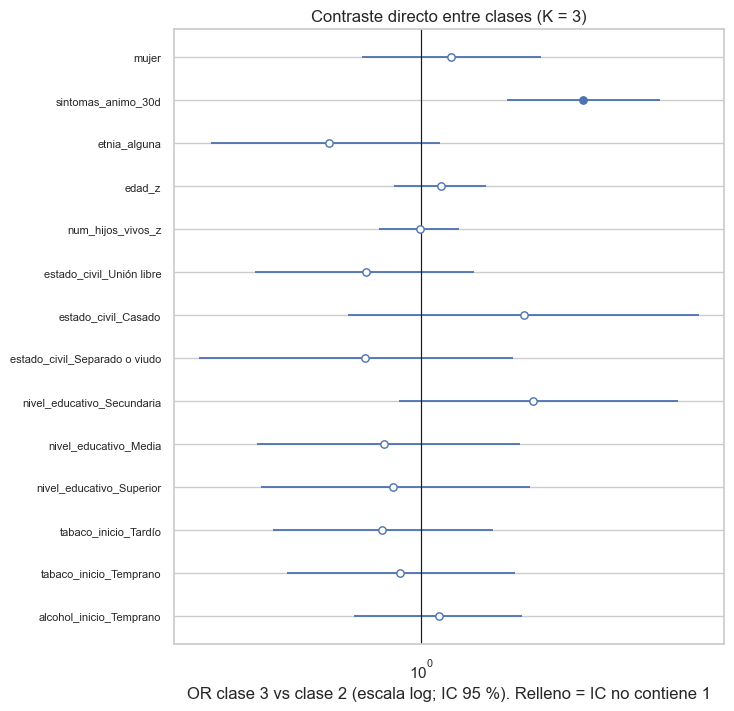

In [33]:
def contraste_3v2(r, nombres):
    b = np.asarray(r['beta']).reshape(-1, 2, len(nombres))
    OR2, OR3 = np.exp(b[:, 0]), np.exp(b[:, 1])
    OR32 = np.exp(b[:, 1] - b[:, 0])
    tab = pd.DataFrame({
        'covariable': nombres,
        'OR 2 vs 1 (mediana)': np.median(OR2, 0), 'OR 3 vs 1 (mediana)': np.median(OR3, 0),
        'cociente de medianas': np.median(OR3, 0) / np.median(OR2, 0),
        'OR 3 vs 2 (mediana)': np.median(OR32, 0),
        'IC2.5%': np.quantile(OR32, .025, 0), 'IC97.5%': np.quantile(OR32, .975, 0),
        'P(OR>1)': (OR32 > 1).mean(0)})
    tab['IC excluye 1'] = (tab['IC2.5%'] > 1) | (tab['IC97.5%'] < 1)
    return tab

tab_32 = contraste_3v2(resultados[3], nombres_X)
tab_32.round(3).to_csv(SALIDA + 'tabla_contraste_clase3_vs_clase2_K3.csv', index=False)
display(tab_32.round(3))

t = tab_32.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, .42 * len(t) + 1.4))
y = np.arange(len(t))
ax.errorbar(t['OR 3 vs 2 (mediana)'], y, xerr=[t['OR 3 vs 2 (mediana)'] - t['IC2.5%'], t['IC97.5%'] - t['OR 3 vs 2 (mediana)']],
            fmt='none', ecolor='#4c72b0', lw=1.3)
sig = t['IC excluye 1'].to_numpy()
ax.scatter(t['OR 3 vs 2 (mediana)'][sig], y[sig], color='#4c72b0', s=28, zorder=3)
ax.scatter(t['OR 3 vs 2 (mediana)'][~sig], y[~sig], facecolor='white', edgecolor='#4c72b0', s=28, zorder=3)
ax.axvline(1, c='k', lw=.8); ax.set_xscale('log')
ax.set_yticks(y); ax.set_yticklabels(t['covariable'], fontsize=8)
ax.set_xlabel('OR clase 3 vs clase 2 (escala log; IC 95 %). Relleno = IC no contiene 1')
ax.set_title('Contraste directo entre clases (K = 3)')
guardar_fig(fig, '11_contraste_clase3_vs_2_K3')

Lectura. Que un IC contra la clase 1 incluya 1 y otro no, por sí solo, no prueba que dos clases difieran entre sí, por eso se calcula exp(β3 − β2) con las cadenas. Solo los síntomas de ánimo diferencian la clase 3 de la 2 (OR 2,37, IC 95 %: 1,58 a 3,57). En las otras 13 covariables el IC incluye 1, la más cercana es el autorreconocimiento étnico (0,62; 0,33 a 1,11; P = 0,055), que no es concluyente. El cociente de medianas que usábamos antes (2,90/1,22) coincide con el contraste en la mediana pero no da intervalo.

## 20. Resultados para K = 3: figuras y tabla de odds ratios

In [34]:
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
COL = ['#4c72b0', '#dd8452', '#55a868', '#c44e52', '#8172b3', '#937860']
CARPETA = SALIDA + 'figuras'


def _guardar(fig, nombre):
    fig.tight_layout()
    if CARPETA:
        fig.savefig(os.path.join(CARPETA, nombre + '.png'), dpi=200, bbox_inches='tight')
    plt.show()


def _corto(items):
    return [str(i).replace('marihuana_', '').replace('_', ' ') for i in items]


def _pi(X, g, b):
    """g (S,K-1), b (S,K-1,P) -> pi (S,n,K)."""
    S, Km1 = g.shape
    eta = np.zeros((S, X.shape[0], Km1 + 1))
    eta[:, :, 1:] = g[:, None, :] + np.einsum('np,skp->snk', X, b)
    eta -= eta.max(2, keepdims=True)
    e = np.exp(eta)
    return e / e.sum(2, keepdims=True)


def _sub(r, S=400, seed=0):
    th = r['theta'].reshape(-1, *r['theta'].shape[2:])
    g = r['gamma'].reshape(-1, r['gamma'].shape[-1])
    b = r['beta'].reshape(-1, *r['beta'].shape[2:])
    idx = np.random.default_rng(seed).choice(len(th), min(S, len(th)), replace=False)
    return th[idx], g[idx], b[idx]


def _simular(pi, th, rng):
    """pi (S,n,K), th (S,K,J) -> y simulado (S,n,J)."""
    S, n, K = pi.shape
    u = rng.random((S, n, 1))
    cls = (u > np.cumsum(pi, 2)).sum(2).clip(0, K - 1)
    th_i = th[np.arange(S)[:, None], cls]
    return (rng.random(th_i.shape) < th_i).astype(int)


# 1. comparación de K
def fig_waic(resultados):
    Ks = sorted(resultados)
    v = np.array([resultados[k]['waic'] for k in Ks])
    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.bar([str(k) for k in Ks], v - v.min(), color=COL[0])
    for i, d in enumerate(v - v.min()):
        ax.text(i, d, f'{d:.1f}', ha='center', va='bottom', fontsize=9)
    ax.set_xlabel('K (número de clases)')
    ax.set_ylabel('WAIC ponderado − mínimo (menor = mejor)')
    ax.set_title('Comparación de modelos')
    _guardar(fig, '01_waic_por_K')


# 2. tamaños de clase
def fig_tamanos(r, X, w, K):
    th, g, b = _sub(r)
    pi = _pi(X, g, b)
    tam = (pi * w[None, :, None]).sum(1) / w.sum()          # (S,K) proporción poblacional (ponderada)
    fig, ax = plt.subplots(figsize=(5.5, 3.8))
    vp = ax.violinplot([tam[:, k] for k in range(K)], showmedians=True)
    for k, cuerpo in enumerate(vp['bodies']):
        cuerpo.set_facecolor(COL[k]); cuerpo.set_alpha(.7)
    ax.axhline(.05, ls='--', c='gray', lw=1)
    ax.text(K + .45, .05, '5 %', va='bottom', ha='right', fontsize=8, color='gray')
    ax.set_xticks(range(1, K + 1)); ax.set_xticklabels([f'Clase {k+1}' for k in range(K)])
    ax.set_ylabel('Proporción (posterior)'); ax.set_title('Tamaño de las clases')
    _guardar(fig, f'02_tamanos_K{K}')
    print(pd_resumen(tam, [f'Clase {k+1}' for k in range(K)]))


def pd_resumen(x, nombres):
    import pandas as pd
    return pd.DataFrame({'media': x.mean(0), 'IC2.5%': np.quantile(x, .025, 0),
                         'IC97.5%': np.quantile(x, .975, 0)}, index=nombres).round(3)


# 3. perfiles θ
def fig_perfiles(r, items, K):
    th = r['theta'].reshape(-1, K, len(items))
    m = th.mean(0)
    lo, hi = np.quantile(th, .025, 0), np.quantile(th, .975, 0)
    nombres = _corto(items)
    orden = np.argsort(m.mean(0))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1, 1.3]})
    ax = axes[0]
    im = ax.imshow(m[:, orden].T, cmap='viridis', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(K)); ax.set_xticklabels([f'C{k+1}' for k in range(K)])
    ax.set_yticks(range(len(items))); ax.set_yticklabels([nombres[i] for i in orden], fontsize=8)
    for i in range(len(items)):
        for k in range(K):
            ax.text(k, i, f'{m[k, orden[i]]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if m[k, orden[i]] < .6 else 'black')
    fig.colorbar(im, ax=ax, label='P(sí | clase)')
    ax.set_title('Perfil de cada clase (media posterior de θ)')
    ax = axes[1]
    y = np.arange(len(items))
    for k in range(K):
        ax.errorbar(m[k, orden], y + (k - (K - 1) / 2) * .18, xerr=[m[k, orden] - lo[k, orden], hi[k, orden] - m[k, orden]],
                    fmt='o', ms=4, lw=1, color=COL[k], label=f'Clase {k+1}')
    ax.set_yticks(y); ax.set_yticklabels([nombres[i] for i in orden], fontsize=8)
    ax.set_xlim(0, 1); ax.set_xlabel('θ (IC 95 %)'); ax.legend(frameon=False)
    ax.set_title('Incertidumbre de los perfiles')
    _guardar(fig, f'03_perfiles_K{K}')


# 4. OR de covariables
def fig_or(r, nombres_X, K):
    b = r['beta'].reshape(-1, K - 1, len(nombres_X))
    OR = np.exp(b)
    med, lo, hi = np.median(OR, 0), np.quantile(OR, .025, 0), np.quantile(OR, .975, 0)
    y = np.arange(len(nombres_X))
    fig, ax = plt.subplots(figsize=(8, .45 * len(nombres_X) + 1.5))
    for k in range(K - 1):
        d = (k - (K - 2) / 2) * .22
        sig = (lo[k] > 1) | (hi[k] < 1)
        ax.errorbar(med[k], y + d, xerr=[med[k] - lo[k], hi[k] - med[k]], fmt='none', ecolor=COL[k + 1], lw=1.3)
        ax.scatter(med[k][sig], (y + d)[sig], color=COL[k + 1], s=28, zorder=3, label=f'Clase {k+2} vs 1')
        ax.scatter(med[k][~sig], (y + d)[~sig], facecolor='white', edgecolor=COL[k + 1], s=28, zorder=3)
    ax.axvline(1, c='k', lw=.8); ax.set_xscale('log')
    ax.set_yticks(y); ax.set_yticklabels(nombres_X, fontsize=8); ax.invert_yaxis()
    ax.set_xlabel('Razón de odds (escala log; IC 95 %). Relleno = IC no contiene 1')
    h, l = ax.get_legend_handles_labels()
    ax.legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys(), frameon=False, loc='lower right')
    ax.set_title('Asociación de las covariables con la pertenencia a clase')
    _guardar(fig, f'04_OR_K{K}')
    import pandas as pd
    filas = [{'clase': f'{k+2} vs 1', 'covariable': n, 'OR': med[k, m], 'IC2.5%': lo[k, m], 'IC97.5%': hi[k, m],
              'P(OR>1)': (OR[:, k, m] > 1).mean()} for k in range(K - 1) for m, n in enumerate(nombres_X)]
    return pd.DataFrame(filas).round(3)


# 5. prior vs posterior
def fig_prior_posterior(r, nombres_X, items, K, p_j, c=3.0, sd_g=1.5, sd_b=1.0, cov=None):
    b = r['beta'].reshape(-1, K - 1, len(nombres_X))
    g = r['gamma'].reshape(-1, K - 1)
    th = r['theta'].reshape(-1, K, len(items))
    if cov is None:
        cov = [i for i, n in enumerate(nombres_X) if any(s in n.lower() for s in ('animo', 'inicio', 'tabaco', 'alcohol'))][:3] or [0, 1, 2]
    fig, axes = plt.subplots(3, K - 1, figsize=(4.2 * (K - 1), 9), squeeze=False)
    xs = np.linspace(-6, 6, 400)
    for k in range(K - 1):
        ax = axes[0, k]
        ax.hist(g[:, k], bins=50, density=True, color=COL[k + 1], alpha=.7, label='posterior')
        ax.plot(xs, stats.norm.pdf(xs, 0, sd_g), 'k--', label=f'prior N(0; {sd_g})')
        ax.set_title(f'γ clase {k+2} (intercepto)'); ax.legend(frameon=False, fontsize=8)
        ax = axes[1, k]
        for m in cov:
            ax.hist(b[:, k, m], bins=50, density=True, alpha=.45, label=nombres_X[m])
        ax.plot(xs, stats.norm.pdf(xs, 0, sd_b), 'k--', label=f'prior N(0; {sd_b})')
        ax.set_title(f'β clase {k+2} vs 1'); ax.legend(frameon=False, fontsize=7)
        ax = axes[2, k]
        j = int(np.argmax(np.abs(th[:, min(k + 1, K - 1), :].mean(0) - th[:, 0, :].mean(0))))
        t = np.linspace(.001, .999, 400)
        ax.hist(th[:, k + 1, j], bins=50, density=True, color=COL[k + 1], alpha=.7, label='posterior')
        ax.plot(t, stats.beta.pdf(t, c * p_j[j], c * (1 - p_j[j])), 'k--', label=f'prior Beta(c·p, c·(1−p)), c={c}')
        ax.set_title(f'θ clase {k+2}: {_corto(items)[j]}', fontsize=9); ax.legend(frameon=False, fontsize=7)
    _guardar(fig, f'05_prior_vs_posterior_K{K}')


# 6. trazas (convergencia)
def fig_trazas(r, nombres_X, K, cov=None):
    C = r['gamma'].shape[0]
    if cov is None:
        cov = [i for i, n in enumerate(nombres_X) if any(s in n.lower() for s in ('animo', 'inicio'))][:2] or [0, 1]
    series = [(f'γ clase {k+2}', r['gamma'][:, :, k]) for k in range(K - 1)]
    series += [(f'β clase {K} · {nombres_X[m]}', r['beta'][:, :, K - 2, m]) for m in cov]
    series += [('θ clase 1, ítem 1', r['theta'][:, :, 0, 0])]
    nc = 3
    nr = int(np.ceil(len(series) / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(14, 2.6 * nr), squeeze=False)
    for ax, (t, s) in zip(axes.ravel(), series):
        for c in range(C):
            ax.plot(s[c], lw=.4, alpha=.8)
        ax.set_title(t, fontsize=9)
    for ax in axes.ravel()[len(series):]:
        ax.axis('off')
    _guardar(fig, f'06_trazas_K{K}')


# 7. log-verosimilitud ponderada
def fig_loglik(r, Y, X, w, K, paso=10):
    C = r['theta'].shape[0]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    todas = []
    for c in range(C):
        th, g, b = r['theta'][c, ::paso], r['gamma'][c, ::paso], r['beta'][c, ::paso]
        out = []
        for i in range(0, len(th), 100):
            t = th[i:i + 100]
            ll = np.einsum('nj,skj->snk', Y, np.log(t)) + np.einsum('nj,skj->snk', 1 - Y, np.log1p(-t))
            lp = np.log(_pi(X, g[i:i + 100], b[i:i + 100]))
            out.append((w[None] * logsumexp(lp + ll, axis=2)).sum(1))
        v = np.concatenate(out)
        todas.append(v)
        axes[0].plot(v, lw=.6)
    axes[0].set_title('Log pseudo-verosimilitud ponderada (por cadena)'); axes[0].set_xlabel(f'iteración (cada {paso})')
    axes[1].hist(np.concatenate(todas), bins=40, color=COL[0])
    axes[1].set_title('Distribución a posteriori de la log-verosimilitud')
    _guardar(fig, f'07_loglik_K{K}')


# 8. certeza de la clasificación
def fig_clasificacion(r, Y, X, w, K):
    th, g, b = _sub(r, S=300)
    ll = np.einsum('nj,skj->snk', Y, np.log(th)) + np.einsum('nj,skj->snk', 1 - Y, np.log1p(-th))
    lp = ll + np.log(_pi(X, g, b))
    post = np.exp(lp - logsumexp(lp, axis=2, keepdims=True)).mean(0)       # (n,K)
    mx = post.max(1)
    ent = -(post * np.log(np.clip(post, 1e-12, 1))).sum(1)
    E = 1 - (w * ent).sum() / (w.sum() * np.log(K))                         # entropía relativa ponderada
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    axes[0].hist(mx, bins=30, color=COL[0]); axes[0].set_xlabel('máx. P(clase | datos) por persona')
    axes[0].set_title(f'Certeza de clasificación (entropía relativa = {E:.2f})')
    asign = post.argmax(1)
    for k in range(K):
        axes[1].hist(post[asign == k, k], bins=20, alpha=.6, color=COL[k], label=f'Clase {k+1} (n={int((asign==k).sum())})')
    axes[1].set_xlabel('P(clase asignada)'); axes[1].legend(frameon=False)
    _guardar(fig, f'08_clasificacion_K{K}')
    return post


# 9. chequeo predictivo: prior vs posterior vs observado
def fig_ppc_problemas(r, Y, X, K, p_j, c=3.0, sd_g=1.5, sd_b=1.0, S=300, seed=1):
    rng = np.random.default_rng(seed)
    n, J = Y.shape
    th, g, b = _sub(r, S=S)
    y_post = _simular(_pi(X, g, b), th, rng)
    gp = rng.normal(0, sd_g, (S, K - 1)); bp = rng.normal(0, sd_b, (S, K - 1, X.shape[1]))
    thp = rng.beta(c * p_j, c * (1 - p_j), (S, K, J))
    y_pri = _simular(_pi(X, gp, bp), thp, rng)
    ks = np.arange(J + 1)
    freq = lambda y: np.stack([np.bincount(y[s].sum(1), minlength=J + 1) / n for s in range(len(y))])
    obs = np.bincount(Y.sum(1).astype(int), minlength=J + 1) / n
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
    for ax, y, t in zip(axes, (y_pri, y_post), ('Predictiva a priori', 'Predictiva a posteriori')):
        f = freq(y)
        ax.fill_between(ks, np.quantile(f, .025, 0), np.quantile(f, .975, 0), color=COL[0], alpha=.3, label='banda 95 %')
        ax.plot(ks, f.mean(0), c=COL[0], label='media')
        ax.plot(ks, obs, 'ko-', ms=4, label='observado')
        ax.set_xlabel('número de problemas'); ax.set_title(t)
    axes[0].set_ylabel('proporción'); axes[1].legend(frameon=False)
    _guardar(fig, f'09_ppc_problemas_K{K}')


# 10. independencia local
def fig_ppc_pares(r, Y, X, items, K, pares=None, S=300, seed=2):
    rng = np.random.default_rng(seed)
    th, g, b = _sub(r, S=S)
    ys = _simular(_pi(X, g, b), th, rng)
    J = Y.shape[1]

    def phi(y):
        with np.errstate(invalid='ignore', divide='ignore'):
            return np.corrcoef(y.T)

    obs = phi(Y)
    sim = np.stack([phi(ys[s]) for s in range(len(ys))])
    resid = obs - np.nanmean(sim, 0)
    nombres = _corto(items)
    if pares is None:
        pares = [('tolerancia menor efecto', 'tolerancia mayor cantidad'),
                 ('uso para evitar problemas', 'sintomas al suspender'),
                 ('abandono actividades', 'mas tiempo consiguiendo recuperando')]
    fig = plt.figure(figsize=(15, 5))
    ax = fig.add_subplot(1, 2, 1)
    im = ax.imshow(resid, cmap='RdBu_r', vmin=-.3, vmax=.3)
    ax.set_xticks(range(J)); ax.set_yticks(range(J))
    ax.set_xticklabels(nombres, rotation=90, fontsize=7); ax.set_yticklabels(nombres, fontsize=7)
    fig.colorbar(im, ax=ax, label='φ observado − φ simulado')
    ax.set_title('Residuos de asociación entre ítems (≠ 0 → dependencia local)')
    sub = fig.add_gridspec(len(pares), 2, left=.58, right=.98, wspace=.3, hspace=.9)
    for i, (a, bb) in enumerate(pares):
        ia = next((k for k, n in enumerate(nombres) if a in n), None)
        ib = next((k for k, n in enumerate(nombres) if bb in n), None)
        if ia is None or ib is None:
            continue
        ax2 = fig.add_subplot(sub[i, :])
        ax2.hist(sim[:, ia, ib], bins=30, color=COL[0], alpha=.7)
        ax2.axvline(obs[ia, ib], c='k', lw=2)
        ax2.set_title(f'{a[:22]} / {bb[:22]}', fontsize=8); ax2.tick_params(labelsize=7)
    _guardar(fig, f'10_ppc_pares_K{K}')


# todo junto
def reporte(resultados, K, Y, X, w, items, nombres_X, **kw):
    r = resultados[K]
    Y = np.asarray(Y, float); X = np.asarray(X, float); w = np.asarray(w, float)
    p_j = np.clip(np.average(Y, axis=0, weights=w), .02, .98)
    fig_waic(resultados)
    fig_tamanos(r, X, w, K)
    fig_perfiles(r, items, K)
    tabla = fig_or(r, nombres_X, K)
    fig_prior_posterior(r, nombres_X, items, K, p_j, **kw)
    fig_trazas(r, nombres_X, K)
    fig_loglik(r, Y, X, w, K)
    post = fig_clasificacion(r, Y, X, w, K)
    fig_ppc_problemas(r, Y, X, K, p_j, **kw)
    fig_ppc_pares(r, Y, X, items, K)
    return tabla, post

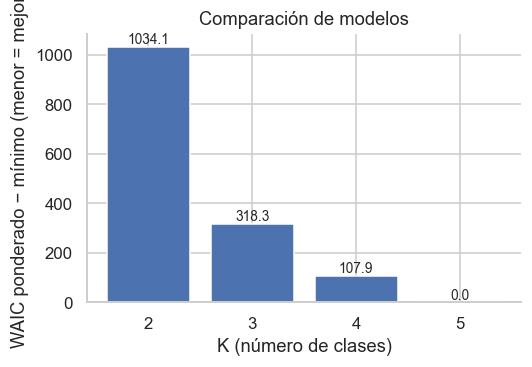

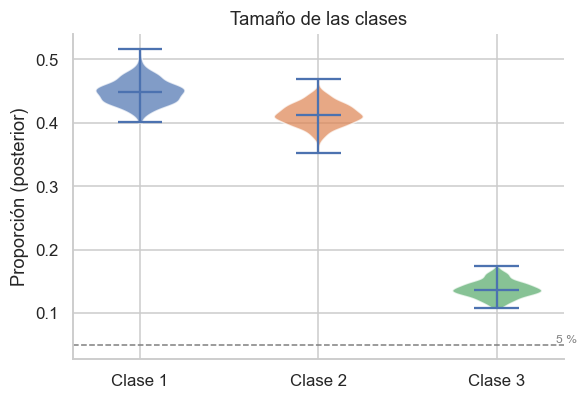

         media  IC2.5%  IC97.5%
Clase 1  0.449   0.414    0.488
Clase 2  0.413   0.378    0.446
Clase 3  0.138   0.112    0.165


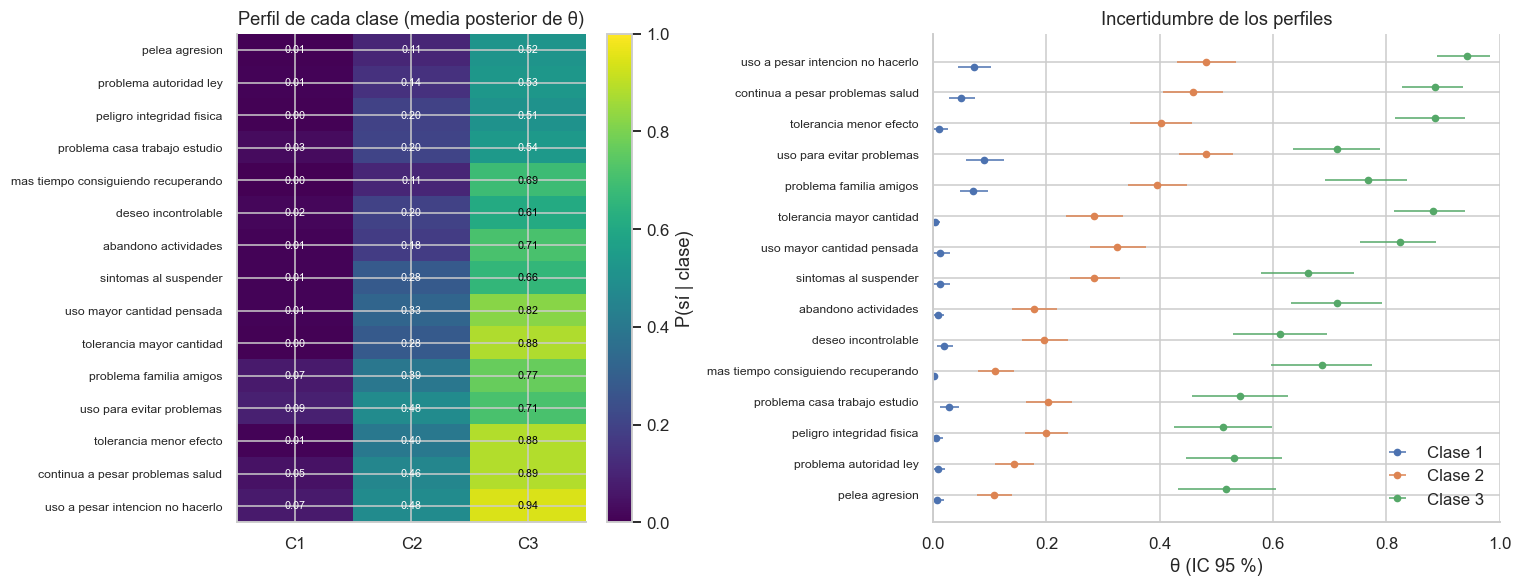

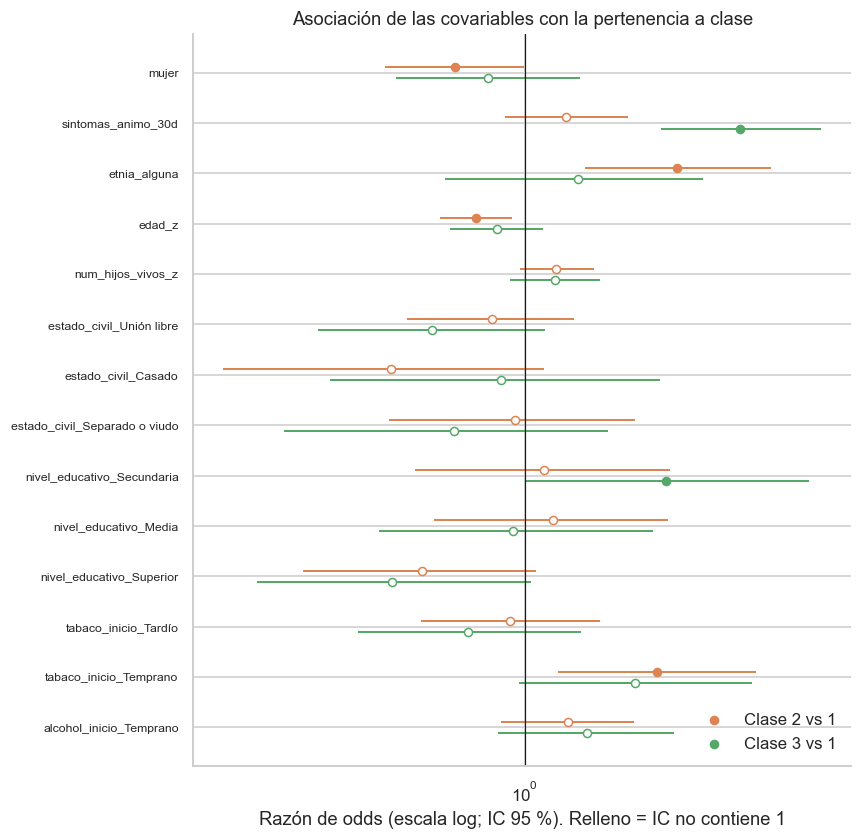

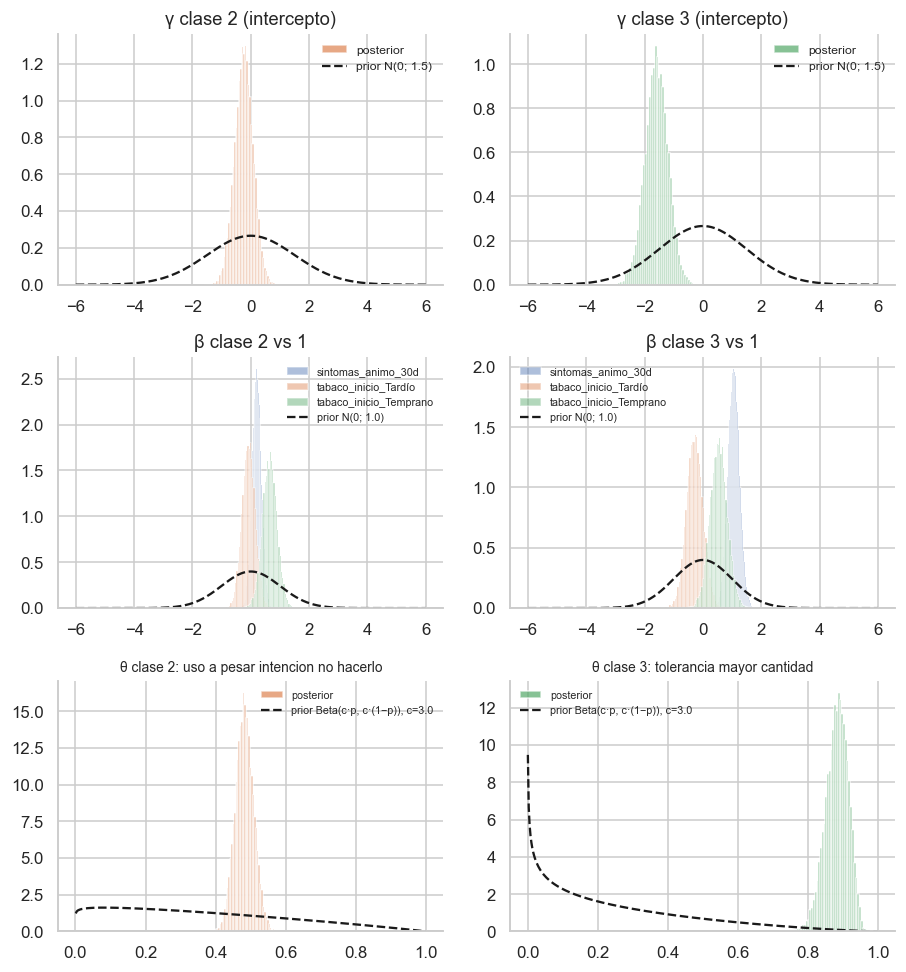

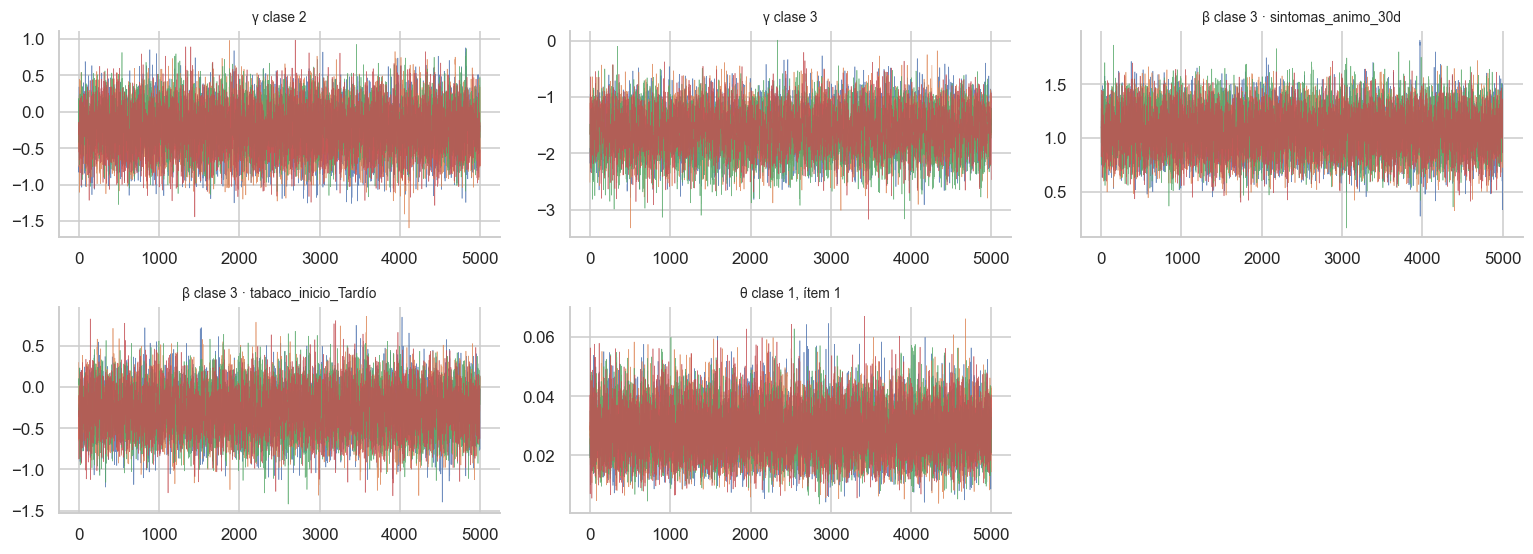

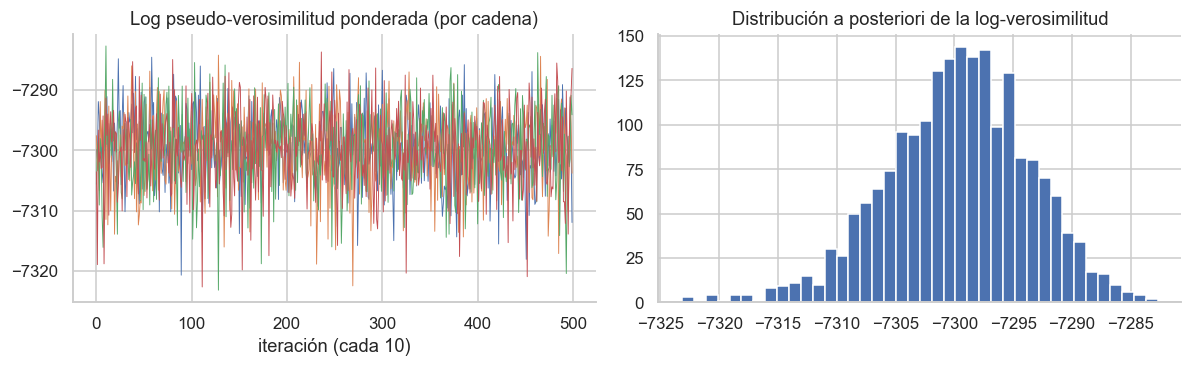

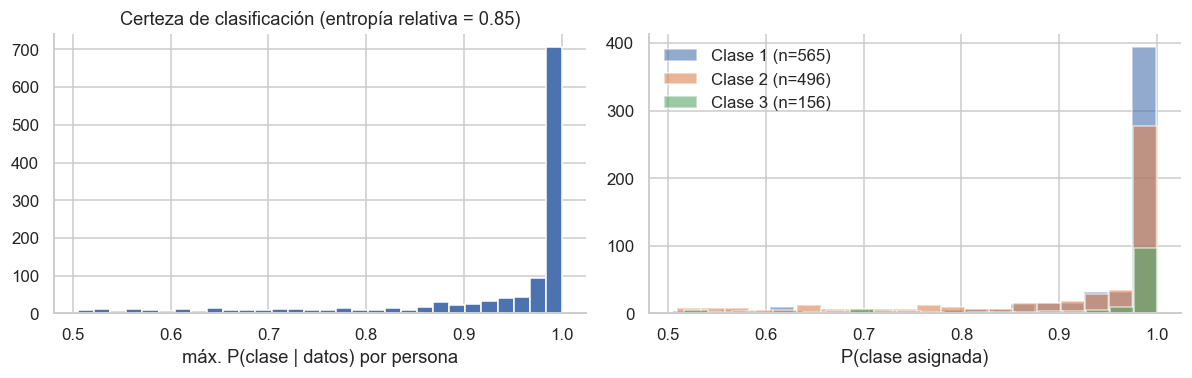

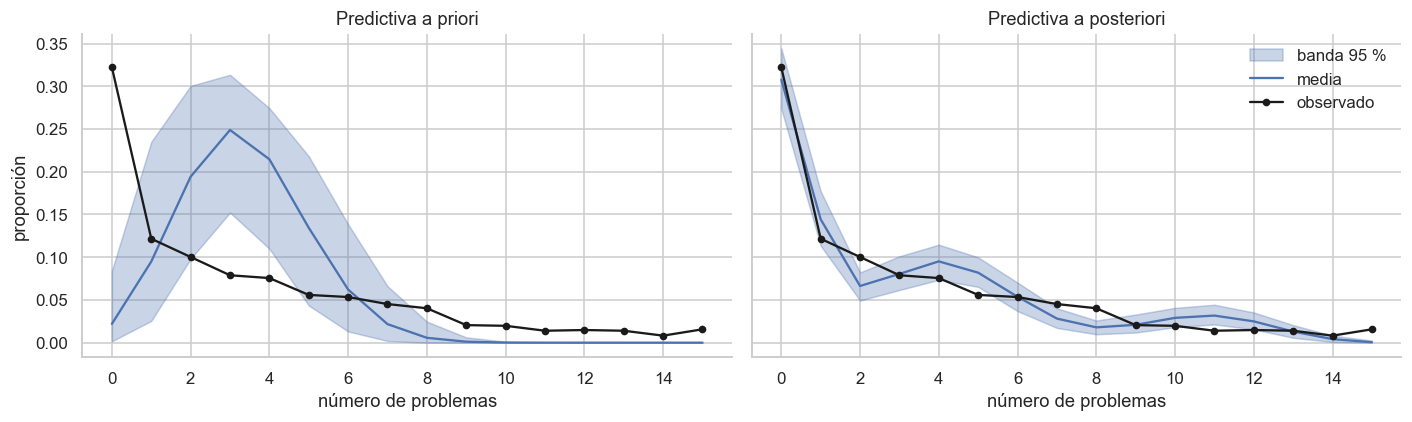

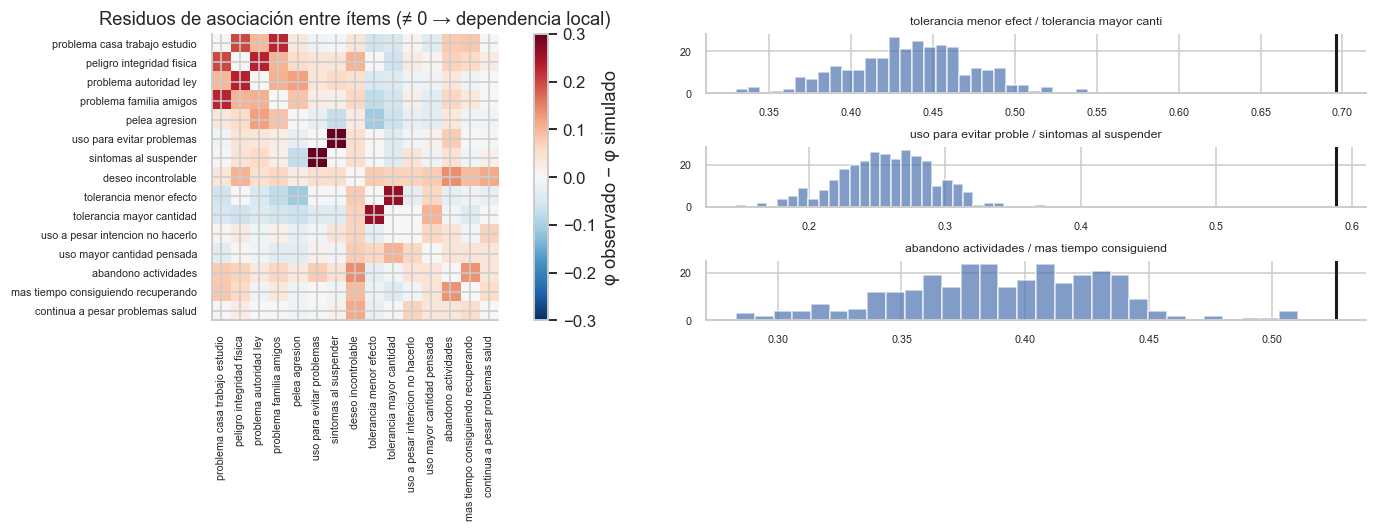

,clase,covariable,OR,IC2.5%,IC97.5%,P(OR>1)
0,2 vs 1,mujer,0.709,0.503,0.998,0.024
1,2 vs 1,sintomas_animo_30d,1.225,0.906,1.662,0.904
2,2 vs 1,etnia_alguna,2.119,1.347,3.363,1.000
3,2 vs 1,edad_z,0.786,0.658,0.937,0.003
4,2 vs 1,num_hijos_vivos_z,1.167,0.978,1.406,0.957
5,2 vs 1,estado_civil_Unión libre,0.849,0.559,1.273,0.218
6,2 vs 1,estado_civil_Casado,0.516,0.226,1.101,0.044
7,2 vs 1,estado_civil_Separado o viudo,0.952,0.512,1.723,0.438
8,2 vs 1,nivel_educativo_Secundaria,1.098,0.582,2.046,0.615
9,2 vs 1,nivel_educativo_Media,1.148,0.640,2.023,0.683


In [35]:
K = 3
tabla_or, post = reporte(resultados, K, Y, X, w, items, nombres_X)
tabla_or.to_csv(SALIDA + 'tabla_OR_K3.csv', index=False)
tabla_or

Lectura de los resultados con K = 3.

Perfiles. Los perfiles no se cruzan, θ de la clase 1 es menor o igual que la de la clase 2 y esta menor o igual que la de la 3 en los 15 ítems. Eso también lo produciría un único rasgo continuo de severidad (Baillie y Teesson, 2010), entonces no se puede hablar de tipos distintos de consumidores sino de una gradación resumida en tres perfiles. La clase 1 (45,1 %) tiene probabilidades de 0,09 o menos en todo. La clase 2 (41,2 %) va de 0,11 a 0,48 y se distingue más por el control del consumo que por las consecuencias sociales: está más cerca de la clase 3 en uso a pesar de la intención (0,48 frente a 0,94) y en continuar a pesar de problemas de salud (0,46 frente a 0,89), y mucho más lejos en pelea, tiempo consiguiendo la sustancia y problemas con la autoridad. La clase 3 (13,8 %) va de 0,51 a 0,94 y es la única donde los problemas conductuales y legales son frecuentes (cerca de 50 % o más).

Odds ratios. El de síntomas de ánimo para la clase 3 frente a la 1 es 2,90 (1,96 a 4,33) y es la única asociación con IC que excluye 1 con holgura. Para la clase 2 es débil (1,22; 0,91 a 1,66). Tabaco de inicio temprano: 1,92 (1,19 a 3,13) para la clase 2 y 1,71 (0,96 a 3,05) para la 3, sin diferencia demostrada entre ellas, lo que se parece más a un gradiente respecto de la clase 1. El inicio tardío no se asocia (0,93 y 0,75), o sea que lo que cuenta es empezar temprano y no haber fumado alguna vez. Alcohol temprano va en la misma dirección (1,24 y 1,36) pero no es concluyente, y como casi todos han probado alcohol hay poco contraste. La edad menor se asocia con la clase 2 (0,79 por cada 10 años más) y el autorreconocimiento étnico también (2,13), pero solo lo reportan 157 personas. Los IC anchos de casado (n = 49) y de hasta primaria (n = 105) apuntan a imprecisión por categorías pequeñas.

Cómo leer el conjunto. En 13 de las 14 covariables el signo es igual en los dos contrastes (la excepción es educación media), lo que encaja con una gradación. Se leen 28 odds ratios, así que los que apenas excluyen 1 (mujer, con límite superior de 0,997) pueden ser ruido, y es más prudente apoyarse en la consistencia entre clases, en la sensibilidad y en la literatura. Un OR de 2,9 no triplica la probabilidad de estar en la clase 3, el cambio en probabilidad depende de las demás covariables. Con datos transversales no se sabe si el ánimo bajo precede, acompaña o sigue a los problemas, la automedicación (Khantzian) es solo un marco interpretativo.

## 21. Cifras de clasificación y del número de problemas

In [36]:
# (la función simular_ppc se define en la sección 25; aquí se usa solo la clasificación)
th, g, b, C, D = aplanar(resultados[3], 3, 10)
ll = (np.einsum('nj,skj->snk', Y, np.log(np.clip(th, 1e-9, 1)))
      + np.einsum('nj,skj->snk', 1 - Y, np.log1p(-np.clip(th, 1e-9, 1 - 1e-9))))
lp = ll + np.log(pi_post(X, g, b))
post_clase = np.exp(lp - logsumexp(lp, axis=2, keepdims=True)).mean(0)
mx = post_clase.max(1)
ent = -(post_clase * np.log(np.clip(post_clase, 1e-12, 1))).sum(1)
npb = Y.sum(1)
print('P(clase modal) > 0,95: sin pesos', round((mx > .95).mean(), 3), '| ponderado', round((w * (mx > .95)).sum() / w.sum(), 3))
print('entropía relativa ponderada:', round(1 - (w * ent).sum() / (w.sum() * np.log(3)), 3),
      '| asignaciones modales:', np.bincount(post_clase.argmax(1)))
print('% con 0 problemas:', round((npb == 0).mean(), 3), '| var/media:', round(npb.var(ddof=1) / npb.mean(), 2))
print('asociación máxima ítems-covariables:', round(float(A.loc[[corto[c] for c in ITEMS], cov_cortas].max().max()), 3))

P(clase modal) > 0,95: sin pesos 0.695 | ponderado 0.707
entropía relativa ponderada: 0.847 | asignaciones modales: [564 497 156]
% con 0 problemas: 0.322 | var/media: 4.28
asociación máxima ítems-covariables: 0.212


Lectura. La entropía relativa ponderada es 0,85 y cerca de 70 % de las personas tiene probabilidad posterior mayor que 0,95 en su clase más probable, el resto se clasifica con más ambigüedad. Las asignaciones modales (565, 496 y 156) se parecen a las proporciones del modelo pero no son iguales, porque asignar a la clase más probable descarta la incertidumbre. La estimación conjunta propaga esa incertidumbre, que es la ventaja frente a asignar primero y regresar después (Bray et al., 2015; Vermunt, 2010).

# Sensibilidad

## 22. Priors

In [37]:
def or_texto(r, K, nombres, claves):
    OR = np.exp(np.asarray(r['beta']).reshape(-1, K - 1, len(nombres)))
    out = {}
    for k in range(K - 1):
        for c in claves:
            x = OR[:, k, nombres.index(c)]
            out[f'{c} | clase {k + 2} vs 1'] = f'{np.median(x):.2f} [{np.quantile(x, .025):.2f}, {np.quantile(x, .975):.2f}]'
    return out


def or_ampliado(r, K, nombres, claves, f):
    # ampliación simple de los IC por f en escala log (solo como ilustración)
    OR = np.exp(np.asarray(r['beta']).reshape(-1, K - 1, len(nombres)))
    out = {}
    for k in range(K - 1):
        for c in claves:
            x = OR[:, k, nombres.index(c)]
            med, lo, hi = np.median(x), np.quantile(x, .025), np.quantile(x, .975)
            h = f * np.log(hi / lo) / 2
            out[f'{c} | clase {k + 2} vs 1'] = f'{med:.2f} [{med * np.exp(-h):.2f}, {med * np.exp(h):.2f}]'
    return out


def tabla_or_completa(r, K, nombres):
    OR = np.exp(np.asarray(r['beta']).reshape(-1, K - 1, len(nombres)))
    filas = [{'clase': f'{k + 2} vs 1', 'covariable': nm, 'OR': np.median(OR[:, k, m]),
              'IC2.5%': np.quantile(OR[:, k, m], .025), 'IC97.5%': np.quantile(OR[:, k, m], .975),
              'P(OR>1)': (OR[:, k, m] > 1).mean()} for k in range(K - 1) for m, nm in enumerate(nombres)]
    return pd.DataFrame(filas)


especificaciones = [
    ('base (c=3, σβ=1)', 'prior_base', {}),
    ('c=2', 'prior_c2', dict(c=2.0)),
    ('c=6', 'prior_c6', dict(c=6.0)),
    ('σβ=0.5', 'prior_sb05', dict(sd_b=0.5)),
    ('σβ=2.5', 'prior_sb25', dict(sd_b=2.5)),
    ('θ ~ Beta(1,1)', 'prior_beta11', dict(uniforme=True)),
]
filas, post_sens = {}, {}
for nombre, tag, kw in especificaciones:
    r = posterior_cache(tag, Y, X, w, 3, **kw)
    post_sens[nombre] = r
    filas[nombre] = {**or_texto(r, 3, nombres_X, CLAVES), 'R-hat máx': f'{rhat_max2(r):.3f}'}
tabla_sens = pd.DataFrame(filas).T
tabla_sens.to_csv(SALIDA + 'tabla_sensibilidad_priors_K3.csv')
tabla_sens

prior_base (K=3): 65 s
prior_c2 (K=3): 63 s
prior_c6 (K=3): 63 s
prior_sb05 (K=3): 55 s
prior_sb25 (K=3): 72 s
prior_beta11 (K=3): 57 s


,sintomas_animo_30d | clase 2 vs 1,tabaco_inicio_Temprano | clase 2 vs 1,alcohol_inicio_Temprano | clase 2 vs 1,sintomas_animo_30d | clase 3 vs 1,tabaco_inicio_Temprano | clase 3 vs 1,alcohol_inicio_Temprano | clase 3 vs 1,R-hat máx
"base (c=3, σβ=1)","1.22 [0.90, 1.66]","1.92 [1.18, 3.12]","1.24 [0.89, 1.73]","2.90 [1.96, 4.32]","1.72 [0.98, 3.07]","1.36 [0.87, 2.09]",1.006
c=2,"1.22 [0.91, 1.64]","1.92 [1.18, 3.13]","1.24 [0.89, 1.72]","2.93 [1.97, 4.36]","1.71 [0.97, 3.05]","1.35 [0.87, 2.08]",1.006
c=6,"1.23 [0.90, 1.67]","1.92 [1.18, 3.16]","1.23 [0.88, 1.73]","2.79 [1.93, 4.12]","1.73 [0.98, 3.07]","1.39 [0.92, 2.10]",1.008
σβ=0.5,"1.20 [0.90, 1.62]","1.80 [1.14, 2.87]","1.24 [0.90, 1.70]","2.49 [1.74, 3.60]","1.62 [1.01, 2.61]","1.32 [0.90, 1.95]",1.032
σβ=2.5,"1.23 [0.91, 1.67]","1.97 [1.20, 3.24]","1.24 [0.89, 1.72]","3.09 [2.07, 4.67]","1.76 [0.94, 3.36]","1.38 [0.88, 2.16]",1.012
"θ ~ Beta(1,1)","1.25 [0.92, 1.68]","1.85 [1.16, 2.99]","1.28 [0.92, 1.76]","3.20 [2.12, 5.00]","1.73 [0.95, 3.24]","1.28 [0.82, 2.00]",1.019


Lectura. Las estimaciones casi no cambian con c = 2, 3 o 6 ni con Beta(1,1), entonces la prior de θ influye poco y centrarla en las prevalencias no condiciona la conclusión. La escala de β sí mueve algo, en la dirección esperada: con σβ = 0,5 el OR de ánimo se contrae a 2,49 y con σβ = 2,5 sube a 3,09. Cuatro corridas tienen R-hat entre 1,013 y 1,030, sobre 1,01 pero bajo 1,05.

## 23. Factor de expansión: sin pesos, pesos divididos por el deff y sándwich

In [38]:
deff_kish = float(np.mean(w ** 2))      # w tiene media 1, entonces deff = 1 + CV^2
n_ef = N_OBS / deff_kish
print(f'deff de Kish = {deff_kish:.2f} | n efectivo = {n_ef:.0f} | raíz del deff = {np.sqrt(deff_kish):.2f}')

post_peso = {
    'sin_pesos': posterior_cache('sin_pesos', Y, X, np.ones(N_OBS), 3),
    'pesos_deff': posterior_cache('pesos_deff', Y, X, w / deff_kish, 3),
}
for k_, r_ in post_peso.items():
    print(k_, '| R-hat máx =', round(rhat_max2(r_), 3))

deff de Kish = 2.02 | n efectivo = 603 | raíz del deff = 1.42
sin_pesos (K=3): 62 s
pesos_deff (K=3): 49 s
sin_pesos | R-hat máx = 1.007
pesos_deff | R-hat máx = 1.009


Con w dividido por el deff el tamaño efectivo es de unas 603 personas (deff de Kish 2,02, raíz 1,42).

### 23.1 Variables de diseño en los microdatos

Se revisan los archivos buscando columnas de estrato, segmento o conglomerado. Si no hay, el sándwich solo puede tratar a cada persona como su propio conglomerado y corrige únicamente la variación de los pesos.

In [39]:
ARCHIVOS = ['personas_seleccionadas.csv', 'd_capitulos.csv', 'd2_capitulos.csv', 'e_capitulos.csv',
            'f_capitulos.csv', 'k_capitulos.csv', 'l_capitulos.csv', 'm_capitulos.csv']
CAND = ['ESTRAT', 'UPM', 'CONGL', 'SEGMENT', 'PSU', 'CLUSTER', 'DPTO', 'DEPART', 'REGION', 'MPIO', 'ZONA', 'AREA']
filas, inventario = [], []
for f in ARCHIVOS:
    if not os.path.exists(RUTA + f):
        filas.append({'archivo': f, 'columnas': None, 'candidatas': 'no está en la carpeta', 'DIRECTORIO único': None})
        continue
    t = pd.read_csv(RUTA + f, sep=None, engine='python')
    t.columns = t.columns.str.strip().str.upper()
    filas.append({'archivo': f, 'columnas': t.shape[1],
                  'candidatas': [c for c in t.columns if any(p_ in c for p_ in CAND)],
                  'DIRECTORIO único': bool(t['DIRECTORIO'].is_unique) if 'DIRECTORIO' in t else None})
    for c in t.columns:
        inventario.append({'archivo': f, 'columna': c, 'dtype': str(t[c].dtype),
                           'n distintos': int(t[c].nunique(dropna=True)), '% vacíos': round(100 * t[c].isna().mean(), 1)})
pd.DataFrame(inventario).to_csv(SALIDA + 'inventario_columnas_capitulos.csv', index=False)
display(pd.DataFrame(filas))

,archivo,columnas,candidatas,DIRECTORIO único
0,personas_seleccionadas.csv,12,[],True
1,d_capitulos.csv,34,[],True
2,d2_capitulos.csv,11,[],True
3,e_capitulos.csv,16,[],True
4,f_capitulos.csv,37,[],True
5,k_capitulos.csv,48,[],True
6,l_capitulos.csv,41,[],True
7,m_capitulos.csv,38,[],True


Lectura. Ninguno de los archivos trae variable de segmento ni de estrato, y DIRECTORIO es único por persona. Pero la búsqueda es por nombre de columna, una variable con otro nombre no se detectaría. Por eso el sándwich solo corrige la variación de los pesos y no el efecto de los conglomerados, y los intervalos pueden seguir siendo algo angostos.

### 23.2 Corrección sándwich (Williams y Savitsky, 2021)

In [40]:
def a_phi(r, K, paso=1):
    th, g, b, C, D = aplanar(r, K, paso)
    th = np.clip(th, 1e-9, 1 - 1e-9)
    return np.concatenate([g, b.reshape(len(g), -1), logit(th).reshape(len(g), -1)], 1)

def de_phi(phi, K, Pc, Jc):
    S = phi.shape[0]
    g = phi[:, :K - 1]
    b = phi[:, K - 1:(K - 1) * (1 + Pc)].reshape(S, K - 1, Pc)
    th = expit(phi[:, (K - 1) * (1 + Pc):].reshape(S, K, Jc))
    return g, b, th

def loglik_y_score(phi, K, Yd, Xd):
    # log-verosimilitud por persona y su puntaje analítico respecto a (gamma, beta, logit theta)
    Pc, Jc = Xd.shape[1], Yd.shape[1]
    g = phi[:K - 1]; b = phi[K - 1:(K - 1) * (1 + Pc)].reshape(K - 1, Pc)
    th = expit(phi[(K - 1) * (1 + Pc):].reshape(K, Jc))
    eta = np.zeros((Xd.shape[0], K)); eta[:, 1:] = g + Xd @ b.T
    lp = eta - logsumexp(eta, axis=1, keepdims=True)
    lj = Yd @ np.log(th).T + (1 - Yd) @ np.log1p(-th).T
    lpost = lp + lj
    li = logsumexp(lpost, axis=1)
    rr = np.exp(lpost - li[:, None]); pi = np.exp(lp)
    de = rr[:, 1:] - pi[:, 1:]
    sc = np.concatenate([de, (de[:, :, None] * Xd[:, None, :]).reshape(len(de), -1),
                         (rr[:, :, None] * (Yd[:, None, :] - th[None])).reshape(len(de), -1)], 1)
    return li, sc

def hessiana(phi, K, Yd, Xd, wv, eps=1e-4):
    D = len(phi)
    grad = lambda f: (wv[:, None] * loglik_y_score(f, K, Yd, Xd)[1]).sum(0)
    Hm = np.empty((D, D))
    for j in range(D):
        e = np.zeros(D); e[j] = eps
        Hm[:, j] = -(grad(phi + e) - grad(phi - e)) / (2 * eps)
    return (Hm + Hm.T) / 2

def carne(score, wv):
    # sin variables de diseño: cada persona es su propio conglomerado
    N = len(wv)
    u = wv[:, None] * score
    tc = u - u.mean(0)
    return N / (N - 1) * tc.T @ tc, 0, N - 1


def ajuste_sandwich(r, K, Yd, Xd, wv, paso=1):
    Pc, Jc = Xd.shape[1], Yd.shape[1]
    phi = a_phi(r, K, paso)
    phi_hat = phi.mean(0)
    _, sc = loglik_y_score(phi_hat, K, Yd, Xd)
    H = hessiana(phi_hat, K, Yd, Xd, wv)
    ev = np.linalg.eigvalsh(H)
    if ev.min() <= 1e-8:
        H = H + (1e-6 - ev.min()) * np.eye(len(H))        # corrección mínima si H no es definida positiva
    Jm, solos, gl = carne(sc, wv)
    Hi = np.linalg.inv(H)
    V = Hi @ Jm @ Hi; V = (V + V.T) / 2
    Sp = np.cov(phi.T)
    jit = 1e-8 * np.trace(V) / len(V)
    # Con el orden (gamma, beta, theta) el bloque de beta del ajuste solo depende de los bloques de gamma y beta
    A = np.linalg.cholesky(V + jit * np.eye(len(V))) @ np.linalg.inv(np.linalg.cholesky(Sp))
    phi_adj = phi_hat + (phi - phi_hat) @ A.T
    g, b, th = de_phi(phi_adj, K, Pc, Jc)
    infl = np.sqrt(np.diag(V) / np.diag(Sp))               # razón de desviaciones estándar (sándwich / posterior)
    ib = slice(K - 1, (K - 1) * (1 + Pc))
    diag = {'eigen_min_H': float(ev.min()), 'estratos_con_una_UPM': solos, 'gl_diseno': gl, 'n_parametros': len(phi_hat),
            'infl_sd_beta_mediana': float(np.median(infl[ib])), 'infl_sd_beta_min': float(infl[ib].min()),
            'infl_sd_beta_max': float(infl[ib].max()), 'infl_sd_todos': infl}
    return {'gamma': g[None], 'beta': b[None], 'theta': th[None]}, diag

In [41]:
r_base = resultados[3]
specs = {'base (pseudo-verosimilitud ponderada)': r_base,
         'sin pesos': post_peso['sin_pesos'],
         'pesos / deff (n efectivo)': post_peso['pesos_deff']}

adj_p, diag_p = ajuste_sandwich(r_base, 3, Y, X, w)
specs['sándwich (solo variación de pesos)'] = adj_p
print(f"razón de desv. estándar de los beta (sándwich/posterior): mediana {diag_p['infl_sd_beta_mediana']:.2f}, "
      f"rango {diag_p['infl_sd_beta_min']:.2f}-{diag_p['infl_sd_beta_max']:.2f} | menor autovalor de H = {diag_p['eigen_min_H']:.3g}")
print(f'referencia: raíz del deff de Kish = {np.sqrt(deff_kish):.2f}')

filas = {nm: or_texto(r, 3, nombres_X, CLAVES) for nm, r in specs.items()}
filas['IC base ampliado por raíz del deff (aprox.)'] = or_ampliado(r_base, 3, nombres_X, CLAVES, np.sqrt(deff_kish))
tab_pesos = pd.DataFrame(filas).T
tab_pesos.to_csv(SALIDA + 'tabla_sensibilidad_factor_expansion_K3.csv')
display(tab_pesos)

tab_or_sandwich = tabla_or_completa(specs['sándwich (solo variación de pesos)'], 3, nombres_X).round(3)
tab_or_sandwich.to_csv(SALIDA + 'tabla_OR_K3_sandwich_conjunto.csv', index=False)
tab_32_sandwich = contraste_3v2(specs['sándwich (solo variación de pesos)'], nombres_X).round(3)
tab_32_sandwich.to_csv(SALIDA + 'tabla_contraste_clase3_vs_clase2_K3_sandwich.csv', index=False)

razón de desv. estándar de los beta (sándwich/posterior): mediana 4.46, rango 1.38-12.13 | menor autovalor de H = 0.0102
referencia: raíz del deff de Kish = 1.42


,sintomas_animo_30d | clase 2 vs 1,tabaco_inicio_Temprano | clase 2 vs 1,alcohol_inicio_Temprano | clase 2 vs 1,sintomas_animo_30d | clase 3 vs 1,tabaco_inicio_Temprano | clase 3 vs 1,alcohol_inicio_Temprano | clase 3 vs 1
base (pseudo-verosimilitud ponderada),"1.22 [0.91, 1.66]","1.92 [1.18, 3.12]","1.24 [0.89, 1.72]","2.90 [1.96, 4.32]","1.72 [0.97, 3.07]","1.36 [0.88, 2.09]"
sin pesos,"1.24 [0.91, 1.66]","1.46 [0.94, 2.30]","1.33 [0.98, 1.81]","3.33 [2.17, 5.17]","1.75 [0.94, 3.36]","1.15 [0.73, 1.82]"
pesos / deff (n efectivo),"1.21 [0.79, 1.87]","1.88 [0.95, 3.74]","1.24 [0.77, 1.98]","2.64 [1.56, 4.52]","1.66 [0.80, 3.52]","1.35 [0.76, 2.42]"
sándwich (solo variación de pesos),"1.23 [0.72, 2.10]","1.92 [0.78, 4.68]","1.23 [0.27, 5.48]","2.91 [0.25, 34.57]","1.72 [0.62, 4.87]","1.36 [0.23, 7.89]"
IC base ampliado por raíz del deff (aprox.),"1.22 [0.80, 1.88]","1.92 [0.96, 3.84]","1.24 [0.78, 1.97]","2.90 [1.65, 5.08]","1.72 [0.76, 3.89]","1.36 [0.73, 2.52]"


Lectura. Sin pesos el ánimo se mantiene (3,34; 2,19 a 5,14) pero el tabaco temprano de la clase 2 baja a 1,46 y su IC incluye 1 (0,94 a 2,31), o sea que depende de ponderar. Con pesos divididos por el deff los intervalos se ensanchan unas 1,4 veces: el ánimo sigue excluyendo 1 (2,64; 1,55 a 4,54) y el tabaco ya lo incluye (1,87; 0,95 a 3,75). El sándwich conjunto da una razón de desviaciones estándar con mediana 4,19 (1,37 a 11,32), mucho más que la raíz del deff, y intervalos como 0,28 a 31,27 para el ánimo. Eso no corresponde a la variación de los pesos y lo tomamos como un problema numérico, por eso esos intervalos no se usan para concluir.

### 23.3 Por qué el sándwich conjunto sale inestable, y versión condicional en (gamma, beta)

In [42]:
r0 = post_peso['sin_pesos']
K_, P_, J_ = 3, X.shape[1], Y.shape[1]
# con w = 1 sobre la posterior sin pesos la razón debería quedar cerca de 1
_, dg = ajuste_sandwich(r0, 3, Y, X, np.ones(N_OBS))
print('a) razón sd mediana (w=1, sin pesos):', round(dg['infl_sd_beta_mediana'], 2),
      '| rango', round(dg['infl_sd_beta_min'], 2), round(dg['infl_sd_beta_max'], 2))

# condición de la hessiana y parámetros que más pesan en los autovalores pequeños
phi = a_phi(resultados[3], 3)
ph = phi.mean(0)
nom_phi = ([f'g{k}' for k in range(K_ - 1)] + [f'b{k}_{c}' for k in range(K_ - 1) for c in nombres_X]
           + [f'logit_th{k}_{j}' for k in range(K_) for j in range(J_)])
H = hessiana(ph, 3, Y, X, w)
ev, vec = np.linalg.eigh(H)
print('b) autovalores mín/máx:', ev.min(), ev.max(), '| número de condición:', ev.max() / max(ev.min(), 1e-12))
for i in range(3):
    top = np.argsort(-np.abs(vec[:, i]))[:5]
    print(f'   autovalor {ev[i]:.4g}:', [(nom_phi[t], round(vec[t, i], 2)) for t in top])

# sensibilidad al paso de las diferencias finitas
for eps in (1e-3, 1e-5):
    Hc = hessiana(ph, 3, Y, X, w, eps=eps)
    print(f'c) eps={eps}: diferencia relativa de H =', round(np.linalg.norm(Hc - H) / np.linalg.norm(H), 4))

# sándwich condicional: solo el bloque (gamma, beta), con theta fijo en su media posterior
nb = (K_ - 1) * (1 + P_)
sl = slice(0, nb)
_, sc = loglik_y_score(ph, 3, Y, X)
Jm, _, _ = carne(sc, w)
Hi = np.linalg.inv(H[sl, sl])
Vbb = Hi @ Jm[sl, sl] @ Hi
Vbb = (Vbb + Vbb.T) / 2
razon_cond = np.sqrt(np.diag(Vbb) / np.diag(Hi))[slice(K_ - 1, nb)]
print('d) razón sd condicional sándwich/modelo (beta): mediana', np.median(razon_cond).round(2),
      'rango', razon_cond.min().round(2), razon_cond.max().round(2), '| raíz deff =', np.sqrt(deff_kish).round(2))

a) razón sd mediana (w=1, sin pesos): 1.05 | rango 1.0 1.42
b) autovalores mín/máx: 0.010162785255565552 554.2205173495383 | número de condición: 54534.3135186316
   autovalor 0.01016: [('logit_th0_1', np.float64(-0.78)), ('logit_th0_4', np.float64(-0.51)), ('logit_th0_6', np.float64(-0.27)), ('logit_th0_11', np.float64(-0.15)), ('logit_th0_8', np.float64(-0.09))]
   autovalor 0.0945: [('logit_th0_13', np.float64(-1.0)), ('logit_th0_1', np.float64(0.05)), ('logit_th0_4', np.float64(-0.01)), ('logit_th0_8', np.float64(-0.0)), ('b0_estado_civil_Casado', np.float64(0.0))]
   autovalor 0.1334: [('logit_th0_4', np.float64(-0.75)), ('logit_th0_1', np.float64(0.61)), ('logit_th0_6', np.float64(-0.19)), ('logit_th0_11', np.float64(-0.11)), ('logit_th0_8', np.float64(-0.06))]
c) eps=0.001: diferencia relativa de H = 0.0
c) eps=1e-05: diferencia relativa de H = 0.0
d) razón sd condicional sándwich/modelo (beta): mediana 1.31 rango 1.0 1.83 | raíz deff = 1.42


Lectura. Con w = 1 sobre la posterior sin pesos la razón debería ser cercana a 1 y sale 1,06 (0,98 a 1,43), entonces el código no parece tener un error. La hessiana está mal condicionada (autovalores de 0,011 a 554,4, número de condición cercano a 50.551) y los autovectores de menor autovalor caen sobre los logit de θ de la clase 1, donde todos los θ son 0,09 o menos. Es una explicación consistente con las salidas, no una demostración.

In [43]:
Sp = np.cov(phi[:, sl].T)
Aa = np.linalg.cholesky(Vbb + 1e-10 * np.eye(nb)) @ np.linalg.inv(np.linalg.cholesky(Sp))
adj = ph[sl] + (phi[:, sl] - ph[sl]) @ Aa.T
r_cond = {'gamma': adj[:, :K_ - 1][None], 'beta': adj[:, K_ - 1:].reshape(-1, K_ - 1, P_)[None],
          'theta': np.asarray(resultados[3]['theta']).reshape(1, -1, K_, J_)}
tab_cond = tabla_or_completa(r_cond, 3, nombres_X).round(3)
tab_cond.to_csv(SALIDA + 'tabla_OR_K3_sandwich_condicional.csv', index=False)
display(tab_cond[tab_cond['covariable'].isin(CLAVES)])
c32 = contraste_3v2(r_cond, nombres_X)
display(c32[c32['covariable'].isin(CLAVES)].round(3))

,clase,covariable,OR,IC2.5%,IC97.5%,P(OR>1)
1,2 vs 1,sintomas_animo_30d,1.225,0.811,1.855,0.828
12,2 vs 1,tabaco_inicio_Temprano,1.924,1.011,3.647,0.977
13,2 vs 1,alcohol_inicio_Temprano,1.237,0.805,1.899,0.836
15,3 vs 1,sintomas_animo_30d,2.887,1.504,5.646,0.999
26,3 vs 1,tabaco_inicio_Temprano,1.717,0.685,4.442,0.872
27,3 vs 1,alcohol_inicio_Temprano,1.363,0.753,2.439,0.851


,covariable,OR 2 vs 1 (mediana),OR 3 vs 1 (mediana),cociente de medianas,OR 3 vs 2 (mediana),IC2.5%,IC97.5%,P(OR>1),IC excluye 1
1,sintomas_animo_30d,1.225,2.887,2.357,2.363,1.191,4.740,0.992,True
12,tabaco_inicio_Temprano,1.924,1.717,0.892,0.891,0.343,2.372,0.408,False
13,alcohol_inicio_Temprano,1.237,1.363,1.101,1.099,0.596,2.010,0.620,False


Lectura. La versión condicional en (γ, β), con θ fijo en su media posterior, da una razón mediana de 1,31 (1,00 a 1,83), comparable con la raíz del deff, y por eso la presentamos como sensibilidad aproximada. Con ella el ánimo sigue excluyendo 1 (clase 3 vs 1: 2,90; 1,50 a 5,63 y clase 3 vs 2: 2,37; 1,19 a 4,72), el tabaco de la clase 2 queda en el borde (1,92; 1,02 a 3,65) y el alcohol incluye 1 en ambas clases. Al fijar θ se ignora parte de la incertidumbre conjunta, entonces obtener intervalos razonables no demuestra que tengan la cobertura nominal.

## 24. Dependencia local: ítems fusionados y compuesto psicosocial

In [44]:
def col_item(s):
    return next(k for k, i in enumerate(items) if s in i)

c_tol = [col_item('tolerancia_menor_efecto'), col_item('tolerancia_mayor_cantidad')]
c_abs = [col_item('uso_para_evitar_problemas'), col_item('sintomas_al_suspender')]
c_psi = [col_item('problema_casa_trabajo_estudio'), col_item('peligro_integridad_fisica'),
         col_item('problema_autoridad_ley'), col_item('problema_familia_amigos')]
print('Ítems del bloque psicosocial:', [items[k] for k in c_psi])

tol = Y[:, c_tol].max(1); abst = Y[:, c_abs].max(1)
psi_alguno = Y[:, c_psi].max(1); psi_dos = (Y[:, c_psi].sum(1) >= 2).astype(float)
print(f'Prevalencia: tolerancia {tol.mean():.3f} | abstinencia {abst.mean():.3f} | psicosocial "alguno" {psi_alguno.mean():.3f} | "dos o más" {psi_dos.mean():.3f}')

quitar13 = c_tol + c_abs
Y13 = np.column_stack([np.delete(Y, quitar13, axis=1), tol, abst])
items13 = [i for k, i in enumerate(items) if k not in quitar13] + ['marihuana_tolerancia', 'marihuana_abstinencia']

resto10 = [k for k in range(N_ITEMS) if k not in c_tol + c_abs + c_psi]
def armar10(psi):
    Yd = np.column_stack([Y[:, resto10], tol, abst, psi])
    return Yd, [items[k] for k in resto10] + ['marihuana_tolerancia', 'marihuana_abstinencia', 'marihuana_consecuencias_psicosociales']
Y10a, items10 = armar10(psi_alguno)
Y10b, _ = armar10(psi_dos)
print('Y13:', Y13.shape, '| Y10 (alguno):', Y10a.shape, '| Y10 (dos o más):', Y10b.shape)

Ítems del bloque psicosocial: ['marihuana_problema_casa_trabajo_estudio', 'marihuana_peligro_integridad_fisica', 'marihuana_problema_autoridad_ley', 'marihuana_problema_familia_amigos']
Prevalencia: tolerancia 0.318 | abstinencia 0.367 | psicosocial "alguno" 0.386 | "dos o más" 0.217
Y13: (1217, 13) | Y10 (alguno): (1217, 10) | Y10 (dos o más): (1217, 10)


In [45]:
modelos_dep = {'13 ítems': (Y13, items13),
               '10 ítems (psicosocial: alguno)': (Y10a, items10),
               '10 ítems (psicosocial: dos o más)': (Y10b, items10)}
tags_dep = {'13 ítems': 'dep_13items', '10 ítems (psicosocial: alguno)': 'dep_10items_alguno',
            '10 ítems (psicosocial: dos o más)': 'dep_10items_dos'}
post_dep = {'15 ítems (base)': resultados[3]}
for nombre, (Yd, its) in modelos_dep.items():
    post_dep[nombre] = posterior_cache(tags_dep[nombre], Yd, X, w, 3)
    print(nombre, '| R-hat máx =', round(rhat_max2(post_dep[nombre]), 3))

dep_13items (K=3): 67 s
13 ítems | R-hat máx = 1.022
dep_10items_alguno (K=3): 41 s
10 ítems (psicosocial: alguno) | R-hat máx = 1.009
dep_10items_dos (K=3): 43 s
10 ítems (psicosocial: dos o más) | R-hat máx = 1.01


## 25. Chequeos predictivos a posteriori

In [46]:
def simular_ppc(r, Yd, K, S=300, seed=2):
    rng = np.random.default_rng(seed)
    th, g, b, C, D = aplanar(r, K, 1)
    idx = rng.choice(len(g), S, replace=False)
    pi = pi_post(X, g[idx], b[idx])
    u = rng.random((S, N_OBS, 1))
    cls = (u > np.cumsum(pi, 2)).sum(2).clip(0, K - 1)
    th_i = th[idx][np.arange(S)[:, None], cls]
    return (rng.random(th_i.shape) < th_i).astype(float)

def ppc_pares_tabla(r, Yd, items_, K=3, S=300, seed=2):
    ys = simular_ppc(r, Yd, K, S, seed)
    with np.errstate(invalid='ignore', divide='ignore'):
        obs = np.corrcoef(Yd.T)
        sim = np.stack([np.corrcoef(ys[s].T) for s in range(S)])
    nombres = [str(i).replace('marihuana_', '') for i in items_]
    filas = []
    for a in range(Yd.shape[1]):
        for b_ in range(a + 1, Yd.shape[1]):
            v = sim[:, a, b_]; v = v[~np.isnan(v)]
            lo, hi = np.quantile(v, .025), np.quantile(v, .975)
            filas.append({'ítem A': nombres[a], 'ítem B': nombres[b_], 'phi observado': obs[a, b_],
                          'phi simulado (media)': v.mean(), 'banda 2.5%': lo, 'banda 97.5%': hi,
                          'residuo': obs[a, b_] - v.mean(), 'fuera de banda': bool(obs[a, b_] < lo or obs[a, b_] > hi)})
    return pd.DataFrame(filas).sort_values('residuo', ascending=False).reset_index(drop=True)

BLOQUE = ['problema_casa_trabajo_estudio', 'peligro_integridad_fisica', 'problema_autoridad_ley', 'problema_familia_amigos']
datos_dep = {'15 ítems (base)': (Y, items), **modelos_dep}
resumen, tablas_ppc = [], {}
for nombre, (Yd, its) in datos_dep.items():
    tp = ppc_pares_tabla(post_dep[nombre], Yd, its)
    tablas_ppc[nombre] = tp
    en_bloque = tp[tp['ítem A'].isin(BLOQUE) & tp['ítem B'].isin(BLOQUE)]
    resumen.append({'modelo': nombre, 'pares': len(tp), 'fuera de banda': int(tp['fuera de banda'].sum()),
                    'esperados por azar (5 %)': round(.05 * len(tp), 1), 'residuo máx': tp['residuo'].max(),
                    'residuo medio del bloque psicosocial': en_bloque['residuo'].mean() if len(en_bloque) else np.nan,
                    'pares del bloque fuera de banda': int(en_bloque['fuera de banda'].sum()) if len(en_bloque) else np.nan})
    tp.round(3).to_csv(SALIDA + 'tabla_ppc_pares_' + nombre.split(' (')[0].replace(' ', '_').replace('ítems', 'items') + ('_dos' if 'dos' in nombre else '') + '.csv', index=False)
resumen = pd.DataFrame(resumen).set_index('modelo')
resumen.round(3).to_csv(SALIDA + 'tabla_dependencia_local_resumen.csv')
display(resumen.round(3))

print('\nPares fuera de banda en el modelo de 15 ítems:')
display(tablas_ppc['15 ítems (base)'].query('`fuera de banda`').round(3))

,pares,fuera de banda,esperados por azar (5 %),residuo máx,residuo medio del bloque psicosocial,pares del bloque fuera de banda
modelo,,,,,,
15 ítems (base),105,20,5.2,0.331,0.161,6.0
13 ítems,78,14,3.9,0.226,0.152,6.0
10 ítems (psicosocial: alguno),45,4,2.2,0.120,NaN,NaN
10 ítems (psicosocial: dos o más),45,5,2.2,0.111,NaN,NaN



Pares fuera de banda en el modelo de 15 ítems:


,ítem A,ítem B,phi observado,phi simulado (media),banda 2.5%,banda 97.5%,residuo,fuera de banda
0,uso_para_evitar_problemas,sintomas_al_suspender,0.588,0.258,0.188,0.331,0.331,True
1,tolerancia_menor_efecto,tolerancia_mayor_cantidad,0.696,0.435,0.365,0.495,0.261,True
2,peligro_integridad_fisica,problema_autoridad_ley,0.461,0.226,0.148,0.306,0.235,True
3,problema_casa_trabajo_estudio,problema_familia_amigos,0.464,0.237,0.162,0.307,0.228,True
4,problema_casa_trabajo_estudio,peligro_integridad_fisica,0.409,0.214,0.143,0.305,0.195,True
5,deseo_incontrolable,abandono_actividades,0.451,0.308,0.227,0.393,0.143,True
6,abandono_actividades,mas_tiempo_consiguiendo_recuperando,0.526,0.392,0.297,0.483,0.134,True
7,problema_autoridad_ley,pelea_agresion,0.377,0.254,0.169,0.361,0.123,True
8,deseo_incontrolable,continua_a_pesar_problemas_salud,0.418,0.308,0.241,0.371,0.110,True
9,problema_autoridad_ley,problema_familia_amigos,0.355,0.247,0.180,0.326,0.108,True


Lectura de la independencia local. En el modelo de 15 ítems, cerca de 20 de los 105 pares quedan fuera de la banda de 95 % (el artículo reporta 20; por azar se esperarían 5,2), casi todos con residuo positivo. Los mayores son uso para evitar problemas con síntomas al suspender (φ = 0,59 frente a una banda de 0,19 a 0,33) y tolerancia por menor efecto con mayor cantidad (0,70 frente a 0,37 a 0,50). También queda fuera abandono de actividades con tiempo consiguiendo la sustancia (0,53). La banda por par no es una prueba formal y los pares no son independientes, pero la cifra es como cuatro veces la esperada, o sea que la clase latente no explica toda la asociación entre esos ítems, que probablemente miden casi lo mismo. Aparece además un segundo bloque que el EDA no había señalado, los cuatro ítems psicosociales, con seis pares fuera de banda y residuos de 0,10 a 0,23.

In [47]:
comp = pd.DataFrame({nm: or_texto(r, 3, nombres_X, CLAVES) for nm, r in post_dep.items()}).T
comp['R-hat máx'] = [f'{rhat_max2(r):.3f}' for r in post_dep.values()]
comp.to_csv(SALIDA + 'tabla_OR_clave_segun_dependencia_local_K3.csv')
display(comp)

tam_dep = pd.concat([tabla_tamanos(r, 3).assign(modelo=nm) for nm, r in post_dep.items()], ignore_index=True)
tam_dep.round(4).to_csv(SALIDA + 'tabla_tamanos_clase_por_modelo_dep.csv', index=False)
f1 = lambda v: f'{100 * v:.1f}'.replace('.', ',')
tam_dep['texto'] = [f'{f1(m_)} ({f1(a_)}–{f1(b_)})' for m_, a_, b_ in zip(tam_dep['media'], tam_dep['IC2.5%'], tam_dep['IC97.5%'])]
display(tam_dep.pivot(index='modelo', columns='clase', values='texto'))

,sintomas_animo_30d | clase 2 vs 1,tabaco_inicio_Temprano | clase 2 vs 1,alcohol_inicio_Temprano | clase 2 vs 1,sintomas_animo_30d | clase 3 vs 1,tabaco_inicio_Temprano | clase 3 vs 1,alcohol_inicio_Temprano | clase 3 vs 1,R-hat máx
15 ítems (base),"1.22 [0.91, 1.66]","1.92 [1.18, 3.12]","1.24 [0.89, 1.72]","2.90 [1.96, 4.32]","1.72 [0.97, 3.07]","1.36 [0.88, 2.09]",1.006
13 ítems,"1.24 [0.92, 1.68]","1.62 [1.00, 2.60]","1.33 [0.97, 1.84]","3.30 [2.10, 5.64]","1.81 [0.95, 3.55]","1.33 [0.81, 2.11]",1.022
10 ítems (psicosocial: alguno),"1.33 [0.98, 1.82]","1.55 [0.95, 2.56]","1.58 [1.13, 2.22]","2.53 [1.72, 3.70]","1.86 [1.05, 3.39]","1.25 [0.82, 1.91]",1.009
10 ítems (psicosocial: dos o más),"1.34 [0.98, 1.83]","1.74 [1.07, 2.86]","1.47 [1.05, 2.07]","2.62 [1.77, 3.96]","1.89 [1.04, 3.57]","1.31 [0.85, 2.06]",1.010


clase,1,2,3
modelo,,,
10 ítems (psicosocial: alguno),"45,3 (41,7–48,8)","39,9 (36,4–43,7)","14,8 (12,2–17,6)"
10 ítems (psicosocial: dos o más),"46,3 (42,5–50,0)","40,3 (36,6–44,1)","13,4 (10,8–16,3)"
13 ítems,"47,1 (43,4–50,9)","41,8 (38,4–45,0)","11,2 (8,4–14,2)"
15 ítems (base),"45,0 (41,5–48,8)","41,2 (37,8–44,6)","13,7 (11,4–16,2)"


Lectura. Con 13 ítems (tolerancia y abstinencia fusionadas) el bloque psicosocial persiste, y con 10 ítems la dependencia baja mucho (4 y 5 pares fuera de banda de 45, frente a 2,2 esperados) sin llegar al nivel del azar. La clase 3 oscila entre 11,1 y 14,9 %. La asociación con ánimo para la clase 3 se mantiene en todos los modelos (2,53 a 3,30, siempre con IC que excluye 1). Las de tabaco y alcohol no son estables: el OR de tabaco temprano en la clase 2 va de 1,92 a 1,63, 1,55 y 1,74, y el de alcohol temprano en la clase 2 pasa de 1,24 a 1,58 y 1,47 con IC que excluyen 1. Esos cambios aparecen al colapsar cuatro ítems en uno, lo que reduce información y cambia la composición de las clases, así que no los leemos como un efecto del alcohol sino como señal de que esas asociaciones dependen de la especificación. Los modelos reducidos son operacionalizaciones alternativas, no versiones más limpias del mismo modelo, y no elegimos uno por darnos una asociación más clara.

In [48]:
# perfiles theta de los modelos reducidos
casos = {'13 ítems': ('blca13', items13), '10 ítems (psicosocial: alguno)': ('10items_alguno', items10),
         '10 ítems (psicosocial: dos o más)': ('10items_dos', items10)}
base_num, _ = tabla_perfiles(post_dep['15 ítems (base)'], 3, items)
for nom, (tag, its) in casos.items():
    num, txt = tabla_perfiles(post_dep[nom], 3, its)
    num.round(3).to_csv(SALIDA + f'tabla_perfiles_theta_K3_{tag}.csv')
    txt.to_csv(SALIDA + f'tabla_perfiles_theta_K3_{tag}_IC.csv')
    cruza = not ((num['clase 1'] <= num['clase 2']) & (num['clase 2'] <= num['clase 3'])).all()
    comunes = num.index.intersection(base_num.index)
    print(f'\n{nom} | los perfiles se cruzan: {cruza}')
    display(txt)
    print('diferencia frente a 15 ítems (ítems comunes):')
    display((num.loc[comunes] - base_num.loc[comunes]).round(2))


13 ítems | los perfiles se cruzan: False


,clase 1,clase 2,clase 3
problema_casa_trabajo_estudio,0.03 (0.01-0.04),0.23 (0.18-0.28),0.57 (0.48-0.66)
peligro_integridad_fisica,0.00 (0.00-0.01),0.22 (0.18-0.26),0.56 (0.46-0.67)
problema_autoridad_ley,0.01 (0.00-0.02),0.16 (0.12-0.19),0.59 (0.47-0.71)
problema_familia_amigos,0.07 (0.05-0.10),0.42 (0.37-0.48),0.81 (0.73-0.88)
pelea_agresion,0.00 (0.00-0.01),0.13 (0.09-0.17),0.57 (0.48-0.66)
deseo_incontrolable,0.02 (0.01-0.03),0.22 (0.18-0.26),0.66 (0.55-0.78)
uso_a_pesar_intencion_no_hacerlo,0.06 (0.04-0.09),0.53 (0.48-0.59),0.96 (0.91-0.99)
uso_mayor_cantidad_pensada,0.01 (0.00-0.03),0.36 (0.31-0.42),0.87 (0.79-0.93)
abandono_actividades,0.01 (0.00-0.02),0.19 (0.15-0.24),0.81 (0.71-0.93)
mas_tiempo_consiguiendo_recuperando,0.00 (0.00-0.00),0.12 (0.09-0.17),0.78 (0.68-0.86)


diferencia frente a 15 ítems (ítems comunes):


,clase 1,clase 2,clase 3
problema_casa_trabajo_estudio,-0.00,0.02,0.03
peligro_integridad_fisica,-0.00,0.02,0.05
problema_autoridad_ley,0.00,0.02,0.06
problema_familia_amigos,-0.00,0.03,0.04
pelea_agresion,-0.00,0.02,0.05
deseo_incontrolable,-0.00,0.02,0.04
uso_a_pesar_intencion_no_hacerlo,-0.01,0.05,0.01
uso_mayor_cantidad_pensada,-0.00,0.04,0.04
abandono_actividades,-0.00,0.02,0.10
mas_tiempo_consiguiendo_recuperando,-0.00,0.02,0.09



10 ítems (psicosocial: alguno) | los perfiles se cruzan: False


,clase 1,clase 2,clase 3
pelea_agresion,0.01 (0.00-0.02),0.09 (0.06-0.12),0.52 (0.44-0.61)
deseo_incontrolable,0.02 (0.00-0.03),0.19 (0.15-0.23),0.62 (0.54-0.69)
uso_a_pesar_intencion_no_hacerlo,0.05 (0.03-0.08),0.49 (0.43-0.54),0.96 (0.91-0.99)
uso_mayor_cantidad_pensada,0.00 (0.00-0.01),0.33 (0.28-0.38),0.81 (0.73-0.88)
abandono_actividades,0.01 (0.00-0.02),0.14 (0.11-0.18),0.76 (0.69-0.84)
mas_tiempo_consiguiendo_recuperando,0.00 (0.00-0.01),0.10 (0.07-0.13),0.67 (0.58-0.76)
continua_a_pesar_problemas_salud,0.03 (0.01-0.05),0.46 (0.41-0.52),0.90 (0.85-0.95)
tolerancia,0.03 (0.01-0.05),0.46 (0.41-0.52),0.81 (0.74-0.88)
abstinencia,0.10 (0.07-0.13),0.54 (0.49-0.59),0.73 (0.65-0.80)
consecuencias_psicosociales,0.12 (0.09-0.15),0.52 (0.47-0.58),0.90 (0.85-0.95)


... (2 outputs left out)


10 ítems (psicosocial: dos o más) | los perfiles se cruzan: False


,clase 1,clase 2,clase 3
pelea_agresion,0.00 (0.00-0.02),0.11 (0.08-0.15),0.52 (0.44-0.61)
deseo_incontrolable,0.02 (0.01-0.03),0.20 (0.16-0.24),0.63 (0.54-0.71)
uso_a_pesar_intencion_no_hacerlo,0.05 (0.03-0.08),0.51 (0.46-0.57),0.96 (0.91-0.99)
uso_mayor_cantidad_pensada,0.01 (0.00-0.03),0.33 (0.28-0.38),0.86 (0.78-0.92)
abandono_actividades,0.01 (0.00-0.02),0.16 (0.12-0.21),0.77 (0.69-0.85)
mas_tiempo_consiguiendo_recuperando,0.00 (0.00-0.01),0.10 (0.07-0.14),0.73 (0.64-0.82)
continua_a_pesar_problemas_salud,0.03 (0.01-0.05),0.49 (0.43-0.54),0.90 (0.84-0.94)
tolerancia,0.04 (0.02-0.06),0.46 (0.41-0.51),0.87 (0.79-0.93)
abstinencia,0.11 (0.07-0.14),0.55 (0.50-0.60),0.74 (0.66-0.82)
consecuencias_psicosociales,0.03 (0.01-0.05),0.29 (0.25-0.34),0.69 (0.60-0.77)


diferencia frente a 15 ítems (ítems comunes):


,clase 1,clase 2,clase 3
pelea_agresion,-0.00,0.00,0.00
deseo_incontrolable,-0.00,0.00,0.01
uso_a_pesar_intencion_no_hacerlo,-0.02,0.03,0.02
uso_mayor_cantidad_pensada,-0.00,0.00,0.03
abandono_actividades,-0.00,-0.01,0.06
mas_tiempo_consiguiendo_recuperando,0.00,-0.01,0.04
continua_a_pesar_problemas_salud,-0.02,0.03,0.01


In [49]:
# pares fuera de banda de los modelos reducidos y par abandono / tiempo consiguiendo la sustancia
todas = []
for nom in ['13 ítems', '10 ítems (psicosocial: alguno)', '10 ítems (psicosocial: dos o más)']:
    tp = tablas_ppc[nom]
    fuera = tp[tp['fuera de banda']].round(3)
    print(f'\n{nom}: {len(fuera)} de {len(tp)} pares fuera de banda (por azar: {0.05 * len(tp):.1f})')
    display(fuera)
    todas.append(fuera.assign(modelo=nom))
pd.concat(todas).to_csv(SALIDA + 'tabla_ppc_pares_fuera_de_banda_modelos_reducidos.csv', index=False)

a_, b_ = 'abandono_actividades', 'mas_tiempo_consiguiendo_recuperando'
filas = [tp[((tp['ítem A'] == a_) & (tp['ítem B'] == b_)) | ((tp['ítem A'] == b_) & (tp['ítem B'] == a_))].assign(modelo=nom)
         for nom, tp in tablas_ppc.items()]
par = pd.concat([f for f in filas if len(f)])[['modelo', 'phi observado', 'phi simulado (media)', 'banda 2.5%', 'banda 97.5%', 'residuo', 'fuera de banda']]
par.round(3).to_csv(SALIDA + 'tabla_ppc_par_abandono_tiempo.csv', index=False)
display(par.round(3))


13 ítems: 14 de 78 pares fuera de banda (por azar: 3.9)


,ítem A,ítem B,phi observado,phi simulado (media),banda 2.5%,banda 97.5%,residuo,fuera de banda
0,problema_casa_trabajo_estudio,problema_familia_amigos,0.464,0.239,0.170,0.308,0.226,True
1,peligro_integridad_fisica,problema_autoridad_ley,0.461,0.241,0.156,0.326,0.220,True
2,problema_casa_trabajo_estudio,peligro_integridad_fisica,0.409,0.217,0.132,0.299,0.192,True
3,deseo_incontrolable,abandono_actividades,0.451,0.331,0.243,0.421,0.121,True
4,uso_mayor_cantidad_pensada,tolerancia,0.504,0.393,0.322,0.460,0.112,True
5,problema_autoridad_ley,pelea_agresion,0.377,0.266,0.177,0.361,0.111,True
6,deseo_incontrolable,tolerancia,0.420,0.311,0.236,0.376,0.109,True
7,deseo_incontrolable,continua_a_pesar_problemas_salud,0.418,0.312,0.250,0.380,0.106,True
8,problema_autoridad_ley,problema_familia_amigos,0.355,0.256,0.188,0.322,0.099,True
9,problema_casa_trabajo_estudio,problema_autoridad_ley,0.321,0.225,0.137,0.318,0.096,True



10 ítems (psicosocial: alguno): 4 de 45 pares fuera de banda (por azar: 2.2)


,ítem A,ítem B,phi observado,phi simulado (media),banda 2.5%,banda 97.5%,residuo,fuera de banda
0,uso_mayor_cantidad_pensada,tolerancia,0.504,0.385,0.319,0.460,0.120,True
1,deseo_incontrolable,tolerancia,0.420,0.307,0.228,0.378,0.113,True
2,deseo_incontrolable,abandono_actividades,0.451,0.354,0.264,0.439,0.098,True
4,deseo_incontrolable,continua_a_pesar_problemas_salud,0.418,0.338,0.266,0.402,0.080,True



10 ítems (psicosocial: dos o más): 5 de 45 pares fuera de banda (por azar: 2.2)


,ítem A,ítem B,phi observado,phi simulado (media),banda 2.5%,banda 97.5%,residuo,fuera de banda
0,deseo_incontrolable,abandono_actividades,0.451,0.340,0.251,0.426,0.111,True
1,uso_mayor_cantidad_pensada,tolerancia,0.504,0.396,0.327,0.469,0.108,True
2,deseo_incontrolable,tolerancia,0.420,0.316,0.231,0.380,0.104,True
3,pelea_agresion,consecuencias_psicosociales,0.364,0.263,0.179,0.337,0.102,True
4,deseo_incontrolable,continua_a_pesar_problemas_salud,0.418,0.328,0.250,0.397,0.090,True


,modelo,phi observado,phi simulado (media),banda 2.5%,banda 97.5%,residuo,fuera de banda
6,15 ítems (base),0.526,0.392,0.297,0.483,0.134,True
10,13 ítems,0.526,0.431,0.340,0.523,0.095,True
3,10 ítems (psicosocial: alguno),0.526,0.439,0.349,0.537,0.087,False
5,10 ítems (psicosocial: dos o más),0.526,0.443,0.351,0.548,0.082,False


In [50]:
JJ = Y.shape[1]; N = len(Y)
npb = Y.sum(1).astype(int)
ys = simular_ppc(resultados[3], Y, 3, S=300).sum(2)                    
dist_sim = np.stack([np.bincount(s.astype(int), minlength=JJ + 1) / N for s in ys])
obs = np.bincount(npb, minlength=JJ + 1) / N
lo, hi = np.percentile(dist_sim, 2.5, 0), np.percentile(dist_sim, 97.5, 0)

tab = pd.DataFrame({'n.º de problemas': np.arange(JJ + 1), 'observado': obs,
                    'media simulada': dist_sim.mean(0), 'banda 2,5 %': lo, 'banda 97,5 %': hi})
tab['dirección'] = np.where(obs > hi, 'por encima', np.where(obs < lo, 'por debajo', 'dentro'))
tab['desviación (obs − límite más cercano)'] = np.where(obs > hi, obs - hi, np.where(obs < lo, obs - lo, 0.0))
tab['desviación en personas (de 1.217)'] = (tab['desviación (obs − límite más cercano)'] * N).round(1)
with np.errstate(divide='ignore', invalid='ignore'):
    tab['observado / simulado'] = obs / dist_sim.mean(0)
display(tab.round(4))

fuera = tab.loc[tab['dirección'] != 'dentro', 'n.º de problemas'].tolist()
print('Valores fuera de banda:', fuera)
print('Por encima:', tab.loc[tab['dirección'] == 'por encima', 'n.º de problemas'].tolist(),
      '| por debajo:', tab.loc[tab['dirección'] == 'por debajo', 'n.º de problemas'].tolist())
tab.round(5).to_csv(SALIDA + 'tabla_ppc_n_problemas.csv', index=False)

,n.º de problemas,observado,media simulada,"banda 2,5 %","banda 97,5 %",dirección,desviación (obs − límite más cercano),desviación en personas (de 1.217),observado / simulado
0,0,0.3221,0.3101,0.2769,0.3459,dentro,0.0000,0.0,1.0389
1,1,0.1216,0.1416,0.1125,0.1718,dentro,0.0000,0.0,0.8588
2,2,0.1002,0.0654,0.0501,0.0830,por encima,0.0172,21.0,1.5339
3,3,0.0789,0.0814,0.0620,0.1027,dentro,0.0000,0.0,0.9692
4,4,0.0756,0.0955,0.0793,0.1151,por debajo,-0.0037,-4.5,0.7913
5,5,0.0559,0.0825,0.0641,0.0986,por debajo,-0.0082,-10.0,0.6771
6,6,0.0534,0.0533,0.0386,0.0695,dentro,0.0000,0.0,1.0029
7,7,0.0452,0.0283,0.0173,0.0411,por encima,0.0041,5.0,1.5991
8,8,0.0403,0.0180,0.0099,0.0267,por encima,0.0135,16.5,2.2317
9,9,0.0205,0.0205,0.0111,0.0320,dentro,0.0000,0.0,1.0003


Valores fuera de banda: [2, 4, 5, 7, 8, 11, 15]
Por encima: [2, 7, 8, 15] | por debajo: [4, 5, 11]


Lectura. El modelo reproduce la forma general del número de problemas (la masa en cero y el descenso inicial quedan dentro de la banda) pero no por completo: 7 de los 16 valores (2, 4, 5, 7, 8, 11 y 15) quedan fuera de la banda de 95 %. Las bandas son puntuales y los valores no son independientes, pero por azar se esperaría menos de uno. Lo más notable es la cola extrema, 1,56 % de las personas respondió sí a los 15 ítems frente a 0,06 % simulado. Entonces el modelo describe bien el patrón agregado que motivó el análisis, la sobredispersión y la masa en cero, pero no la distribución completa, y puede que se relacione con la dependencia local aunque no lo verificamos.

## 26. Modelos de 10 ítems con K = 2, 3 y 4

In [51]:
res10 = {}
for K in (2, 3, 4):
    res10[K] = posterior_cache('dep_10items_alguno', Y10a, X, w, K)
    print(K, 'R-hat máx', round(rhat_max2(res10[K]), 3), '| tamaños:', tabla_tamanos(res10[K], K)['media'].round(3).tolist())

dep_10items_alguno (K=2): 28 s
2 R-hat máx 1.001 | tamaños: [0.666, 0.334]
3 R-hat máx 1.009 | tamaños: [0.453, 0.399, 0.148]
dep_10items_alguno (K=4): 89 s
4 R-hat máx 1.294 | tamaños: [0.449, 0.32, 0.116, 0.115]


Lectura. Con 10 ítems el patrón por K se repite: R-hat máximo de 1,001, 1,009 y 1,372 para K = 2, 3 y 4, entonces K = 4 sigue sin converger incluso con menos dependencia local.

# Datos complementarios

## 27. Edad de inicio de 5 años o menos

In [52]:
d = df_modelo
t5 = (d['tabaco_alguna_vez'] == 1) & (d['tabaco_edad_inicio'] <= 5)
a5 = (d['alcohol_alguna_vez'] == 1) & (d['alcohol_edad_inicio'] <= 5)
print('tabaco:', int(t5.sum()), '| alcohol:', int(a5.sum()), '| ambas:', int((t5 & a5).sum()), '| personas únicas:', int((t5 | a5).sum()))

tabaco: 4 | alcohol: 9 | ambas: 0 | personas únicas: 13


Lectura. Son 4 personas de tabaco y 9 de alcohol con edad de inicio de 5 años o menos, sin personas en ambos grupos, 13 en total. Se tratan como tempranas pero no se interpreta su valor continuo.

## 28. Deff de Kish con todas las personas y deff implícito en los IC del DANE

In [53]:
raw = pd.read_csv(RUTA + 'personas_seleccionadas.csv', sep=None, engine='python')
raw.columns = raw.columns.str.strip().str.upper()
fx = pd.to_numeric(raw['FEX_C'].astype(str).str.strip().str.replace(',', '.', regex=False), errors='coerce')
print('Filas del archivo:', len(raw), '| FEX_C faltantes:', int(fx.isna().sum()))
fx = fx.dropna().to_numpy(float)

kish = lambda a: len(a) * np.sum(a ** 2) / np.sum(a) ** 2
deff_full, deff_sub = kish(fx), kish(np.asarray(w, float))
print(f'Deff de Kish, muestra completa (n = {len(fx):,}): {deff_full:.2f} | n efectivo = {len(fx) / deff_full:,.0f}')
print(f'Deff de Kish, 1.217 consumidores recientes (w):  {deff_sub:.2f} | n efectivo = {len(w) / deff_sub:,.0f}   (el artículo reporta 2,02 y 603)')
print(f'Suma de FEX_C = {fx.sum():,.0f} (la ficha técnica reporta 23.747.363 personas representadas)')

# Deff implícito de los IC publicados por el DANE (ficha técnica, prevalencias e incidencias de marihuana, total nacional).
# Supuestos: IC = ±1,96 errores estándar y muestreo aleatorio simple con n = personas con FEX_C. Es un cálculo orientativo.
pub = pd.DataFrame({'indicador': ['prevalencia vida', 'prevalencia año', 'prevalencia mes', 'incidencia año', 'incidencia mes'],
                    'p (%)': [8.30, 2.68, 1.78, 0.66, 0.22],
                    'semi-IC publicado (pp)': [0.37, 0.21, 0.17, 0.11, 0.06]})
n_ref = len(fx)
se_pub = pub['semi-IC publicado (pp)'] / 1.96
se_srs = np.sqrt(pub['p (%)'] / 100 * (1 - pub['p (%)'] / 100) / n_ref) * 100
pub['deff implícito'] = ((se_pub / se_srs) ** 2).round(2)
display(pub)
print(f"Deff implícito (media de los cinco): {pub['deff implícito'].mean():.2f}")
print(f"Deff total publicado / deff de Kish de los pesos: {pub['deff implícito'].mean() / deff_full:.2f}  "
      "(≈ 1: el efecto de diseño casi se explica por los pesos; > 1: queda efecto de conglomerados/estratos. Orden de magnitud, no una estimación formal.)")

Filas del archivo: 49756 | FEX_C faltantes: 0
Deff de Kish, muestra completa (n = 49,756): 2.11 | n efectivo = 23,533
Deff de Kish, 1.217 consumidores recientes (w):  2.02 | n efectivo = 603   (el artículo reporta 2,02 y 603)
Suma de FEX_C = 23,747,363 (la ficha técnica reporta 23.747.363 personas representadas)


,indicador,p (%),semi-IC publicado (pp),deff implícito
0,prevalencia vida,8.30,0.37,2.33
1,prevalencia año,2.68,0.21,2.19
2,prevalencia mes,1.78,0.17,2.14
3,incidencia año,0.66,0.11,2.39
4,incidencia mes,0.22,0.06,2.12


Deff implícito (media de los cinco): 2.23
Deff total publicado / deff de Kish de los pesos: 1.06  (≈ 1: el efecto de diseño casi se explica por los pesos; > 1: queda efecto de conglomerados/estratos. Orden de magnitud, no una estimación formal.)


Lectura. El deff de Kish de fex_c con las 49.756 personas es 2,11 (n efectivo 23.533), parecido al 2,02 de los 1.217 consumidores. El deff implícito en los IC publicados por el DANE va de 2,12 a 2,39 (media 2,23), y el cociente entre ambos es de 1,06, o sea que para esas cifras nacionales casi todo el efecto de diseño se explica por la desigualdad de los pesos. Es solo contexto, no se puede trasladar a los parámetros de este modelo ni sustituye las variables de diseño.

# Figuras del artículo

In [54]:
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

CARP_ART = SALIDA + 'figuras_articulo/'
os.makedirs(CARP_ART, exist_ok=True)


def coma(x, dec=1):
    return ('{:.%df}' % dec).format(x).replace('.', ',')


def fmt_eje(dec=1):
    return FuncFormatter(lambda v, _: coma(v, dec))


def guardar(fig, nombre):
    fig.savefig(CARP_ART + nombre, dpi=300, bbox_inches='tight', pad_inches=0.08, facecolor='white')
    plt.show()


CORTO = {
    'problema_casa_trabajo_estudio': 'Problemas en casa/trabajo/estudio',
    'peligro_integridad_fisica': 'Peligro para la integridad física',
    'problema_autoridad_ley': 'Problemas con autoridad o ley',
    'problema_familia_amigos': 'Problemas con familia o amigos',
    'pelea_agresion': 'Pelea o agresión',
    'uso_para_evitar_problemas': 'Uso para evitar problemas',
    'sintomas_al_suspender': 'Síntomas al suspender',
    'deseo_incontrolable': 'Deseo incontrolable',
    'tolerancia_menor_efecto': 'Tolerancia: menor efecto',
    'tolerancia_mayor_cantidad': 'Tolerancia: mayor cantidad',
    'uso_a_pesar_intencion_no_hacerlo': 'Uso pese a intención de no usar',
    'uso_mayor_cantidad_pensada': 'Uso en mayor cantidad de la pensada',
    'abandono_actividades': 'Abandono de actividades',
    'mas_tiempo_consiguiendo_recuperando': 'Tiempo consiguiendo/recuperando',
    'continua_a_pesar_problemas_salud': 'Continúa pese a problemas de salud',
}
CORTO_PAR = {
    'uso_para_evitar_problemas': 'Evitar problemas', 'sintomas_al_suspender': 'Síntomas al suspender',
    'tolerancia_menor_efecto': 'Tol. menor efecto', 'tolerancia_mayor_cantidad': 'Tol. mayor cantidad',
    'problema_casa_trabajo_estudio': 'Casa/trabajo/estudio', 'peligro_integridad_fisica': 'Integridad física',
    'problema_autoridad_ley': 'Autoridad/ley', 'problema_familia_amigos': 'Familia/amigos',
}
CORTO_COV = {
    'mujer': 'Mujer', 'sintomas_animo_30d': 'Síntomas de ánimo (30 d)', 'etnia_alguna': 'Autorreconocimiento étnico',
    'edad': 'Edad', 'num_hijos_vivos': 'N.º de hijos vivos', 'estado_civil': 'Estado civil',
    'nivel_educativo': 'Nivel educativo', 'tabaco_inicio': 'Inicio de tabaco', 'alcohol_inicio': 'Inicio de alcohol',
}

items_sin = [i.replace('marihuana_', '') for i in items]
prev_simple = Y.mean(0)
prev_pond = np.array([np.average(Y[:, j], weights=w) for j in range(N_ITEMS)])
orden_idx = list(np.argsort(-prev_simple, kind='stable'))
ORD = [items_sin[j] for j in orden_idx]
NOM = [CORTO[i] for i in ORD]
yy = np.arange(len(ORD))

Figura 1. Prevalencia de cada ítem, simple y ponderada.

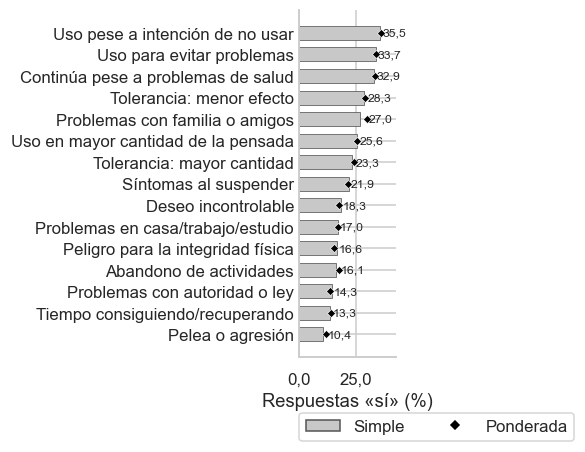

In [55]:
ps, pp = prev_simple[orden_idx] * 100, prev_pond[orden_idx] * 100
fig, ax = plt.subplots(figsize=(4.8, 4.0), layout='constrained')
ax.barh(yy, ps, height=0.65, color='#c8c8c8', edgecolor='#555555', linewidth=0.5, zorder=2)
ax.scatter(pp, yy, s=14, marker='D', color='black', edgecolor='white', linewidth=0.4, zorder=3)
for y_, s_, p_ in zip(yy, ps, pp):
    ax.text(max(s_, p_) + 0.8, y_, coma(s_, 1), va='center', ha='left', fontsize=8)
ax.set_yticks(yy)
ax.set_yticklabels(NOM)
ax.invert_yaxis()
ax.set_xlim(0, max(ps.max(), pp.max()) * 1.18)
ax.xaxis.set_major_formatter(fmt_eje(1))
ax.set_xlabel('Respuestas «sí» (%)')
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.legend(handles=[Patch(facecolor='#c8c8c8', edgecolor='#555555', label='Simple'),
                   Line2D([], [], marker='D', color='black', linestyle='', markersize=4, label='Ponderada')],
          loc='upper left', bbox_to_anchor=(0.0, -0.16), frameon=True, facecolor='white',
          edgecolor='#cccccc', borderaxespad=0, ncol=2)
guardar(fig, 'fig_prevalencias.png')

Las prevalencias simples y ponderadas son casi iguales, entre 10,4 % (pelea o agresión) y 35,5 % (uso pese a la intención de no usar).

Figura 2. Matriz de asociación entre los 15 ítems y las covariables.

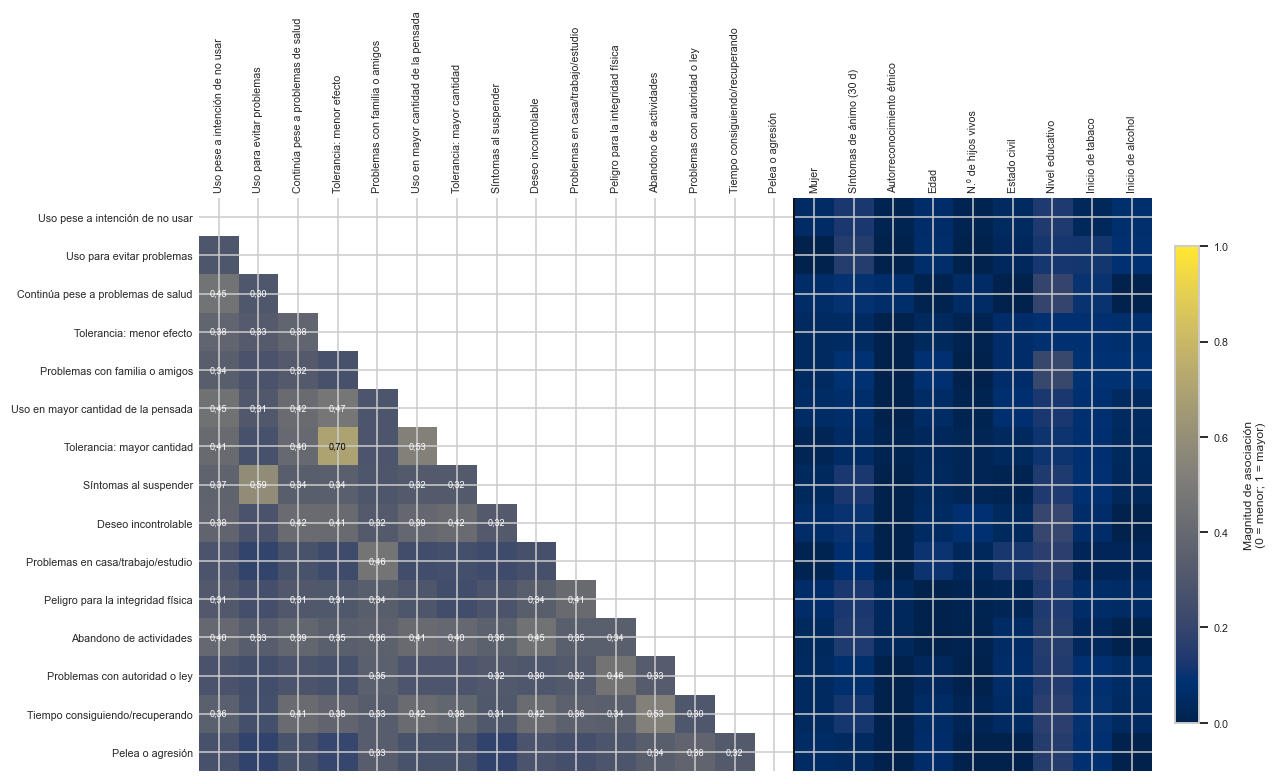

In [56]:
COV_TODAS = list(COV_BIN) + list(COV_NUM) + list(COV_CAT)
cols = ORD + COV_TODAS
M = A.loc[ORD, cols].astype(float).to_numpy().copy()
nI = len(ORD)
for i in range(nI):          # solo el triángulo inferior en el bloque ítems x ítems
    for j in range(nI):
        if j >= i:
            M[i, j] = np.nan

fig, ax = plt.subplots(figsize=(11.5, 7.0), layout='constrained')
cmap = plt.get_cmap('cividis').copy()
cmap.set_bad('white')
im = ax.imshow(M, cmap=cmap, vmin=0, vmax=1, aspect='auto', interpolation='nearest')
ax.set_xticks(range(len(cols)))
ax.set_xticklabels(NOM + [CORTO_COV[c] for c in COV_TODAS], rotation=90, fontsize=7, ha='center')
ax.set_yticks(range(nI))
ax.set_yticklabels(NOM, fontsize=7)
ax.xaxis.tick_top()
ax.tick_params(length=0, pad=4)
ax.axvline(nI - 0.5, color='black', linewidth=1.2)
for sp in ax.spines.values():
    sp.set_visible(False)
for i in range(nI):
    for j in range(len(cols)):
        v = M[i, j]
        if np.isfinite(v) and v >= 0.30:      # solo se anotan las asociaciones de 0,30 o más
            ax.text(j, i, coma(v, 2), ha='center', va='center', fontsize=6, color='white' if v < 0.62 else 'black')
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.025, ticks=np.linspace(0, 1, 6))
cb.set_label('Magnitud de asociación\n(0 = menor; 1 = mayor)', fontsize=8, labelpad=10)
cb.ax.tick_params(labelsize=7)
guardar(fig, 'fig_asociacion.png')

Se ven los tres pares redundantes (0,70; 0,59 y 0,53) y asociaciones bajas entre ítems y covariables (máximo 0,21).

Figura 3. Perfiles theta por clase (K = 3).

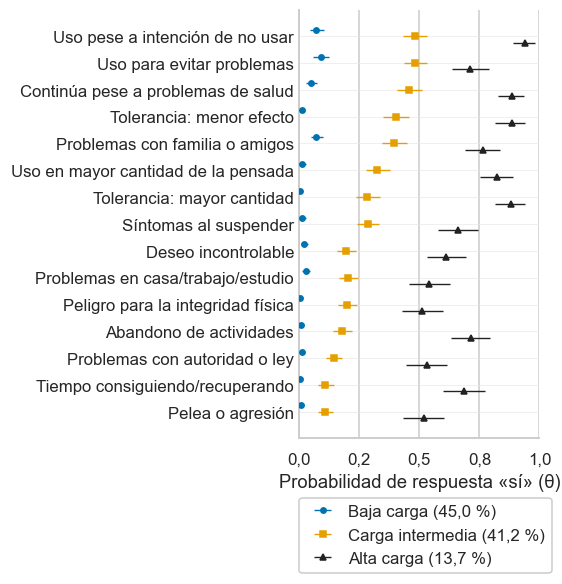

perfiles que se cruzan: []


In [57]:
r3 = resultados[3]
th3 = np.asarray(r3['theta']).reshape(-1, 3, N_ITEMS).astype(float)
m3, lo3, hi3 = th3.mean(0), np.quantile(th3, 0.025, 0), np.quantile(th3, 0.975, 0)
tam3 = np.asarray(tabla_tamanos(r3, 3)['media'], float)
etq = [f'Baja carga ({coma(tam3[0] * 100, 1)} %)', f'Carga intermedia ({coma(tam3[1] * 100, 1)} %)',
       f'Alta carga ({coma(tam3[2] * 100, 1)} %)']
estilos = [('#0072B2', 'o'), ('#E69F00', 's'), ('#222222', '^')]
desp = [-0.24, 0.0, 0.24]

fig, ax = plt.subplots(figsize=(5.0, 5.2), layout='constrained')
for k in range(3):
    mk, lk, hk = m3[k, orden_idx], lo3[k, orden_idx], hi3[k, orden_idx]
    ax.errorbar(mk, yy + desp[k], xerr=[mk - lk, hk - mk], fmt=estilos[k][1], color=estilos[k][0],
                ecolor=estilos[k][0], markersize=3.5, elinewidth=0.9, capsize=0, label=etq[k], zorder=3)
ax.set_yticks(yy)
ax.set_yticklabels(NOM)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(fmt_eje(1))
ax.set_xlabel('Probabilidad de respuesta «sí» (θ)')
ax.grid(axis='y', color='#e6e6e6', linewidth=0.4, zorder=0)
ax.set_axisbelow(True)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.legend(loc='upper left', bbox_to_anchor=(0.0, -0.14), frameon=True, framealpha=1,
          facecolor='white', edgecolor='#cccccc', handletextpad=0.5, borderaxespad=0, ncol=1)
guardar(fig, 'fig_perfiles.png')
print('perfiles que se cruzan:', [NOM[i] for i, j in enumerate(orden_idx) if not (m3[0, j] <= m3[1, j] <= m3[2, j])])

Los perfiles no se cruzan y las tres clases se leen como baja carga, carga intermedia (centrada en el control del consumo) y alta carga (problemas generalizados).

Figura 4. Chequeo predictivo del número de problemas.

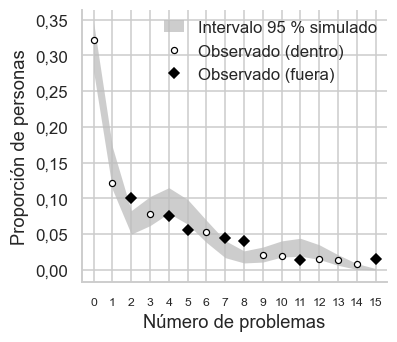

valores fuera de banda: [2, 4, 5, 7, 8, 11, 15] | por encima: [2, 7, 8, 15] | por debajo: [4, 5, 11]
15 problemas: observado 1,56 % | simulado 0,06 %


In [58]:
ys = simular_ppc(r3, Y, 3, S=300).sum(2)
dist_sim = np.stack([np.bincount(s.astype(int), minlength=N_ITEMS + 1) / N_OBS for s in ys])
obs = np.bincount(Y.sum(1).astype(int), minlength=N_ITEMS + 1) / N_OBS
lo4, hi4 = np.percentile(dist_sim, [2.5, 97.5], axis=0)
fuera = (obs > hi4) | (obs < lo4)
xk = np.arange(N_ITEMS + 1)

fig, ax = plt.subplots(figsize=(3.5, 3.0), layout='constrained')
ax.fill_between(xk, lo4, hi4, color='#bdbdbd', alpha=0.75, linewidth=0, label='Intervalo 95 % simulado', zorder=1)
ax.plot(xk[~fuera], obs[~fuera], 'o', mfc='white', mec='black', mew=0.8, ms=4, label='Observado (dentro)', zorder=3)
ax.plot(xk[fuera], obs[fuera], 'D', mfc='black', mec='black', ms=4.5, label='Observado (fuera)', zorder=4)
ax.set_xlabel('Número de problemas')
ax.set_ylabel('Proporción de personas')
ax.set_xticks(range(0, N_ITEMS + 1))
ax.tick_params(axis='x', labelsize=8)
ax.yaxis.set_major_formatter(fmt_eje(2))
ax.set_xlim(-0.6, N_ITEMS + 0.6)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
ax.legend(loc='upper right', frameon=False, handlelength=1.2, borderaxespad=0.2)
guardar(fig, 'fig_ppc_problemas.png')
print('valores fuera de banda:', [int(k) for k in xk[fuera]],
      '| por encima:', [int(k) for k in xk[obs > hi4]], '| por debajo:', [int(k) for k in xk[obs < lo4]])
print('15 problemas: observado', coma(obs[15] * 100, 2), '% | simulado', coma(dist_sim.mean(0)[15] * 100, 2), '%')

Los puntos negros son los valores donde lo observado sale de la banda simulada.

Figura 5. Chequeo predictivo por pares de ítems.

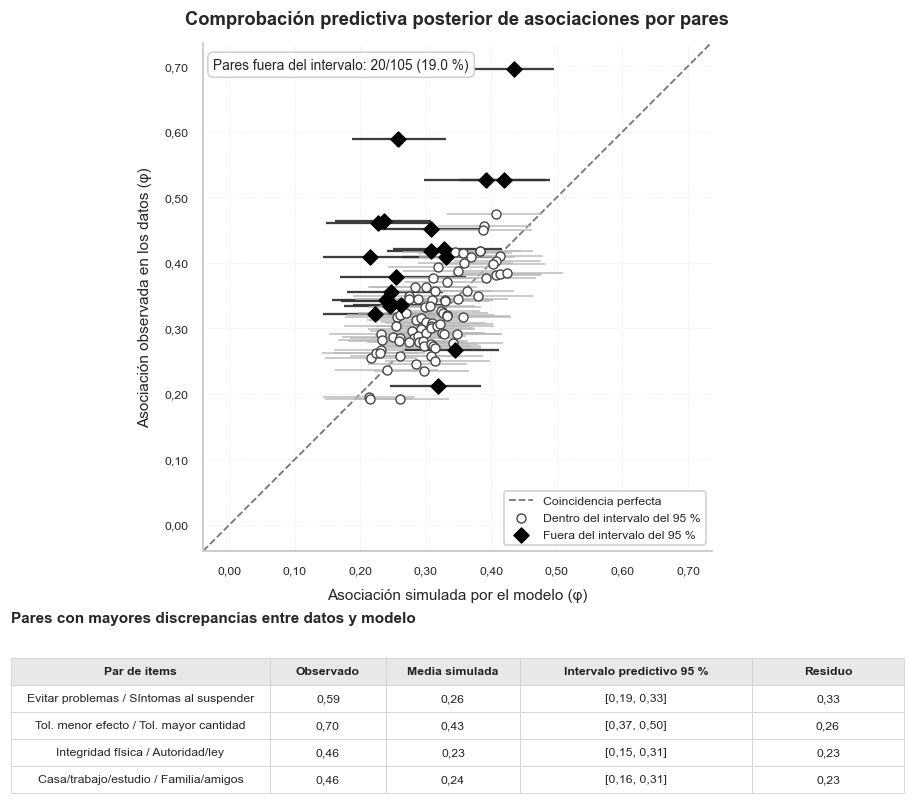

pares fuera de banda: 20 de 105 | residuo positivo: 18 | negativo: 2


In [59]:
tp = ppc_pares_tabla(r3, Y, items, K=3, S=300, seed=2)
ox, oy = tp['phi simulado (media)'].to_numpy(float), tp['phi observado'].to_numpy(float)
blo, bhi = tp['banda 2.5%'].to_numpy(float), tp['banda 97.5%'].to_numpy(float)
fb = tp['fuera de banda'].to_numpy(bool)
top4 = tp.loc[tp['residuo'].abs().nlargest(4).index]
nombre_par = lambda s: CORTO_PAR.get(s, CORTO.get(s, s))

fig = plt.figure(figsize=(8.2, 7.2), layout='constrained')
gs = fig.add_gridspec(2, 1, height_ratios=[4.8, 1.5])
ax, ax_tabla = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

valores = np.concatenate([ox, oy, blo, bhi])
valores = valores[np.isfinite(valores)]
lim_lo, lim_hi = min(valores.min(), 0) - 0.04, max(valores.max(), 0) + 0.04
ax.plot([lim_lo, lim_hi], [lim_lo, lim_hi], color='#777777', linewidth=1.2, linestyle='--',
        label='Coincidencia perfecta', zorder=1)
for i in range(len(tp)):       # intervalo predictivo de cada par
    ax.hlines(oy[i], blo[i], bhi[i], color='#333333' if fb[i] else '#b8b8b8',
              linewidth=1.5 if fb[i] else 1.0, alpha=0.95, zorder=2)
ax.scatter(ox[~fb], oy[~fb], s=35, marker='o', facecolors='white', edgecolors='#444444', linewidths=0.9,
           label='Dentro del intervalo del 95 %', zorder=3)
ax.scatter(ox[fb], oy[fb], s=48, marker='D', color='black', label='Fuera del intervalo del 95 %', zorder=4)
ax.set_xlim(lim_lo, lim_hi)
ax.set_ylim(lim_lo, lim_hi)
ax.set_xlabel('Asociación simulada por el modelo (φ)', fontsize=10, labelpad=8)
ax.set_ylabel('Asociación observada en los datos (φ)', fontsize=10, labelpad=8)
ax.set_title('Comprobación predictiva posterior de asociaciones por pares', fontsize=12, weight='bold', pad=12)
ax.xaxis.set_major_formatter(fmt_eje(2))
ax.yaxis.set_major_formatter(fmt_eje(2))
ax.tick_params(axis='both', labelsize=8)
ax.grid(True, linestyle=':', linewidth=0.6, alpha=0.45)
ax.set_aspect('equal', adjustable='box')
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
ax.text(0.02, 0.97, f'Pares fuera del intervalo: {int(fb.sum())}/{len(tp)} ({100 * fb.mean():.1f} %)',
        transform=ax.transAxes, ha='left', va='top', fontsize=9,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#cccccc', alpha=0.95))
ax.legend(loc='lower right', fontsize=8, frameon=True, framealpha=0.95, facecolor='white', edgecolor='#cccccc')

filas_tabla = [[nombre_par(f['ítem A']) + ' / ' + nombre_par(f['ítem B']), coma(f['phi observado'], 2),
                coma(f['phi simulado (media)'], 2), f"[{coma(f['banda 2.5%'], 2)}, {coma(f['banda 97.5%'], 2)}]",
                coma(f['residuo'], 2)] for _, f in top4.iterrows()]
ax_tabla.axis('off')
ax_tabla.set_title('Pares con mayores discrepancias entre datos y modelo', fontsize=10, weight='bold', loc='left', pad=8)
tabla = ax_tabla.table(cellText=filas_tabla,
                       colLabels=['Par de ítems', 'Observado', 'Media simulada', 'Intervalo predictivo 95 %', 'Residuo'],
                       cellLoc='center', colLoc='center', colWidths=[0.29, 0.13, 0.15, 0.26, 0.17], bbox=[0, 0, 1, 0.85])
tabla.auto_set_font_size(False)
tabla.set_fontsize(8)
tabla.scale(1, 1.35)
for (fila, columna), celda in tabla.get_celld().items():
    celda.set_edgecolor('#d0d0d0')
    celda.set_linewidth(0.5)
    celda.set_facecolor('#e8e8e8' if fila == 0 else 'white')
    if fila == 0:
        celda.set_text_props(weight='bold', color='#222222')
guardar(fig, 'fig_ppc_pares.png')
print('pares fuera de banda:', int(fb.sum()), 'de', len(tp), '| residuo positivo:', int(((oy > bhi) & fb).sum()),
      '| negativo:', int(((oy < blo) & fb).sum()))

Cada segmento es el intervalo que espera el modelo para la asociación de un par de ítems. Los rombos negros son los pares donde la asociación observada queda fuera, y la tabla de abajo muestra los cuatro con mayor residuo.

# Cierre

## Cifras clave para comparar con el artículo

La tabla pone lo que salió en esta corrida junto a lo que dice el artículo. Pequeñas diferencias (una décima) son error de Monte Carlo.

In [60]:
t3 = tabla_tamanos(resultados[3], 3)['media'].to_numpy() * 100
or_k3 = tabla_or.set_index(['clase', 'covariable'])
filas = [
    ('Tamaño clase 1 (%)', round(t3[0], 1), 45.1),
    ('Tamaño clase 2 (%)', round(t3[1], 1), 41.2),
    ('Tamaño clase 3 (%)', round(t3[2], 1), 13.8),
    ('R-hat máx K=3', round(rhat_max2(resultados[3]), 3), 1.007),
    ('OR ánimo, clase 3 vs 1', or_k3.loc[('3 vs 1', 'sintomas_animo_30d'), 'OR'], 2.90),
    ('OR tabaco temprano, clase 2 vs 1', or_k3.loc[('2 vs 1', 'tabaco_inicio_Temprano'), 'OR'], 1.92),
    ('OR ánimo, clase 3 vs 2', float(tab_32.set_index('covariable').loc['sintomas_animo_30d', 'OR 3 vs 2 (mediana)']), 2.37),
    ('Pares fuera de banda (15 ítems)', int(tablas_ppc['15 ítems (base)']['fuera de banda'].sum()), 20),
    ('Deff de Kish (consumidores)', round(deff_kish, 2), 2.02),
]
pd.DataFrame(filas, columns=['cifra', 'esta corrida', 'artículo']).round(3)

,cifra,esta corrida,artículo
0,Tamaño clase 1 (%),45.000,45.100
1,Tamaño clase 2 (%),41.200,41.200
2,Tamaño clase 3 (%),13.700,13.800
3,R-hat máx K=3,1.006,1.007
4,"OR ánimo, clase 3 vs 1",2.896,2.900
5,"OR tabaco temprano, clase 2 vs 1",1.924,1.920
6,"OR ánimo, clase 3 vs 2",2.367,2.370
7,Pares fuera de banda (15 ítems),20.000,20.000
8,Deff de Kish (consumidores),2.020,2.020


## Archivos generados

In [61]:
for carpeta, _, archivos in sorted(os.walk(SALIDA)):
    for a in sorted(archivos):
        print(os.path.join(carpeta, a))

resultados/base_blca.csv
resultados/blca_K2_dep_10items_alguno.npz
resultados/blca_K3_dep_10items_alguno.npz
resultados/blca_K3_dep_10items_dos.npz
resultados/blca_K3_dep_13items.npz
resultados/blca_K3_pesos_deff.npz
resultados/blca_K3_prior_base.npz
resultados/blca_K3_prior_beta11.npz
resultados/blca_K3_prior_c2.npz
resultados/blca_K3_prior_c6.npz
resultados/blca_K3_prior_sb05.npz
resultados/blca_K3_prior_sb25.npz
resultados/blca_K3_sin_pesos.npz
resultados/blca_K4_dep_10items_alguno.npz
resultados/blca_X.csv
resultados/blca_arrays.npz
resultados/blca_escala_covariables.csv
resultados/blca_flujo_muestra.csv
resultados/blca_posterior_K2.npz
resultados/blca_posterior_K3.npz
resultados/blca_posterior_K4.npz
resultados/blca_posterior_K5.npz
resultados/diagnostico_muestreo.csv
resultados/inventario_columnas_capitulos.csv
resultados/tabla2_prior_con_theta.csv
resultados/tabla2_prior_independiente_de_theta.csv
resultados/tabla_OR_K3.csv
resultados/tabla_OR_K3_sandwich_condicional.csv
resulta

## Conclusiones

Descripción. La muestra analítica es de 1.217 consumidores recientes, con datos faltantes insignificantes (0,41 % como máximo), un número de problemas muy sobredispersido (32 % sin ningún problema) y pares de ítems muy asociados que anticipaban la dependencia local.

Número de clases. K = 3 es el mayor K con convergencia limpia y clases de tamaño apreciable (45,1; 41,2 y 13,8 %). K = 4 y 5 no convergen. El WAIC y el LOO siguen mejorando al subir K pero no se usaron para decidir. K = 3 es la solución estable de referencia, no una demostración de que sea el número verdadero de clases.

Asociaciones. Los síntomas de ánimo bajo diferencian a la clase de alta carga de las otras dos (OR 2,90 frente a la clase 1 y 2,37 frente a la 2). El inicio temprano de tabaco se asocia con la clase de carga intermedia pero es frágil, y el de alcohol no es concluyente.

Sensibilidad. La asociación del ánimo resiste cambios de priors, de ítems, de K, de pesos y el sándwich condicional, mientras que las de tabaco y alcohol dependen de la especificación.

Ajuste. El modelo reproduce la forma agregada del número de problemas pero queda fuera de banda en 7 de 16 valores, y cerca de 20 de 105 pares de ítems violan la independencia local.

Limitaciones. Los datos son transversales y de autorreporte, las clases resumen una gradación y no entidades diagnósticas, la dependencia local no queda resuelta, no hay variables de diseño (los intervalos pueden ser optimistas y el sándwich conjunto es inestable), algunas corridas de sensibilidad tienen R-hat de 1,013 a 1,030 y hay categorías pequeñas con IC anchos. Los hallazgos son asociativos, válidos para consumidores recientes de 12 a 65 años en la cobertura de la ENCSPA 2019, y no son causales ni diagnósticos individuales. Un perfil estadístico no es un diagnóstico y no debe usarse para decidir sobre personas concretas.